In [1]:
# [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด
# ==================================================
# ทำอะไร: โน้ตบุ๊คนี้ฝึกโมเดล Random Forest (ป่าสุ่ม) ทายราคารถมือสองจากไฟล์ merge_50min_clean.csv
#         บนเครื่องของเราเองใน VS Code แล้วปรับค่าตั้งของโมเดล (hyperparameter) ด้วย cross-validation
#         และพิมพ์ผลบนชุด train / validation / test โดยไม่เขียนไฟล์ใดๆ ลงเครื่อง
#         ใช้ไฟล์ที่ทำความสะอาดภายนอกด้วยสคริปต์ data/main/clean_merged_min50.py (บันทึก: data/main/merge_50min_clean_steps.md); เซลล์ตรวจคุณภาพตรวจอย่างเดียว
#         เซลล์นี้เป็นทั้งคำอธิบายภาพรวมและที่รวม import ทั้งหมด (เซลล์อื่นไม่ import เพิ่ม)
#
# วิธีรัน:
#   1) ปิดโปรแกรมที่กินหน่วยความจำมากก่อน (เช่น แท็บเบราว์เซอร์จำนวนมาก) เพราะช่วงที่หนักที่สุด
#      โน้ตบุ๊คใช้หน่วยความจำราว 1.5-2 GB (ประมาณจากการทดลองเมื่อ 2026-10-23)
#   2) เปิดไฟล์นี้ใน VS Code แล้วกด "Select Kernel" มุมขวาบน เลือก Python ของ research/.venv
#      (D:/AI_Workspace/car-project/research/.venv/Scripts/python.exe)
#   3) กด "Run All" แล้วรอจนเซลล์สุดท้าย [40] พิมพ์ผลสรุป
#      เวลาที่คาดไว้ประมาณ 15-25 นาทีบนเครื่องนี้ (ประมาณจาก pilot เมื่อ 2026-10-23 ไม่ใช่การวัดจริงของ
#      ทั้งโน้ตบุ๊ค) ส่วนที่นานที่สุดคือ grid search ในเซลล์ [26] ช่วงนั้นเซลล์จะเงียบเป็นเรื่องปกติ
#   4) ถ้าเซลล์ไหน error ให้หยุดอ่านข้อความ error ก่อน อย่ากดรันต่อ เพราะเซลล์ถัดไปใช้ผลของเซลล์ก่อนหน้า
#
# แผนที่ของโน้ตบุ๊ค (เลขในวงเล็บคือเลขเซลล์):
#   - ตั้งค่าและอ่านข้อมูล             [01]-[04]
#   - ตรวจคุณภาพข้อมูล                 [05]-[11]
#   - เตรียมข้อมูลและแบ่งชุด           [12]-[14]
#   - ความสัมพันธ์ระหว่างตัวแปรทีละคู่  [15]-[17]
#   - โมเดลและ grid                    [18]-[22]
#   - grid search ด้วยกฎ 1-SE          [23]-[28]
#   - วัดผล                            [29]-[31]
#   - การตรวจเพิ่มเติม                 [32]-[39]
#   - สรุปการตรวจ overfit              [40]
#
# ต่างจากโน้ตบุ๊ค RF ต้นฉบับ (clean_v3_v4/v4_RF.ipynb) (เหตุผลอยู่ในคอมเมนต์ของแต่ละเซลล์):
#   - รันบนเครื่องใน VS Code เท่านั้น ไม่เชื่อม Google Drive และไม่มีโหมด SMOKE            [02]
#   - ไม่เปลี่ยนชื่อคอลัมน์                                                          [12]
#   - ไม่มีขั้นคัดเลือกตัวแปร (feature selection)                                   [18]
#   - จำนวนต้นไม้ (n_estimators) ตั้งตายตัวตรงที่ OOB error แบนแล้ว ไม่ปรับใน grid      [03], [38]-[39]
#   - ออกแบบ grid ใหม่จาก pilot ให้ครอบจุดต่ำสุดของ CV MAE                           [21]
#   - เลือกผู้ชนะด้วยกฎ 1-SE คือเลือกป่าที่มีใบรวมน้อยที่สุด
#     ในช่วงหนึ่ง SE จากค่า MAE ต่ำสุด แทนการเลือก MAE ต่ำสุดตรงๆ (refit="MAE")          [22]-[27]
#   - เพิ่มการตรวจที่ต้นฉบับไม่มี:
#       คุณภาพข้อมูล [05]-[11], ความสัมพันธ์ทีละคู่ [15]-[17], ขอบ grid [28],
#       ตาราง 10 อันดับแรก [32], learning curve [33]-[34], CV train เทียบ validation [35],
#       validation curve [36]-[37], กราฟ OOB [38]-[39], สรุปการตรวจ overfit [40]
#
# ต่างจากโน้ตบุ๊ค DT (v4_DT) ที่เป็นต้นแบบของโครงสร้างนี้:
#   - ไม่มีขั้นเลือก ccp_alpha เพราะ Random Forest ไม่ตัดกิ่ง แต่คุมความซับซ้อนด้วยการเฉลี่ยหลายต้น
#     และขนาดใบ (min_samples_leaf)
#   - นับใบระหว่าง cross-validation ไปพร้อมกันเลย ไม่ต้องฝึกโมเดลซ้ำเพื่อนับใบ             [22]
#   - validation curve และตาราง CV อ่านจากผล grid search ที่มีอยู่แล้ว ไม่ฝึกซ้ำ          [35]-[36]
#
# อภิธานศัพท์ (ศัพท์ที่จะเจอตลอดโน้ตบุ๊ค):
#   - train / validation / test: ข้อมูลสามชุด
#       train       ใช้สอนโมเดล (ให้โมเดลดูคำตอบแล้วเรียนรู้)
#       validation  กันไว้ตรวจผลอีกชุดที่โมเดลไม่เคยเห็น (ในโน้ตบุ๊คนี้การเลือกพารามิเตอร์
#                   ใช้ cross-validation บน train ส่วน validation ใช้รายงานผลคู่กับ test)
#       test        เก็บไว้ตัดสินผลสุดท้ายครั้งเดียว ไม่เอามาปรับโมเดล
#   - fold และ cross-validation (CV): แบ่งชุด train เป็นหลายส่วน (fold)
#       แล้วผลัดกันเอาทีละ fold ไปเป็นชุดทดสอบ ส่วนที่เหลือใช้สอน
#       ได้คะแนนหลายรอบมาเฉลี่ย เชื่อถือกว่าการลองแค่รอบเดียว
#   - feature: คอลัมน์ที่โมเดลใช้ทายราคา เช่น ยี่ห้อ รุ่น เลขไมล์ อายุรถ
#   - hyperparameter: ค่าที่เราตั้งเองก่อนฝึก เช่น จำนวนต้นไม้ในป่า
#       (ต่างจากค่าที่โมเดลเรียนรู้เอง)
#   - ต้นไม้ตัดสินใจ (decision tree): โมเดลที่ถามคำถามใช่/ไม่ใช่ต่อกันเป็นกิ่ง เช่น "อายุรถ <= 5 ปี?"
#       ปลายกิ่งเรียกว่าใบ (leaf) แต่ละใบให้คำตอบเป็นราคาเฉลี่ยของรถในใบนั้น
#   - ensemble: การรวมผลของหลายโมเดลเข้าด้วยกัน (เช่น เฉลี่ยคำทาย) มักแม่นและนิ่งกว่าโมเดลเดียว
#   - Random Forest (ป่าสุ่ม): ensemble ของต้นไม้ตัดสินใจหลายร้อยต้น คำทายสุดท้ายคือค่าเฉลี่ยของทุกต้น
#       แต่ละต้นต่างกันด้วยความสุ่ม 2 อย่าง: (1) bootstrap
#       (2) สุ่มชุด feature ที่ให้เลือกในแต่ละจุดแตกกิ่ง (max_features)
#       ต้นไม้ที่ต่างกันจะพลาดคนละแบบ พอเฉลี่ยกันความผิดพลาดจึงหักล้างกันบางส่วน
#   - bootstrap: สุ่มแถวจาก train แบบ "หยิบแล้วใส่คืน" ให้ได้จำนวนแถวเท่าเดิม บางแถวถูกหยิบซ้ำ
#       บางแถวไม่ถูกหยิบเลย (โดยเฉลี่ยราว 37%) แต่ละต้นจึงเห็นข้อมูลไม่เหมือนกัน
#   - OOB (out-of-bag): แถวที่ต้นไม้ต้นหนึ่งไม่ได้หยิบมาฝึก ใช้เป็นข้อมูลตรวจของต้นนั้นได้ฟรี
#       OOB error คือความผิดพลาดเมื่อทายแต่ละแถวด้วยต้นไม้ที่ไม่เคยเห็นแถวนั้นเท่านั้น
#       จึงประเมินผลบนข้อมูลใหม่ได้โดยไม่ต้องแตะ validation / test
#   - MAE (Mean Absolute Error): ค่าเฉลี่ยของ "ทายผิดไปกี่บาท" ไม่สนว่าสูงหรือต่ำไป
#       ยิ่งต่ำยิ่งดี หน่วยเป็นบาท
#   - RMSE (Root Mean Squared Error): คล้าย MAE แต่ลงโทษความผิดพลาดก้อนใหญ่หนักกว่า
#       หน่วยเป็นบาท ยิ่งต่ำยิ่งดี
#   - MAPE (Mean Absolute Percentage Error): ทายผิดเฉลี่ยกี่เปอร์เซ็นต์ของราคาจริง
#       ยิ่งต่ำยิ่งดี
#   - R² : สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ทายตรงทุกคัน
#       0 = ไม่ดีกว่าการทายราคาเฉลี่ยทุกคัน (ค่าติดลบได้ถ้าแย่กว่านั้น)
#   - overfit: โมเดลจำข้อมูล train ได้ดีเกินไป จนทายข้อมูลใหม่ไม่ดี
#       (คะแนน train ดีมาก แต่ validation / test แย่กว่ามาก)
#   - underfit: โมเดลง่ายเกินไป จับรูปแบบในข้อมูลไม่ได้ ทายแย่ทั้ง train และข้อมูลใหม่
# ==================================================
import hashlib
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline

print("=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===")
print("import ครบแล้ว")
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score


=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===
import ครบแล้ว


In [2]:
# [02] กำหนดที่อยู่ไฟล์ข้อมูล
# ==================================================
# ทำอะไร: กำหนดตัวแปร DATA_PATH ให้ชี้ไปที่ไฟล์ new_car_dataset.csv บนเครื่องนี้
# ทำไม: โน้ตบุ๊คนี้รันบนเครื่องใน VS Code เท่านั้น ไม่ได้รันใน Google Colab
#       จึงไม่ต้องเชื่อม Google Drive และไม่ต้องตรวจว่ารันที่ไหน เซลล์ถัดไปอ่านไฟล์จาก DATA_PATH
# ผลที่ควรเห็น: บรรทัดเดียวบอกที่อยู่ไฟล์ DATA_PATH
# ข้อควรระวัง: ถ้าย้ายไฟล์ข้อมูลไปที่อื่น ให้แก้ที่อยู่ในเซลล์นี้ที่เดียว
#       ใช้เครื่องหมาย / คั่นโฟลเดอร์ได้แม้บน Windows (Python เข้าใจทั้ง / และ \)
# ==================================================
print("=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===")

DATA_PATH = "D:/AI_Workspace/car-project/data/main/new_car_dataset.csv"

print(f"DATA_PATH : {DATA_PATH}")

=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===
DATA_PATH : D:/AI_Workspace/car-project/data/main/new_car_dataset.csv


In [3]:
# [03] ค่าคงที่ของการทดลอง
# ==================================================
# ทำอะไร: รวมค่าที่ตั้งเองทั้งหมดของการทดลองไว้ที่เดียว (เลขสุ่ม จำนวน fold รายชื่อคอลัมน์
#         สัดส่วนการแบ่งข้อมูล จำนวนต้นไม้ จำนวน core ฯลฯ) เซลล์อื่นอ่านค่าจากที่นี่
# ทำไม: อยากเปลี่ยนค่าไหนก็แก้ที่เดียว และไม่มี "เลขมายากล" กระจายอยู่ในโค้ด
#       ใช้เลขสุ่ม SEED เดิมทุกที่ ผลจึงทำซ้ำได้ รันกี่รอบก็ได้ตัวเลขเดิม
#   - N_TREES (จำนวนต้นไม้ในป่า = n_estimators) ไม่ปรับใน grid เพราะต้นไม้ที่มากขึ้นไม่ทำให้ overfit
#     แต่ละต้นถูกเฉลี่ยรวมกัน ต้นที่เพิ่มจึงแค่ลดความแกว่งของคำทายลง และได้ผลน้อยลงเรื่อยๆ
#     (diminishing returns) ขณะที่เวลาและหน่วยความจำเพิ่มตามจำนวนต้นตรงๆ หลักที่ใช้จึงเป็น
#     "เลือกจำนวนที่กราฟ OOB error แบนแล้ว" ไม่ใช่ปรับหาค่าที่ดีที่สุด
#     pilot เมื่อ 2026-10-23 (train ทั้งชุด, max_features=0.45, min_samples_leaf=2 และ 3):
#     OOB MAE ที่ 300 ต้นสูงกว่าที่ 800-1,000 ต้นเพียงราว 85-90 บาท (ราว 0.16%) ซึ่งน้อยกว่า
#     ความแกว่งระหว่าง fold (SE ราว 270 บาทใน pilot เดียวกัน) มาก จึงเลือก 300
#     (ค่าเริ่มต้นของ sklearn คือ 100) เซลล์ [38]-[39] วาดกราฟนี้ใหม่ด้วยพารามิเตอร์ของผู้ชนะ
#     และตรวจให้อัตโนมัติว่ายังแบนอยู่
#   - OOB_TREE_COUNTS: จุดบนกราฟ OOB ไปไกลถึงราว 3 เท่าของ N_TREES เพื่อให้เห็นช่วงหลัง N_TREES
#     เริ่มที่ 50 ต้น เพราะถ้าต้นน้อยเกินไป บางแถวอาจไม่เคยเป็น OOB ของต้นไหนเลย
#     (โอกาสที่แถวหนึ่งถูกหยิบเข้า bootstrap ทุกต้นคือราว 0.63 ยกกำลังจำนวนต้น
#     ที่ 50 ต้นแทบเป็นศูนย์) ต้องมี N_TREES อยู่ในรายการนี้ด้วย เพราะเซลล์ [39] อ่านค่าที่จุดนั้น
#   - SEARCH_JOBS = 1 และ MODEL_THREADS = 20: Random Forest ฝึกต้นไม้หลายต้นพร้อมกันได้เองด้วย thread
#     ภายในโมเดลเดียว (n_jobs) จึงให้ grid search ฝึกทีละโมเดล (SEARCH_JOBS = 1) แล้วให้แต่ละโมเดล
#     ใช้ 20 thread เหตุผลคือหน่วยความจำ: ป่าที่ต้นไม้โตเต็มที่ (min_samples_leaf=1) 300 ต้น
#     ใช้หน่วยความจำราว 0.6 GB (pilot เมื่อ 2026-10-23) ถ้ารันพร้อมกันหลายงาน แต่ละงานต้องถือป่า
#     และสำเนาข้อมูลของตัวเอง หน่วยความจำว่างของเครื่องนี้อาจไม่พอ
#     เครื่องนี้มี 22 logical CPU จึงใช้ 20 และเหลือ 2 ให้ระบบ (SEARCH_JOBS x MODEL_THREADS ไม่เกิน 20)
#     จำนวน thread ไม่เปลี่ยนต้นไม้ที่ได้ เพราะเลขสุ่มของแต่ละต้นถูกกำหนดจาก SEED ก่อนแบ่งงาน
#     (คำทายอาจต่างกันแค่เศษทศนิยมหลักท้ายๆ จากลำดับการบวกผลของแต่ละ thread
#     ซึ่งไม่มีผลต่อตัวเลขที่พิมพ์)
#   - แกนกราฟที่ล็อกไว้ (MAE_AXIS, R2_AXIS, ROWS_AXIS ฯลฯ) ประกาศไว้ท้ายเซลล์นี้ เพื่อให้กราฟของ DT / RF / XGB เทียบกันที่ความสูงเดียวกัน
# ผลที่ควรเห็น: สรุปค่าตั้งหลักๆ เรียงเป็นบรรทัด
# ข้อควรระวัง:
#   - CURRENT_YEAR คือปีที่เก็บข้อมูล (ไม่ใช่ปีที่รันโน้ตบุ๊ค) ใช้คำนวณอายุรถ
#     ถ้าเปลี่ยนเป็นปีปัจจุบัน ตัวเลขอายุและผลของโมเดลจะเปลี่ยนไป
#   - ถ้าเครื่องที่รันมี CPU น้อยกว่านี้ ให้ลด MODEL_THREADS ให้ไม่เกินจำนวน logical CPU ลบ 2
#     ผลลัพธ์จะเหมือนเดิมแต่ใช้เวลานานขึ้น
# ==================================================
print("=== [03] ค่าคงที่ของการทดลอง ===")

SEED = 99  # เลขสุ่มกลาง ใช้ทุกที่ที่มีการสุ่ม เพื่อให้ผลซ้ำได้
N_FOLDS = 5  # จำนวน fold ของ cross-validation
NUM_COLS = ["engine", "mileage", "car_age"]  # feature ตัวเลข
CAT_COLS = ["brand", "model", "car_type", "fuel", "gear"]  # feature ประเภทกลุ่ม
DATA_SHA256 = "04574b158eecae7a353528c575f19a14c542bdd379368fc756829446cf68d412"  # ลายนิ้วมือไฟล์ข้อมูล
MODEL_NAME = "RF"  # ชื่อโมเดล ใช้ในผลลัพธ์ JSON
VERSION = "v5"  # เวอร์ชันของวิธีฝึก ใช้ในผลลัพธ์ JSON
CURRENT_YEAR = 2026  # ปีที่เก็บข้อมูล ใช้คำนวณ car_age = CURRENT_YEAR - year
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.8, 0.1, 0.1  # สัดส่วนแบ่ง train / validation / test
N_TREES = 300  # จำนวนต้นไม้ในป่า (n_estimators) ตั้งตายตัว ไม่ปรับใน grid
OOB_TREE_COUNTS = [50, 100, 150, 200, 300, 400, 600, 800, 1000]  # จำนวนต้นที่วัด OOB error
LC_FRACTIONS = np.arange(1, 11) / 10  # สัดส่วน train ที่ใช้วาด learning curve: 10% ถึง 100%
LC_REPEATS = 5  # จำนวนรอบสุ่มซ้ำของ learning curve ต่อหนึ่งสัดส่วน
SEARCH_JOBS = 1  # จำนวนงานค้นหาที่รันพร้อมกันใน GridSearchCV (1 = ทีละโมเดล ประหยัดหน่วยความจำ)
MODEL_THREADS = 20  # จำนวน thread ที่ป่าใช้ฝึกและทายพร้อมกัน (n_jobs ของ RandomForestRegressor)

# --- แกนกราฟที่ล็อกไว้ (ค่าเหมือนกันทั้ง 3 โน้ตบุ๊ค DT / RF / XGB ต้องแก้ให้ตรงกันทุกไฟล์) ---
# ทำไมต้องล็อก: ให้กราฟของ DT / RF / XGB เทียบกันด้วยตาได้ที่ความสูงเดียวกัน
#   ถ้าปล่อยให้ matplotlib เลือกช่วงเอง ค่าเดียวกันจะไปอยู่คนละความสูงในแต่ละโน้ตบุ๊ค
# เลือกช่วงอย่างไร: ดูค่าต่ำสุด/สูงสุดที่กราฟวาด (รวมแถบ ±1 sd) จากผลที่บันทึกไว้ของทั้ง 3 โน้ตบุ๊ค
#   แล้วเผื่อขอบเล็กน้อยและปัดเป็นเลขกลม ถ้าข้อมูลเปลี่ยนจนค่าหลุดช่วง เซลล์กราฟจะพิมพ์ WARN
MAE_AXIS = (20000, 90000)  # แกน MAE (บาท) ของ learning curve และ validation curve ครอบทุกโมเดล
R2_AXIS = (0.8, 1.0)  # แกน R² ของ learning curve
ROWS_AXIS = (0, 40000)  # แกน x ของ learning curve: จำนวนแถวฝึก (ทุกโมเดลฝึกบนข้อมูลชุดเดียวกัน)
FOLD_AXIS = (-0.5, 4.5)  # แกน x ของกราฟแท่งราย fold: ตำแหน่ง 0..4 (ต้องสัมพันธ์กับ N_FOLDS = 5)
MAE_BAR_AXIS = (0, 70000)  # แกน y ของกราฟแท่ง MAE ต่อ fold: แท่งต้องเริ่มที่ 0 จึงแยกจาก MAE_AXIS
MAE_CCP_AXIS = (50000, 130000)  # แกน y ของกราฟ ccp_alpha (เฉพาะ DT): ฝั่ง alpha สูงเกิน MAE_AXIS จึงใช้ช่วงซูมแยก
MAE_OOB_AXIS = (52000, 54000)  # แกน y ของกราฟ OOB (เฉพาะ RF): เส้นแบนมาก ถ้าใช้ MAE_AXIS เส้นจะเป็นขีดตรง จึงใช้ช่วงซูมแยก
MAE_ROUND_AXIS = (30000, 70000)  # แกน y ของกราฟรายรอบ (เฉพาะ XGB): ตัดรอบแรกๆ ที่ MAE สูงมากทิ้งเหมือนเดิม จึงใช้ช่วงซูมแยก

print(f"SEED                   : {SEED}")
print(f"จำนวน fold             : {N_FOLDS}")
print(f"ตัวแปรตัวเลข           : {NUM_COLS}")
print(f"ตัวแปรประเภทกลุ่ม      : {CAT_COLS}")
print(f"สัดส่วน train/val/test : {TRAIN_SIZE} / {VAL_SIZE} / {TEST_SIZE}")
print(f"ปีที่เก็บข้อมูล        : {CURRENT_YEAR}")
print(f"โมเดล / เวอร์ชัน       : {MODEL_NAME} / {VERSION}")
print(f"จำนวนต้นไม้ในป่า       : {N_TREES}")
print(f"งานค้นหา x thread      : {SEARCH_JOBS} x {MODEL_THREADS}")
RUN_ID = "RF_new_cardb"
DATASET = "new_car_dataset.csv"
VARIANT = "base"
MAX_CAR_AGE = 25
MODEL_ALIASES = {"ALTIS": "COROLLAALTIS", "NP300NAVARA": "NAVARA"}
PERM_AXIS = (0, 150000)
SHARE_AXIS = (0, 1.0)


=== [03] ค่าคงที่ของการทดลอง ===
SEED                   : 99
จำนวน fold             : 5
ตัวแปรตัวเลข           : ['engine', 'mileage', 'car_age']
ตัวแปรประเภทกลุ่ม      : ['brand', 'model', 'car_type', 'fuel', 'gear']
สัดส่วน train/val/test : 0.8 / 0.1 / 0.1
ปีที่เก็บข้อมูล        : 2026
โมเดล / เวอร์ชัน       : RF / v5
จำนวนต้นไม้ในป่า       : 300
งานค้นหา x thread      : 1 x 20


In [4]:
# [04] อ่าน CSV และตรวจ sha256
# ==================================================
# ทำอะไร: อ่านไฟล์ข้อมูลเป็นไบต์ ตัดตัวอักษร CR (b"\r") ออก คำนวณ sha256 เทียบกับ DATA_SHA256
#         ถ้าตรงจึงอ่านไฟล์เป็นตาราง raw_df
# ทำไม:
#   - sha256 คือ "ลายนิ้วมือ" ของไฟล์ ถ้าแม้แต่ตัวอักษรเดียวต่าง ลายนิ้วมือจะเปลี่ยนทั้งหมด
#     จึงใช้ยืนยันว่าเป็นข้อมูลเวอร์ชันที่ถูกต้อง ไม่ใช่ไฟล์ที่ถูกแก้หรือผิดรุ่น
#   - ตัด CR ก่อน เพราะ Windows ขึ้นบรรทัดใหม่ด้วย \r\n ส่วน Linux ใช้ \n
#     ไฟล์เดียวกันจึงให้ hash เดียวกันทุกระบบ
#   - เก็บตารางต้นทางไว้ใน raw_df และไม่แก้ไข เซลล์ [12] จะทำสำเนาไปเตรียมข้อมูลต่อ
#     จึงรันซ้ำได้โดยไม่ต้องอ่านไฟล์ใหม่
#   - encoding="utf-8-sig" รองรับ BOM (ตัวอักษรพิเศษต้นไฟล์ที่ Excel ชอบใส่)
# ผลที่ควรเห็น: ข้อความว่าตรวจผ่าน จำนวนแถวและคอลัมน์ และตัวอย่าง 5 แถวแรก
# ข้อควรระวัง: ถ้า assert ล้ม แปลว่าไฟล์ไม่ใช่ข้อมูลชุดเดิม ให้หยุดและตรวจไฟล์ก่อน
#       อย่าปรับ DATA_SHA256 ให้ตรงโดยไม่รู้สาเหตุ
# ==================================================
print("=== [04] อ่าน CSV และตรวจ sha256 ===")

raw_bytes = Path(DATA_PATH).read_bytes().replace(b"\r", b"")
assert hashlib.sha256(raw_bytes).hexdigest() == DATA_SHA256, "sha256 ของข้อมูลไม่ตรงกับต้นฉบับ"
raw_df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

# ตรวจอายุที่มาจากไฟล์ก่อนตัดคอลัมน์ซ้ำและปรับ schema ให้เหมือนข้อมูลอีกชุด
assert (raw_df["car_age"] == CURRENT_YEAR - raw_df["year"]).all(), "car_age ไม่ตรงกับปีรถ"
raw_df = raw_df.rename(columns={"car_ type": "car_type", "engine_capacity": "engine",
                                "fuel_type": "fuel", "gear_type": "gear"})
raw_df = raw_df.drop(columns=["new_engine", "car_age"])
assert set(raw_df.columns) == {"brand", "model", "year", "price", "mileage",
                               "engine", "gear", "fuel", "color", "car_type"}


print("ตรวจ sha256 ผ่าน: ข้อมูลตรงกับต้นฉบับ")
print(f"จำนวนแถว     : {raw_df.shape[0]:,}")
print(f"จำนวนคอลัมน์ : {raw_df.shape[1]:,}")
print("ตัวอย่าง 5 แถวแรก:")
display(raw_df.head())

=== [04] อ่าน CSV และตรวจ sha256 ===
ตรวจ sha256 ผ่าน: ข้อมูลตรงกับต้นฉบับ
จำนวนแถว     : 29,571
จำนวนคอลัมน์ : 10
ตัวอย่าง 5 แถวแรก:


,brand,model,car_type,fuel,gear,color,engine,mileage,year,price
0,HONDA,CITY,Sedan,Benzine,Automatic,Red,1000,62000,2020,419000
1,HONDA,CITY,Hatchback,Benzine,Automatic,Red,1000,70000,2021,419000
2,HONDA,CITY,Sedan,Benzine,Automatic,White,1000,55000,2022,379000
3,HONDA,CITY,Sedan,Benzine,Automatic,Black,1000,155721,2021,379000
4,HONDA,CITY,Sedan,Benzine,Automatic,White,1000,40334,2022,389000


=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===
ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว


,missing_count,missing_percent
brand,0,0.00
model,0,0.00
car_type,0,0.00
fuel,0,0.00
gear,0,0.00
color,0,0.00
engine,0,0.00
mileage,0,0.00
year,0,0.00
price,0,0.00


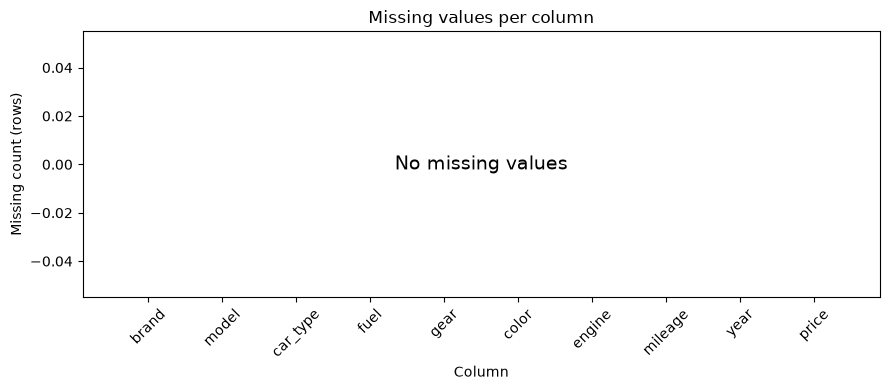

ไม่พบค่าว่าง


In [5]:
# [05] ตรวจคุณภาพ 1: ค่าว่าง
# ==================================================
# ทำอะไร: นับจำนวนและเปอร์เซ็นต์ของ "ค่าว่าง" (missing value, ช่องที่ไม่มีข้อมูล) ในทุกคอลัมน์ของ raw_df
#         แล้ววาดแท่งกราฟจำนวนค่าว่างต่อคอลัมน์
# ทำไม: ส่วนนี้ ([05]–[11]) คือการตรวจคุณภาพข้อมูลก่อนสร้างโมเดล เพราะหลัก "garbage in, garbage out"
#       คือถ้าข้อมูลเข้าไม่ดี (ว่าง ซ้ำ เป็นไปไม่ได้ กระจายแปลก) ต่อให้โมเดลดีแค่ไหน ผลลัพธ์ก็ไม่น่าเชื่อถือ
#       ค่าว่างต้องรู้ก่อนเสมอ เพราะถ้ามีอยู่ ต้องตัดสินใจว่าจะเติม ลบ หรือปล่อยไว้
#       ข้อตกลงของทั้งส่วนนี้:
#       1) ทุกเซลล์ตรวจบน raw_df ทั้งไฟล์ (ก่อนเตรียมข้อมูล) ซึ่งปลอดภัย เพราะไม่มีผลการตรวจใดถูกนำไปเลือก
#          อะไรให้โมเดลเลย (ไม่มี data leakage คือข้อมูลชุดทดสอบไม่รั่วไปมีอิทธิพลต่อการเลือกโมเดล)
#       2) ส่วนนี้ "รายงานอย่างเดียว" ไม่แก้ raw_df และไม่สร้างตัวแปรที่เซลล์อื่นต้องใช้
#          ถ้าพบปัญหา ผู้ใช้เป็นคนตัดสินใจทีหลังว่าจะทำอย่างไร ข้อมูลจึงไม่ถูกเปลี่ยนที่นี่
#          และผลของโมเดลไม่เปลี่ยน
#       3) ข้อสรุปท้ายแต่ละเซลล์ถูกคำนวณโดยโค้ด ไม่ได้พิมพ์ตายตัว
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อคอลัมน์ (10 แถว) บอกจำนวนค่าว่างและเปอร์เซ็นต์ กราฟแท่งจำนวนค่าว่างต่อคอลัมน์
#       ถ้าทุกแท่งเป็นศูนย์ บนกราฟจะมีข้อความ "No missing values" และบรรทัดสุดท้ายบอกว่าไม่พบค่าว่าง
#       ถ้ามีแท่งสูง แสดงว่าคอลัมน์นั้นมีข้อมูลหาย ควรหาสาเหตุก่อนไปต่อ
# ==================================================
print("=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===")

missing_table = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean() * 100,
})

print("ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว")
display(missing_table.style.format({
    "missing_count": "{:,.0f}",
    "missing_percent": "{:.2f}",
}))

total_missing = int(missing_table["missing_count"].sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_table.index, missing_table["missing_count"])
ax.set_title("Missing values per column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing count (rows)")
ax.tick_params(axis="x", rotation=45)
if total_missing == 0:
    ax.text(0.5, 0.5, "No missing values", transform=ax.transAxes,
            ha="center", va="center", fontsize=14)
plt.tight_layout()
plt.show()

if total_missing == 0:
    print("ไม่พบค่าว่าง")
else:
    columns_with_missing = int((missing_table["missing_count"] > 0).sum())
    print(f"พบค่าว่างรวม {total_missing:,} ค่า ใน {columns_with_missing} คอลัมน์")

=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===
ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'


,duplicate_rows,percent_of_rows
all columns,0,0.00
all except price,129,0.44
all except color,11,0.04


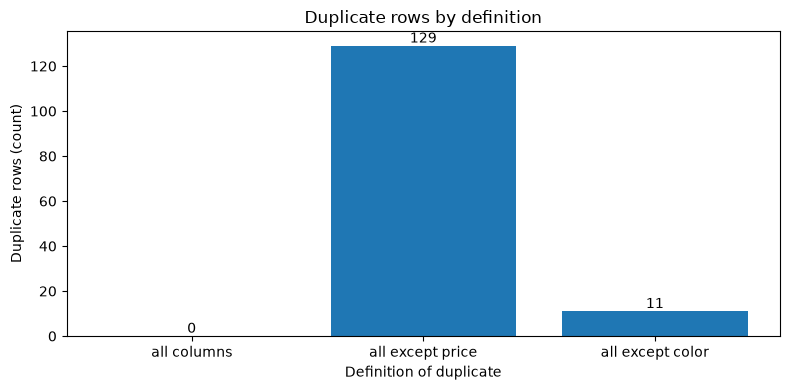

ไม่พบแถวที่ซ้ำกันทุกคอลัมน์
แถวที่ต่างกันแค่ price (ธงเตือน)   : 129 แถว
แถวที่ต่างกันแค่ color (รถคนละคัน) : 11 แถว


In [6]:
# [06] ตรวจคุณภาพ 2: แถวซ้ำ
# ==================================================
# ทำอะไร: นับแถวที่ "ซ้ำกับแถวก่อนหน้า" (ตัวสำเนาส่วนเกิน ไม่นับแถวแรกที่เจอ) ตาม 3 นิยาม
#         1) เหมือนกันทุกคอลัมน์
#         2) เหมือนกันทุกคอลัมน์ ยกเว้น price
#         3) เหมือนกันทุกคอลัมน์ ยกเว้น color
# ทำไม: กฎของโปรเจกต์นี้คือ "แถวที่ต่างกันในคอลัมน์ใดก็ตามที่ไม่ใช่ price ถือว่าเป็นรถคนละคัน"
#       ดังนั้น
#       - นิยาม 1 คือแถวซ้ำจริง ๆ (อาจเป็นข้อมูลที่ถูกบันทึกซ้ำ)
#       - นิยาม 2 คือแถวที่ทุกอย่างเหมือนกันหมดแต่ราคาต่างกัน ตามกฎอาจเป็นรถคันเดียวที่ถูกประกาศขายสองราคา
#         จึงเป็นธงเตือนคุณภาพ (quality flag) ไม่ใช่ข้อผิดพลาดที่ยืนยันแล้ว
#       - นิยาม 3 คือแถวที่ต่างกันแค่สี ตามกฎเป็นรถคนละคัน (สีต่างกัน) จึงไม่ใช่ข้อมูลซ้ำ
#         ข้อนี้เชื่อมกับหมายเหตุในเซลล์ [13] ที่อธิบายเรื่องการแบ่งข้อมูล
#       แถวซ้ำสำคัญเพราะถ้าแถวเดียวกันอยู่ทั้งชุดเทรนและชุดทดสอบ คะแนนทดสอบจะดีเกินจริง
#       เซลล์นี้รายงานอย่างเดียว ไม่ลบแถวใดเลย
# ผลที่ควรเห็น: ตารางสามแถว (นิยามละหนึ่งแถว) บอกจำนวนแถวซ้ำและเปอร์เซ็นต์ กราฟแท่งสามแท่งเขียนตัวเลขบนแท่ง
#       ตัวเลขนิยาม 2 และ 3 จะมากกว่าหรือเท่ากับนิยาม 1 เสมอ (เพราะเทียบน้อยคอลัมน์กว่า เจอซ้ำง่ายกว่า)
# ==================================================
print("=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===")

definitions = {
    "all columns": list(raw_df.columns),
    "all except price": [c for c in raw_df.columns if c != "price"],
    "all except color": [c for c in raw_df.columns if c != "color"],
}

duplicate_counts = {}
for name, columns in definitions.items():
    duplicate_counts[name] = int(raw_df.duplicated(subset=columns, keep="first").sum())

duplicate_table = pd.DataFrame({
    "duplicate_rows": pd.Series(duplicate_counts),
})
duplicate_table["percent_of_rows"] = duplicate_table["duplicate_rows"] / len(raw_df) * 100

print("ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'")
display(duplicate_table.style.format({
    "duplicate_rows": "{:,.0f}",
    "percent_of_rows": "{:.2f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(duplicate_table.index, duplicate_table["duplicate_rows"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Duplicate rows by definition")
ax.set_xlabel("Definition of duplicate")
ax.set_ylabel("Duplicate rows (count)")
plt.tight_layout()
plt.show()

if duplicate_counts["all columns"] == 0:
    print("ไม่พบแถวที่ซ้ำกันทุกคอลัมน์")
else:
    print(f"พบแถวซ้ำทุกคอลัมน์ {duplicate_counts['all columns']:,} แถว")
print(f"แถวที่ต่างกันแค่ price (ธงเตือน)   : {duplicate_counts['all except price']:,} แถว")
print(f"แถวที่ต่างกันแค่ color (รถคนละคัน) : {duplicate_counts['all except color']:,} แถว")

=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===
ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)


,rows_violating
price <= 0,0
engine <= 0,0
mileage < 0,0
year > 2026,0


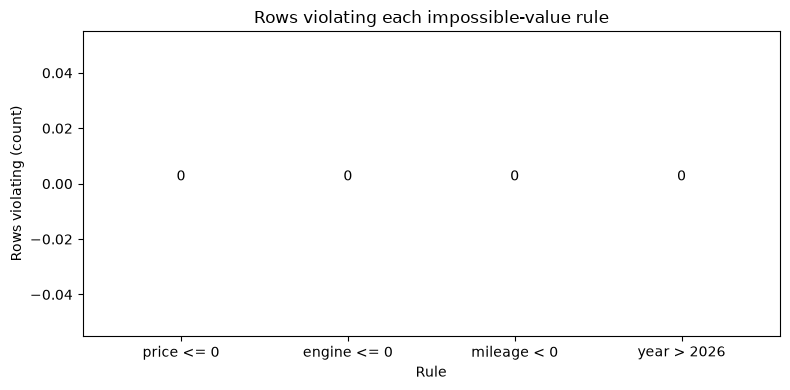

ไม่พบค่าที่เป็นไปไม่ได้


In [7]:
# [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้
# ==================================================
# ทำอะไร: นับแถวที่ฝ่าฝืนกฎ "ค่าที่เป็นไปไม่ได้ในโลกจริง" 4 ข้อ
#         1) price <= 0     ราคาขายต้องมากกว่า 0 บาท
#         2) engine <= 0    ขนาดเครื่องยนต์ (cc) ต้องมากกว่า 0
#         3) mileage < 0    เลขไมล์ติดลบไม่ได้ (ไมล์เป็น 0 ได้ เช่นรถใหม่)
#         4) year > CURRENT_YEAR   ปีของรถต้องไม่เกินปีปัจจุบัน (CURRENT_YEAR กำหนดในเซลล์ [03])
# ทำไม: ค่าที่เป็นไปไม่ได้แปลว่าข้อมูลผิดแน่นอน (เช่นกรอกผิดหรือระบบเก็บพลาด) ไม่เหมือนค่าที่แค่หายาก
#       ถ้ามีอยู่จะทำให้โมเดลเรียนรู้จากข้อมูลเท็จ ใช้เฉพาะกฎที่ตรรกะบังคับเท่านั้น
#       ไม่คิดเกณฑ์ที่ตั้งเองตามใจ เช่น "รถเก่าเกินไป" เพราะรถเก่ามากที่ราคาสูงก็มีจริง (รถคลาสสิก)
# ผลที่ควรเห็น: ตารางแต่ละกฎกับจำนวนแถวที่ฝ่าฝืน และกราฟแท่งของแต่ละกฎ
#       ถ้าทุกกฎเป็น 0 แปลว่าไม่พบค่าที่เป็นไปไม่ได้ ถ้าไม่ใช่ ควรดูแถวนั้นก่อนตัดสินใจว่าจะทำอย่างไร
#       (เซลล์นี้ไม่แก้และไม่ลบข้อมูล)
# ==================================================
print("=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===")

impossible_counts = {
    "price <= 0": int((raw_df["price"] <= 0).sum()),
    "engine <= 0": int((raw_df["engine"] <= 0).sum()),
    "mileage < 0": int((raw_df["mileage"] < 0).sum()),
    f"year > {CURRENT_YEAR}": int((raw_df["year"] > CURRENT_YEAR).sum()),
}

impossible_table = pd.DataFrame({
    "rows_violating": pd.Series(impossible_counts),
})

print("ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)")
display(impossible_table.style.format({"rows_violating": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(impossible_table.index, impossible_table["rows_violating"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Rows violating each impossible-value rule")
ax.set_xlabel("Rule")
ax.set_ylabel("Rows violating (count)")
plt.tight_layout()
plt.show()

total_impossible = sum(impossible_counts.values())
if total_impossible == 0:
    print("ไม่พบค่าที่เป็นไปไม่ได้")
else:
    print(f"พบการฝ่าฝืนกฎรวม {total_impossible:,} ครั้ง (นับซ้ำได้ถ้าแถวเดียวฝ่าฝืนหลายกฎ)")

=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===
ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3


,price,engine,mileage,year
count,"29,571","29,571","29,571","29,571"
mean,"617,473","1,912","110,627","2,018"
std,"647,018",515,"73,033",4
min,"36,000","1,000",1,"2,001"
25%,"319,000","1,500","57,500","2,016"
50%,"459,000","2,000","102,500","2,019"
75%,"699,000","2,400","155,000","2,021"
max,"13,990,000","3,000","746,754","2,026"


C:\Users\putaw\AppData\Local\Temp\ipykernel_15056\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_15056\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_15056\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_15056\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be re

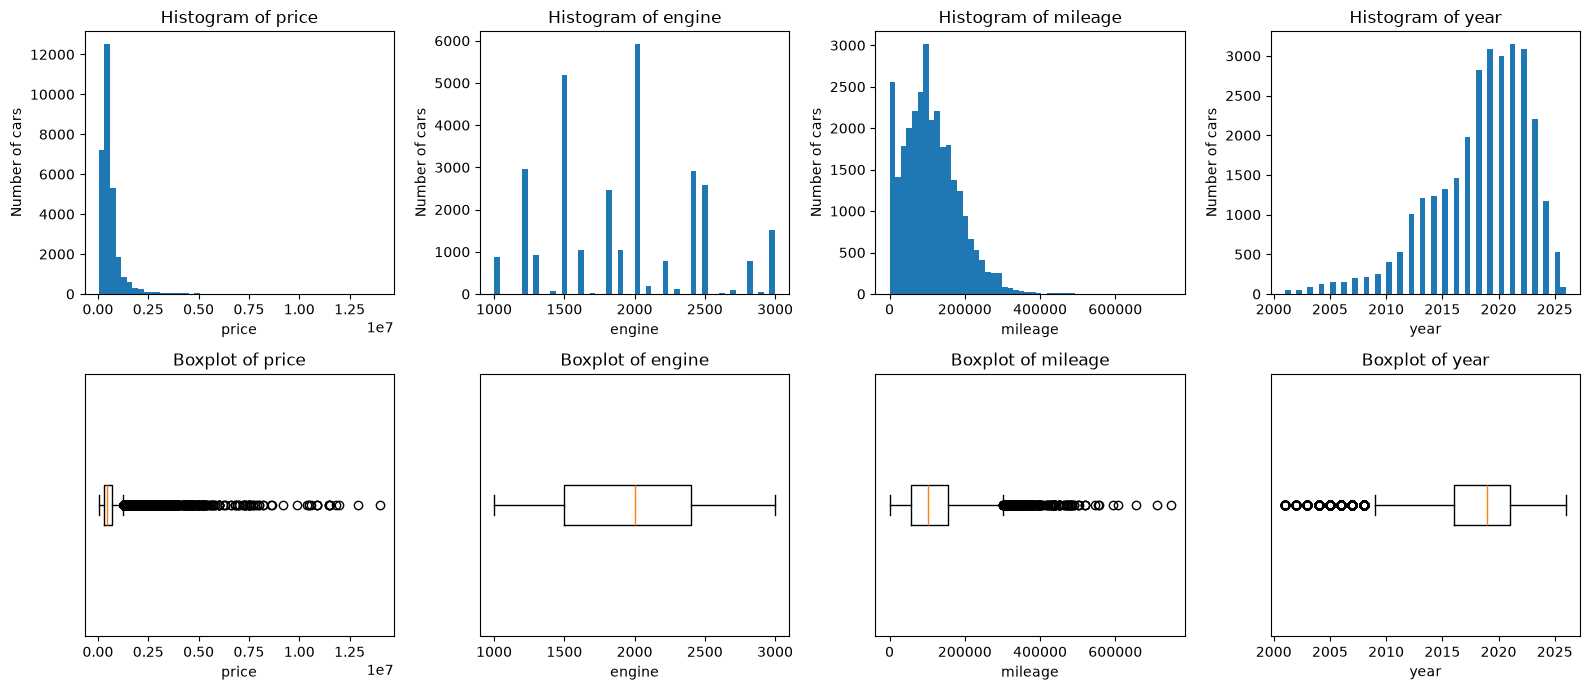

price   : ค่าความเบ้ +6.26 -> เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)
engine  : ค่าความเบ้ +0.28 -> ไม่เบ้มาก
mileage : ค่าความเบ้ +0.85 -> ไม่เบ้มาก
year    : ค่าความเบ้ -1.00 -> เบ้ซ้ายชัดเจน (หางยาวไปทางค่าต่ำ)


In [8]:
# [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข
# ==================================================
# ทำอะไร: สรุปสถิติ (describe) ของคอลัมน์ตัวเลข 4 ตัว (price, engine, mileage, year)
#         แล้ววาด histogram (แถวบน) และ boxplot (แถวล่าง) ของแต่ละตัว
# ทำไม: การดูรูปร่างการกระจายของข้อมูลช่วยให้เห็นสิ่งที่ตัวเลขสรุปไม่บอก เช่น ข้อมูลเบ้ หรือถูกตัดที่ค่าสูงสุด
# วิธีอ่านกราฟ (เป็นสิ่งที่ควรสังเกต ไม่ใช่ข้อเท็จจริงของการรันครั้งนี้):
#   - Histogram: แบ่งค่าเป็นช่วง (bins = 50 ช่วง) แท่งสูง = มีรถในช่วงราคา/ค่านั้นมาก
#   - Boxplot: กล่อง = ข้อมูลตรงกลาง 50% (จาก Q1 ถึง Q3), เส้นในกล่อง = มัธยฐาน (median คือค่ากลางเมื่อเรียงลำดับ),
#              หนวด (whiskers) = ช่วงที่ยังถือว่าปกติ, จุดนอกหนวด = ค่าที่ห่างมาก (outlier)
#   - ความเบ้ (skew): ถ้าหางยาวไปทางขวา (ส่วนใหญ่ค่าต่ำ มีบางคันแพงมาก) เรียกว่าเบ้ขวา ราคารถมักเป็นแบบนี้
#   - แท่งสูงผิดปกติที่ค่าสูงสุด: อาจหมายถึงข้อมูลถูกตัดเพดาน (capped) ตอนเก็บ เช่น ทุกคันที่แพงกว่าเพดานถูกบันทึกเป็นค่าเพดาน
# ผลที่ควรเห็น: ตารางสถิติ (จำนวน ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ต่ำสุด quartile สูงสุด) และรูป 2 แถว 4 คอลัมน์
#       ตารางไม่ได้ถูกแก้ข้อมูลใด ๆ เซลล์นี้รายงานอย่างเดียว
# ==================================================
print("=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

print("ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3")
display(raw_df[numeric_check_columns].describe().style.format("{:,.0f}"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for position, column in enumerate(numeric_check_columns):
    axes[0, position].hist(raw_df[column], bins=50)
    axes[0, position].set_title(f"Histogram of {column}")
    axes[0, position].set_xlabel(column)
    axes[0, position].set_ylabel("Number of cars")
    axes[1, position].boxplot(raw_df[column], vert=False)
    axes[1, position].set_title(f"Boxplot of {column}")
    axes[1, position].set_xlabel(column)
    axes[1, position].set_yticks([])
plt.tight_layout()
plt.show()

skewness = raw_df[numeric_check_columns].skew()
for column in numeric_check_columns:
    if skewness[column] > 1:
        shape = "เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)"
    elif skewness[column] < -1:
        shape = "เบ้ซ้ายชัดเจน (หางยาวไปทางค่าต่ำ)"
    else:
        shape = "ไม่เบ้มาก"
    print(f"{column:<8}: ค่าความเบ้ {skewness[column]:+.2f} -> {shape}")

=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===
ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว


column,q1,q3,iqr,lower_fence,upper_fence,below,above,outlier_percent,outliers
price,"319,000","699,000","380,000","-251,000","1,269,000",0,"2,222",7.51,"2,222"
engine,"1,500","2,400",900,150,"3,750",0,0,0.00,0
mileage,"57,500","155,000","97,500","-88,750","301,250",0,326,1.10,326
year,"2,016","2,021",5,"2,008","2,028","1,022",0,3.46,"1,022"


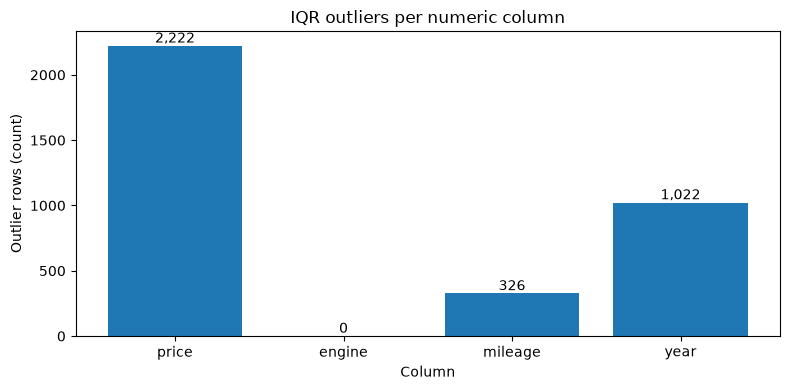

พบค่านอกรั้ว IQR รวม 3,570 ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)


In [9]:
# [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR)
# ==================================================
# ทำอะไร: หาค่าผิดปกติ (outlier คือค่าที่ห่างจากส่วนใหญ่มาก) ของคอลัมน์ตัวเลขแต่ละตัวด้วยกฎ IQR ของ Tukey
#         ขั้นตอน: หา Q1 (ค่าที่ 25% ของข้อมูลต่ำกว่า) และ Q3 (ค่าที่ 75%)
#                  IQR = Q3 - Q1 (ความกว้างของข้อมูลตรงกลาง 50%)
#                  รั้วล่าง = Q1 - 1.5 x IQR, รั้วบน = Q3 + 1.5 x IQR
#                  ค่าที่ต่ำกว่ารั้วล่างหรือสูงกว่ารั้วบนนับเป็น outlier
# ทำไม: 1.5 เป็นค่าที่ John Tukey เสนอไว้เป็นธรรมเนียมปฏิบัติ (convention) ไม่ใช่กฎธรรมชาติ
#       ต้องระวังว่า outlier ไม่ได้แปลว่าข้อมูลผิดเสมอไป รถแพงมากมีอยู่จริง จึงเป็นข้อมูลจริงที่ควรเก็บไว้
#       Random Forest คือต้นไม้ตัดสินใจ (decision tree) หลายต้นรวมกัน แต่ละต้นแบ่งข้อมูลด้วยลำดับ
#       (มากกว่า/น้อยกว่าเกณฑ์) จึงไม่สนใจว่าค่าสุดโต่งนั้นสุดโต่งแค่ไหน
#       ค่าฟีเจอร์ที่สุดโต่งจึงกระทบป่าต้นไม้น้อย (ต่างจากโมเดลเชิงเส้นที่ถูกลากง่าย)
#       เซลล์นี้ไม่ลบหรือแก้ค่าใดเลย รายงานอย่างเดียว
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (Q1, Q3, IQR, รั้วล่าง/บน, จำนวนที่ต่ำกว่า/สูงกว่า, เปอร์เซ็นต์ของแถวทั้งหมด)
#       และกราฟแท่งจำนวน outlier ต่อคอลัมน์ ถ้าแท่งสูงให้ดูว่าเป็นค่าจริงที่หายากหรือสัญญาณข้อมูลผิด
# ==================================================
print("=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

rows = []
for column in numeric_check_columns:
    q1 = raw_df[column].quantile(0.25)
    q3 = raw_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    below = int((raw_df[column] < lower_fence).sum())
    above = int((raw_df[column] > upper_fence).sum())
    rows.append({
        "column": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "below": below,
        "above": above,
        "outlier_percent": (below + above) / len(raw_df) * 100,
    })

outlier_table = pd.DataFrame(rows)
outlier_table["outliers"] = outlier_table["below"] + outlier_table["above"]

print("ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว")
display(outlier_table.style.hide(axis="index").format({
    "q1": "{:,.0f}",
    "q3": "{:,.0f}",
    "iqr": "{:,.0f}",
    "lower_fence": "{:,.0f}",
    "upper_fence": "{:,.0f}",
    "below": "{:,.0f}",
    "above": "{:,.0f}",
    "outlier_percent": "{:.2f}",
    "outliers": "{:,.0f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(outlier_table["column"], outlier_table["outliers"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("IQR outliers per numeric column")
ax.set_xlabel("Column")
ax.set_ylabel("Outlier rows (count)")
plt.tight_layout()
plt.show()

total_outliers = int(outlier_table["outliers"].sum())
if total_outliers == 0:
    print("ไม่พบค่าผิดปกติตามกฎ IQR")
else:
    print(f"พบค่านอกรั้ว IQR รวม {total_outliers:,} ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)")

=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===
ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน


column,levels,most_common,most_common_share_percent,smallest_level_rows
brand,42,TOYOTA,30.68,1
model,450,D-MAX,4.58,1
car_type,5,Sedan,33.21,"1,720"
fuel,3,Benzine,57.00,"4,237"
gear,2,Automatic,89.75,"3,032"
color,21,White,33.48,1


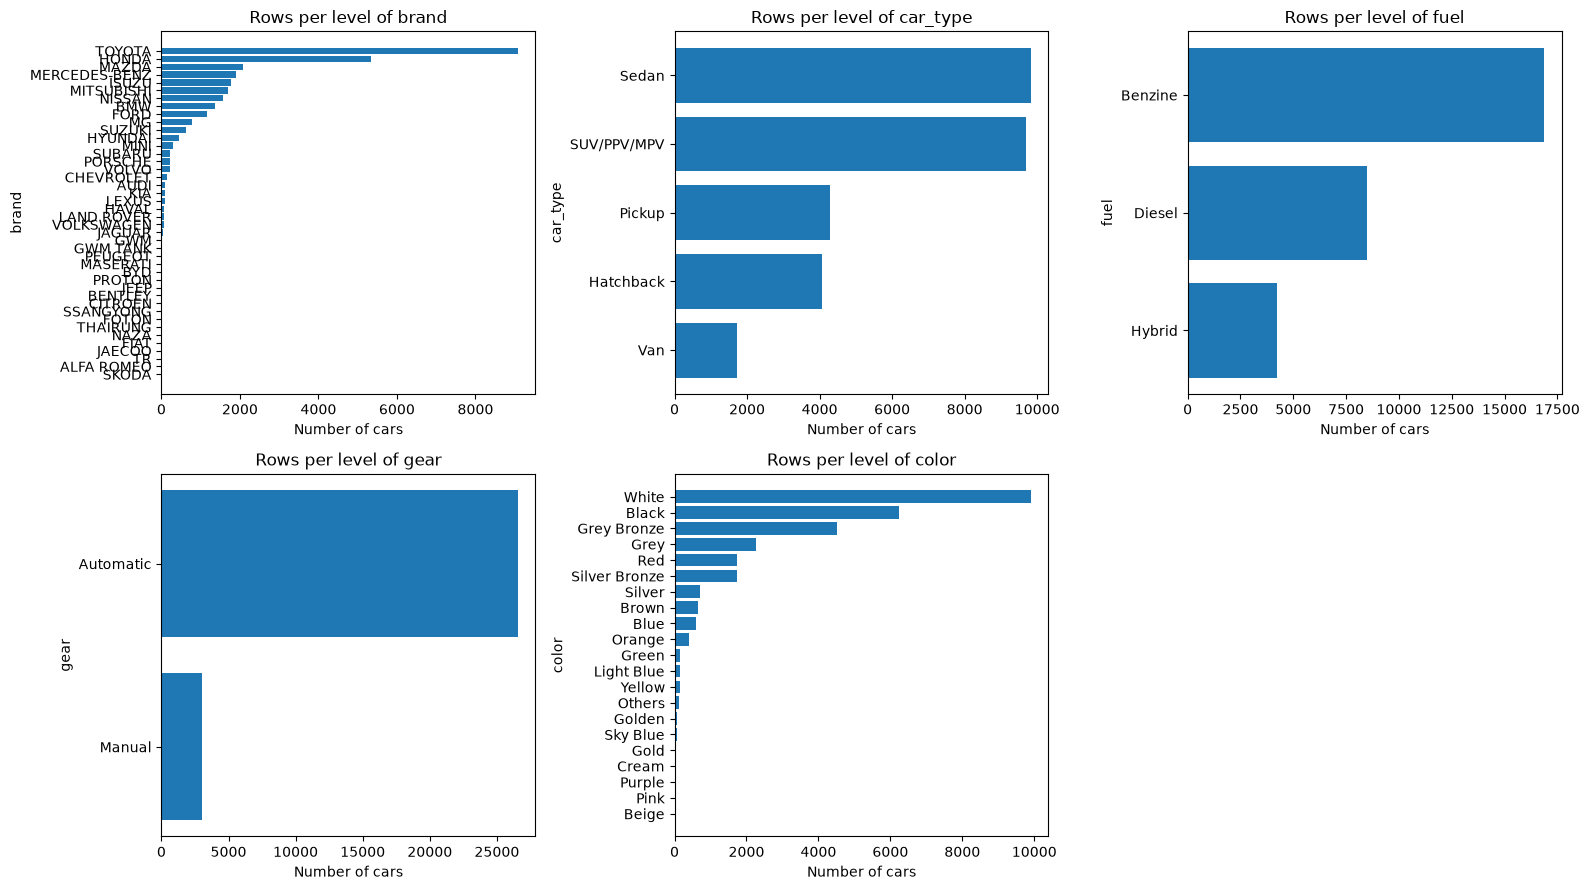

ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี 1 แถว


In [10]:
# [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม
# ==================================================
# ทำอะไร: ดูคอลัมน์ที่เป็นกลุ่ม/ประเภท (categorical) 6 ตัว: brand, model, car_type, fuel, gear, color
#         นับจำนวนระดับ (level คือค่าที่แตกต่างกัน เช่น fuel มี เบนซิน/ดีเซล/...) ระดับที่พบบ่อยที่สุดและสัดส่วนของมัน
#         แล้ววาดแท่งแนวนอนจำนวนแถวต่อระดับ ของ brand, car_type, fuel, gear, color
# ทำไม: ระดับที่หายาก (rare level คือมีแถวน้อยมาก) สร้างปัญหาสองอย่าง
#       1) One-hot encoding (แปลงแต่ละระดับเป็นคอลัมน์ 0/1) จะได้คอลัมน์ที่เกือบทั้งหมดเป็น 0 และเรียนรู้อะไรไม่ได้มาก
#       2) การแบ่งข้อมูลและการแบ่งโหนดของต้นไม้: ถ้าระดับหนึ่งมีไม่กี่แถว อาจไม่มีตัวอย่างในชุดทดสอบ หรือต้นไม้
#          แบ่งตามระดับนั้นแล้วได้ใบ (leaf) เล็กจนไม่น่าเชื่อถือ
#       คอลัมน์ model มีหลายระดับเกินกว่าจะวาดเป็นกราฟแท่ง เซลล์ [11] ดูเรื่องนี้แยกต่างหาก
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (จำนวนระดับ ระดับที่พบมากสุด สัดส่วน) และรูป 2x3 ช่อง ใช้ 5 ช่อง
#       ช่องที่หกถูกลบทิ้ง ในกราฟ แท่งสั้นมาก ๆ คือระดับหายาก
# ==================================================
print("=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===")

categorical_check_columns = ["brand", "model", "car_type", "fuel", "gear", "color"]

rows = []
for column in categorical_check_columns:
    counts = raw_df[column].value_counts()
    rows.append({
        "column": column,
        "levels": len(counts),
        "most_common": counts.index[0],
        "most_common_share_percent": counts.iloc[0] / len(raw_df) * 100,
        "smallest_level_rows": counts.min(),
    })
level_table = pd.DataFrame(rows)

print("ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน")
display(level_table.style.hide(axis="index").format({
    "levels": "{:,.0f}",
    "most_common_share_percent": "{:.2f}",
    "smallest_level_rows": "{:,.0f}",
}))

plot_columns = ["brand", "car_type", "fuel", "gear", "color"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
flat_axes = axes.flatten()
for position, column in enumerate(plot_columns):
    counts = raw_df[column].value_counts().sort_values()
    flat_axes[position].barh(counts.index.astype(str), counts.to_numpy())
    flat_axes[position].set_title(f"Rows per level of {column}")
    flat_axes[position].set_xlabel("Number of cars")
    flat_axes[position].set_ylabel(column)
fig.delaxes(flat_axes[5])
plt.tight_layout()
plt.show()

smallest_level_rows = level_table["smallest_level_rows"].min()
print(f"ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี {smallest_level_rows:,} แถว")

=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===
จำนวนรุ่น (brand|model) : 451
แถวต่อรุ่น ต่ำสุด       : 1
แถวต่อรุ่น มัธยฐาน      : 8
แถวต่อรุ่น สูงสุด       : 1,353
คู่ brand|model ที่มีแถวน้อยกว่า 10: 242
คู่ brand|model ที่มีแถวน้อยกว่า 50: 357
ชื่อ model ที่มีแถวน้อยกว่า 10: 241
ชื่อ model ที่มีแถวน้อยกว่า 50: 356


brand,model,rows
ALFA ROMEO,156,1
AUDI,A1,1
AUDI,A3,1
VOLVO,S40,1
VOLVO,C30,1
BMW,750E,1
BMW,ACTIVEHYBRID 7 L,1
MERCEDES-BENZ,V220,1
MERCEDES-BENZ,V250,1
MG,MG,1


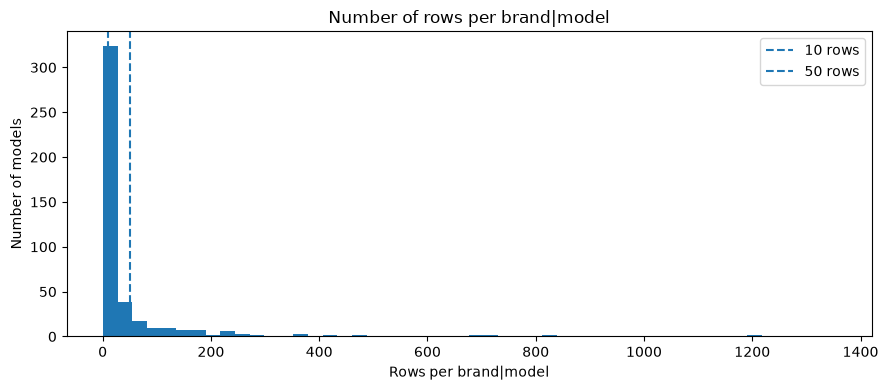

In [11]:
# [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น
# ==================================================
# ทำอะไร: รายงานจำนวนแถวต่อรุ่นและจำนวนรุ่นที่ต่ำกว่า 10 และ 50 แถว
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ข้อมูลชุดนี้ไม่มีข้อกำหนดจำนวนแถวขั้นต่ำต่อรุ่น ไม่ลบแถวในเซลล์ตรวจคุณภาพ
# ==================================================
print("=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===")

rows_per_model = raw_df.groupby(["brand", "model"]).size()
print(f"จำนวนรุ่น (brand|model) : {len(rows_per_model):,}")
print(f"แถวต่อรุ่น ต่ำสุด       : {rows_per_model.min():,.0f}")
print(f"แถวต่อรุ่น มัธยฐาน      : {rows_per_model.median():,.0f}")
print(f"แถวต่อรุ่น สูงสุด       : {rows_per_model.max():,.0f}")
print(f"คู่ brand|model ที่มีแถวน้อยกว่า 10: {(rows_per_model < 10).sum():,}")
print(f"คู่ brand|model ที่มีแถวน้อยกว่า 50: {(rows_per_model < 50).sum():,}")
model_counts_only = raw_df.groupby("model").size()
print(f"ชื่อ model ที่มีแถวน้อยกว่า 10: {(model_counts_only < 10).sum():,}")
print(f"ชื่อ model ที่มีแถวน้อยกว่า 50: {(model_counts_only < 50).sum():,}")
smallest_models = rows_per_model.sort_values().head(10).rename("rows").reset_index()
display(smallest_models.style.hide(axis="index").format({"rows": "{:,.0f}"}))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rows_per_model, bins=50)
for threshold_rows in [10, 50]:
    ax.axvline(threshold_rows, linestyle="--", label=f"{threshold_rows} rows")
ax.set(title="Number of rows per brand|model", xlabel="Rows per brand|model", ylabel="Number of models")
ax.legend()
plt.tight_layout()
plt.show()


In [12]:
# [12] เตรียมข้อมูล: car_age และตัดคอลัมน์
# ==================================================
# ทำอะไร: ทำสำเนาของ raw_df เป็น df แล้ว
#         ใช้กฎ v3 กรองอายุและรวมชื่อรุ่นก่อน โดยเลือกชื่อเดิมที่พบบ่อยที่สุดในแต่ละกลุ่ม
#         (1) สร้างคอลัมน์ car_age = CURRENT_YEAR - year (อายุรถเป็นปี)
#         (2) ตัดคอลัมน์ year และ color ทิ้ง
#         (3) ตรวจว่าคอลัมน์ที่ใช้ทั้งหมดไม่มีค่าว่าง
# ทำไม:
#   - ตัด year เพราะ car_age บอกข้อมูลเดียวกันอยู่แล้ว (ปีที่ผลิตมากขึ้น = อายุน้อยลง)
#     เก็บไว้ทั้งสองจะซ้ำซ้อน
#   - ตัด color เพราะเป็นการตัดสินใจของโปรเจกต์ที่จะไม่ใช้สีเป็น feature
#     (ผลของการตัดนี้ต่อแถวที่ค่าเหมือนกันข้ามชุด อธิบายไว้ในเซลล์ [13])
#   - สร้าง df จาก raw_df.copy() ทุกครั้ง เพื่อให้รันเซลล์นี้ซ้ำได้ ไม่แก้ raw_df
#     ถ้าแก้ df ตรงๆ รอบที่สองจะไม่มีคอลัมน์ year ให้คำนวณแล้ว
#   - ไม่เปลี่ยนชื่อคอลัมน์ engine, fuel, gear เป็น engine_capacity, fuel_type, gear_type
#     ที่ต้นฉบับทำ เพราะผู้ใช้สั่งให้ใช้ชื่อตามไฟล์ข้อมูล การเปลี่ยนชื่อไม่มีผลกับตัวเลขของโมเดล
#     (ทดสอบแล้วกับโมเดล DT ได้ R² เท่าเดิมทุกหลัก) ต่างกันแค่ชื่อที่แสดงใน features และ RESULT_JSON
#     ถ้าจะเทียบกับไฟล์โมเดล V4 เดิม (V4_*_min50.json) ต้องจับคู่ชื่อเอง
# ผลที่ควรเห็น: ขนาดตาราง df และรายชื่อคอลัมน์ (ต้องไม่มี year และ color แต่มี car_age)
# ==================================================
print("=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===")

df = raw_df.copy()

before_age = len(df)
df = df.loc[(CURRENT_YEAR - df["year"]) <= MAX_CAR_AGE].copy()
print(f"ขั้นกรองอายุ: ลบ {before_age - len(df):,} แถว เหลือ {len(df):,} แถว")
before_normalize = len(df)
original_models = df["model"].copy()
model_key_clean = df["model"].str.upper().str.replace("[^A-Z0-9]", "", regex=True).replace(MODEL_ALIASES)
best_name = df.groupby(model_key_clean)["model"].agg(lambda names: names.value_counts().index[0])
df["model"] = model_key_clean.map(best_name)
print(f"ขั้นรวมชื่อรุ่น: ลบ {before_normalize - len(df):,} แถว เปลี่ยนชื่อ {(original_models != df['model']).sum():,} แถว")
print(f"หลังรวมชื่อรุ่น: {df.groupby(['brand', 'model']).ngroups:,} คู่ brand|model")
df["car_age"] = CURRENT_YEAR - df["year"]
df = df.drop(columns=["year", "color"])
assert df[NUM_COLS + CAT_COLS + ["price"]].notna().all().all()

print(f"ขนาดตาราง df : {df.shape[0]:,} แถว x {df.shape[1]:,} คอลัมน์")
print(f"คอลัมน์      : {list(df.columns)}")

=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===
ขั้นกรองอายุ: ลบ 0 แถว เหลือ 29,571 แถว


ขั้นรวมชื่อรุ่น: ลบ 0 แถว เปลี่ยนชื่อ 287 แถว
หลังรวมชื่อรุ่น: 445 คู่ brand|model
ขนาดตาราง df : 29,571 แถว x 9 คอลัมน์
คอลัมน์      : ['brand', 'model', 'car_type', 'fuel', 'gear', 'engine', 'mileage', 'price', 'car_age']


In [13]:
# [13] แบ่ง train / validation / test
# ==================================================
# ทำอะไร: บังคับหนึ่งแถวต่อ brand|model เข้า train แล้วสุ่มเติมโควตา train และแบ่ง val/test ครึ่งต่อครึ่ง
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: มี 242 ชื่อรุ่นที่มีน้อยกว่า 10 แถว จึงแบ่งแบบ stratified ไม่ได้; ใช้กฎ v3 ด้วย SEED เดิม
# ==================================================
print("=== [13] แบ่ง train / validation / test ===")

model_key = df["brand"] + "|" + df["model"]
forced = df.groupby(["brand", "model"]).sample(n=1, random_state=SEED)
rest = df.drop(forced.index)
n_train_left = round(TRAIN_SIZE * len(df)) - len(forced)
train_rest, temp = train_test_split(rest, train_size=n_train_left, random_state=SEED)
train = pd.concat([forced, train_rest])
val, test = train_test_split(temp, test_size=0.5, random_state=SEED)

split_table = pd.DataFrame({
    "ชุด": ["train", "validation", "test"],
    "แถว": [len(train), len(val), len(test)],
    "สัดส่วน (%)": [100 * len(part) / len(df) for part in (train, val, test)],
    "จำนวนรุ่น": [model_key.loc[part.index].nunique() for part in (train, val, test)],
})
print("อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ")
display(
    split_table.style
    .format({"แถว": "{:,.0f}", "สัดส่วน (%)": "{:.2f}", "จำนวนรุ่น": "{:,.0f}"})
    .hide(axis="index")
)


=== [13] แบ่ง train / validation / test ===
อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ


ชุด,แถว,สัดส่วน (%),จำนวนรุ่น
train,"23,657",80.00,445
validation,"2,957",10.00,232
test,"2,957",10.00,246


In [14]:
# [14] สร้าง 5 fold
# ==================================================
# ทำอะไร: แบ่งชุด train เป็น N_FOLDS ส่วน (fold) ด้วย KFold เก็บเป็นรายการ folds
#         แต่ละสมาชิกคือคู่ (แถวที่ใช้สอน, แถวที่ใช้ตรวจ)
# ทำไม:
#   - K-fold cross-validation: แบ่ง train เป็น K ส่วนเท่าๆ กัน แล้วผลัดกันเอา 1 ส่วนเป็นชุดตรวจ
#     อีก K-1 ส่วนเป็นชุดสอน ทำ K รอบ แล้วเฉลี่ยคะแนน ได้ค่าที่เชื่อถือกว่าการตรวจรอบเดียว
#     และไม่ต้องแตะ validation / test
#   - สร้าง folds ครั้งเดียวแล้วให้ทุกขั้นตอนถัดไปใช้ร่วมกัน ทุกการเปรียบเทียบจึงใช้แถวชุดเดียวกัน
#     ผลต่างที่เห็นมาจากตัวเลือกที่เทียบจริง ไม่ใช่จากการแบ่ง fold ที่ต่างกัน
#   - shuffle=True สลับลำดับแถวก่อนแบ่ง เพราะข้อมูลอาจเรียงตามยี่ห้อหรือราคา
#     การแบ่งตามลำดับจะทำให้ fold ไม่เป็นตัวแทนของทั้งชุด
#     และใช้ random_state=SEED ให้สลับแล้วได้ผลเดิมทุกครั้ง
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold บอกจำนวนแถวที่ใช้สอนและแถวที่ใช้ตรวจ
#       ผลรวมสองคอลัมน์ในแต่ละแถวเท่ากับจำนวนแถวของ train
# ข้อควรระวัง: validation และ test ไม่ถูกใช้จนถึงขั้นวัดผลสุดท้าย
# ==================================================
print("=== [14] สร้าง 5 fold ===")

folds = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train))

fold_rows = []
for fold_number, (train_index, valid_index) in enumerate(folds, start=1):
    fold_rows.append({
        "fold": fold_number,
        "แถวสำหรับสอน": len(train_index),
        "แถวสำหรับตรวจ": len(valid_index),
    })
fold_table = pd.DataFrame(fold_rows)
print("อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)")
display(
    fold_table.style
    .format({"fold": "{:.0f}", "แถวสำหรับสอน": "{:,.0f}", "แถวสำหรับตรวจ": "{:,.0f}"})
    .hide(axis="index")
)

=== [14] สร้าง 5 fold ===
อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)


fold,แถวสำหรับสอน,แถวสำหรับตรวจ
1,"18,925","4,732"
2,"18,925","4,732"
3,"18,926","4,731"
4,"18,926","4,731"
5,"18,926","4,731"


In [15]:
# [15] ฟังก์ชันวัดความสัมพันธ์
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน 2 ตัวไว้วัดว่าตัวแปร 2 ตัว "สัมพันธ์กัน" มากแค่ไหน
#   - cramers_v(x, y)              : ใช้กับตัวแปรหมวดหมู่ 2 ตัว (เช่น brand กับ model)
#   - correlation_ratio(cats, vals): ใช้กับตัวแปรหมวดหมู่ 1 ตัว กับตัวเลข 1 ตัว (เช่น brand กับ price)
#   ส่วนตัวเลขกับตัวเลขใช้ Spearman ของ pandas ได้เลย ไม่ต้องสร้างฟังก์ชันเอง
# ทำไม: ข้อมูลรถมีทั้งตัวเลข (engine, mileage, car_age, price) และหมวดหมู่ (brand, model,
#   car_type, fuel, gear) การวัดแบบเดียวไม่เหมาะกับทุกคู่
#   เช่น ค่าสหสัมพันธ์ปกติ (Pearson) ใช้กับ "brand" ไม่ได้เพราะ brand ไม่ใช่ตัวเลข
#   จึงต้องเลือกตัววัดให้ตรงกับชนิดของตัวแปรแต่ละคู่:
#     1) ตัวเลข-ตัวเลข   : Spearman  = สหสัมพันธ์แบบเรียงอันดับ (rank) ค่าจริง -1..1
#                          เซลล์ [16] ใช้ค่าสัมบูรณ์ เพื่อให้อยู่สเกล 0..1 เหมือนตัววัดอื่น
#     2) หมวดหมู่-หมวดหมู่ : Cramér's V = ปรับจากค่าไคสแควร์ (chi-square) ของตารางไขว้
#                          ให้อยู่ในช่วง 0..1
#     3) หมวดหมู่-ตัวเลข  : η (อีตา, correlation ratio)
#                          = รากของ (ความแปรปรวนระหว่างกลุ่ม / ความแปรปรวนรวม)
#                          บอกว่าค่าเฉลี่ยของแต่ละหมวด อธิบายความผันผวนของตัวเลขได้กี่ส่วน
#   ทั้งสามตัววัดตีความเหมือนกัน: 0 = ไม่สัมพันธ์กันเลย, 1 = สัมพันธ์กันสมบูรณ์
#   (รู้ค่าของตัวหนึ่งก็บอกอีกตัวได้แน่นอน)
# ผลที่ควรเห็น: พิมพ์ข้อความว่าสร้างฟังก์ชันแล้ว และผ่านการเช็กตัวเอง (assert) 2 ข้อ
# ข้อควรระวัง: สามตัววัดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ
#   เซลล์นี้ใช้ train เท่านั้น (เช็กตัวเองกับ train) ไม่แตะ val และ test
# ==================================================
print("=== [15] ฟังก์ชันวัดความสัมพันธ์ ===")


def cramers_v(x, y):
    """Cramér's V ของตัวแปรหมวดหมู่ 2 ตัว (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    smaller_side = min(table.shape[0], table.shape[1])
    return np.sqrt(chi2 / (n * (smaller_side - 1)))


def correlation_ratio(categories, values):
    """η ของตัวแปรหมวดหมู่ (Series) กับตัวเลข (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    group_means = values.groupby(categories).transform("mean")
    overall_mean = values.mean()
    between_group = ((group_means - overall_mean) ** 2).sum()
    total = ((values - overall_mean) ** 2).sum()
    return np.sqrt(between_group / total)


# เช็กตัวเอง: ตัวแปรเทียบกับตัวมันเอง ต้องได้ 1
assert abs(cramers_v(train["brand"], train["brand"]) - 1) < 1e-9

# ค่าที่ขึ้นกับ fuel อย่างเดียว (เลขรหัสของแต่ละชนิดเชื้อเพลิง) ต้องได้ η = 1
fuel_codes = {level: code for code, level in enumerate(train["fuel"].unique())}
values_from_fuel = train["fuel"].map(fuel_codes)
assert abs(correlation_ratio(train["fuel"], values_from_fuel) - 1) < 1e-9

print("สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว")
print("เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1")

=== [15] ฟังก์ชันวัดความสัมพันธ์ ===
สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว
เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1


=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===


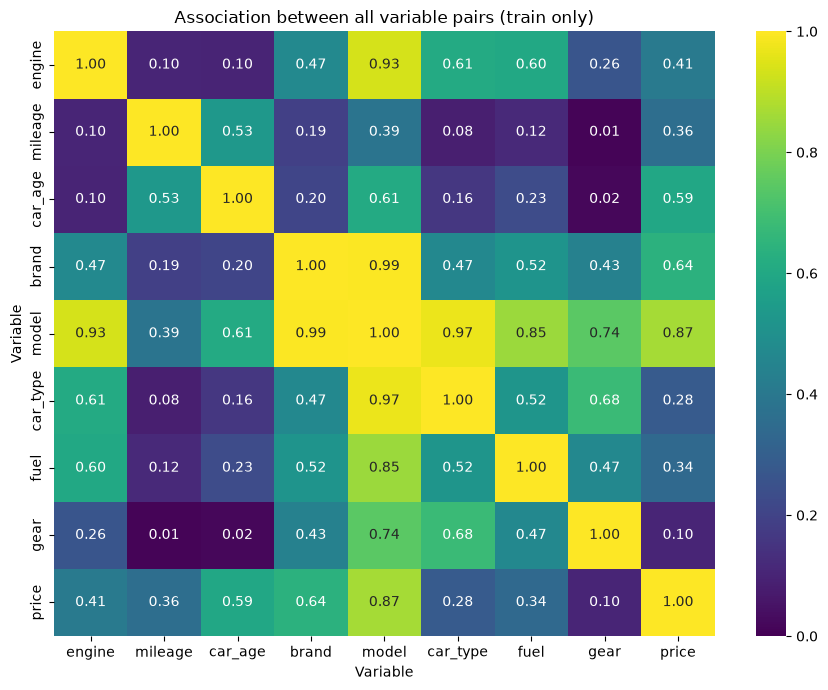

ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)


variable 1,variable 2,method,value
brand,model,Cramér's V,0.9932
model,car_type,Cramér's V,0.9711
engine,model,η,0.9343
model,price,η,0.8656
model,fuel,Cramér's V,0.8505
model,gear,Cramér's V,0.7437
car_type,gear,Cramér's V,0.6783
brand,price,η,0.6399
car_age,model,η,0.6086
engine,car_type,η,0.6072


In [16]:
# [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9)
# ==================================================
# ทำอะไร: วัดความสัมพันธ์ของตัวแปรทุกคู่ใน train (9 ตัว = 8 ฟีเจอร์ที่โมเดลใช้ + price
#   ซึ่งเป็นค่าที่จะทำนาย ได้ 36 คู่) แล้วสรุปเป็นตาราง 9x9 (association_matrix)
#   วาดเป็น heatmap (แผนที่สี) และพิมพ์ตาราง 36 คู่เรียงจากสัมพันธ์มากไปน้อย
#   วิธีวัดเลือกตามชนิดของคู่ (อธิบายไว้ที่เซลล์ [15]):
#     ตัวเลข-ตัวเลข   -> |Spearman| (ค่าสัมบูรณ์ ตัดเครื่องหมายทิ้งให้อยู่ช่วง 0..1)
#     หมวดหมู่-หมวดหมู่ -> Cramér's V
#     หมวดหมู่-ตัวเลข  -> η (correlation ratio)
#   เส้นทแยงมุมเป็น 1 เสมอ (ตัวแปรเทียบกับตัวเอง) แต่ละคู่คำนวณครั้งเดียวแล้วเติมทั้ง 2 ฝั่ง
# ทำไม: ก่อนสร้างโมเดล ควรรู้ว่าฟีเจอร์ไหนเกี่ยวข้องกับ price มาก และฟีเจอร์ไหนซ้ำซ้อนกันเอง
#   ใช้ train เท่านั้น เพราะ val และ test ต้องเป็นข้อมูลที่ไม่เคยเห็น
#   ถ้าเอาไปคำนวณด้วย จะเท่ากับแอบดูคำตอบก่อนวัดผล (data leakage)
# ผลที่ควรเห็น: heatmap 9x9 ยิ่งสีสว่าง (ใกล้ 1) ยิ่งสัมพันธ์กันมาก แล้วตาราง 36 คู่
#   วิธีอ่าน:
#     - แถวหรือคอลัมน์ของ price บอกว่าฟีเจอร์ไหนสัมพันธ์กับราคามากที่สุด
#     - คู่ model กับ brand จะใกล้ 1 เป็นเรื่องปกติ เพราะรุ่นหนึ่งสังกัดยี่ห้อเดียว
#       ไม่ใช่ข้อมูลผิดพลาด
#     - ฟีเจอร์สองตัวสัมพันธ์กันสูง ไม่ได้ทำให้ Random Forest ทำนายแย่ลง
#       แต่ทำให้บอกยากว่าฟีเจอร์ไหน "สำคัญ" จริง เพราะทั้งคู่ให้ข้อมูลซ้ำกัน
#     - ความสัมพันธ์ไม่ใช่เหตุและผล (association is not causation)
#       เช่น รถอายุมากราคาต่ำ ไม่ได้แปลว่าอายุเป็นตัวกำหนดราคาเพียงอย่างเดียว
# ข้อควรระวัง: ตัววัด 3 ชนิดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ
#   จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ เทียบในชนิดเดียวกันแม่นกว่า
# ==================================================
print("=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===")

variables = NUM_COLS + CAT_COLS + ["price"]
numeric_variables = NUM_COLS + ["price"]

association_matrix = pd.DataFrame(np.eye(len(variables)), index=variables, columns=variables)
pair_rows = []
for i in range(len(variables)):
    for j in range(i + 1, len(variables)):
        first = variables[i]
        second = variables[j]
        first_is_numeric = first in numeric_variables
        second_is_numeric = second in numeric_variables
        if first_is_numeric and second_is_numeric:
            method = "Spearman"
            value = abs(train[first].corr(train[second], method="spearman"))
        elif not first_is_numeric and not second_is_numeric:
            method = "Cramér's V"
            value = cramers_v(train[first], train[second])
        elif first_is_numeric:
            method = "η"
            value = correlation_ratio(train[second], train[first])
        else:
            method = "η"
            value = correlation_ratio(train[first], train[second])
        association_matrix.loc[first, second] = value
        association_matrix.loc[second, first] = value
        pair_rows.append(
            {"variable 1": first, "variable 2": second, "method": method, "value": value}
        )

plt.figure(figsize=(9, 7))
sns.heatmap(association_matrix, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="viridis")
plt.title("Association between all variable pairs (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

pair_table = pd.DataFrame(pair_rows).sort_values("value", ascending=False)
print("ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)")
display(pair_table.style.format({"value": "{:.4f}"}).hide(axis="index"))

=== [17] Spearman ของตัวแปรตัวเลข ===


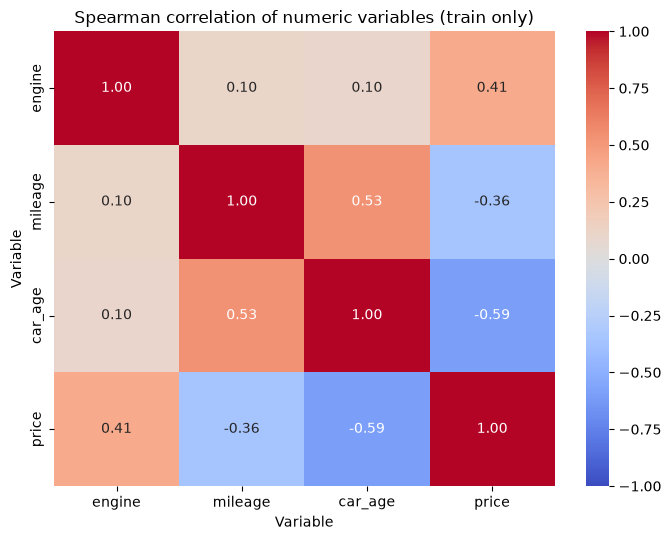

ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)


,engine,mileage,car_age,price
engine,1.0000,0.1025,0.1006,0.4066
mileage,0.1025,1.0000,0.5345,-0.3560
car_age,0.1006,0.5345,1.0000,-0.5948
price,0.4066,-0.3560,-0.5948,1.0000


In [17]:
# [17] Spearman ของตัวแปรตัวเลข
# ==================================================
# ทำอะไร: คำนวณ Spearman ของตัวแปรตัวเลข 4 ตัว (engine, mileage, car_age, price) ใน train
#   แล้ววาด heatmap และแสดงตาราง ต่างจากเซลล์ [16] ตรงที่เก็บเครื่องหมายบวก/ลบไว้ (ช่วง -1..1)
# ทำไม: เครื่องหมายบอกทิศทางที่เซลล์ [16] (ใช้ค่าสัมบูรณ์) มองไม่เห็น
#   Spearman คือสหสัมพันธ์ของ "อันดับ" (rank) ของข้อมูล ไม่ใช่ค่าจริง จึงเลือกใช้แทน Pearson เพราะ
#     - ทนต่อค่าผิดปกติ (outlier) เช่น รถราคาสูงมากไม่กี่คัน Pearson จะถูกดึงไปมาก
#     - จับความสัมพันธ์ที่ไม่เป็นเส้นตรงแต่ไปทางเดียวกันได้ (monotonic)
#       เช่น ราคาลดลงเรื่อย ๆ เมื่อเลขไมล์เพิ่ม แม้ไม่ลดเป็นเส้นตรง
# ผลที่ควรเห็น: heatmap สีแดง-น้ำเงิน (coolwarm) พร้อมตัวเลขในช่อง แล้วตารางตัวเลขชุดเดียวกัน
#   วิธีอ่านเครื่องหมาย:
#     - บวก (สีแดง) = สองตัวนี้เพิ่มไปด้วยกัน
#     - ลบ (สีน้ำเงิน) = ตัวหนึ่งเพิ่มขณะที่อีกตัวลด
#     - ใกล้ 0 (สีขาว) = ไม่มีแนวโน้มทางเดียวกันชัดเจน
#   สิ่งที่ควรดู: (1) แถว price ว่าตัวไหนสัมพันธ์กับราคามากและทิศทางใด
#   (2) ฟีเจอร์ตัวเลขสองตัวที่สัมพันธ์กันเองสูง (เช่น car_age กับ mileage มักไปด้วยกัน)
#   ซึ่งหมายความว่าให้ข้อมูลซ้ำกันบางส่วน ควรเทียบกับผลในเซลล์ [16]
# ข้อควรระวัง: สัมพันธ์ไม่ใช่เหตุและผล และใช้ train เท่านั้นเหมือนเซลล์ [16]
# ==================================================
print("=== [17] Spearman ของตัวแปรตัวเลข ===")

spearman_table = train[NUM_COLS + ["price"]].corr(method="spearman")

plt.figure(figsize=(7, 5.5))
sns.heatmap(spearman_table, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Spearman correlation of numeric variables (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

print("ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)")
display(spearman_table.style.format("{:.4f}"))

In [18]:
# [18] รายชื่อฟีเจอร์
# ==================================================
# ทำอะไร: ประกาศตัวแปร features = รายชื่อคอลัมน์ทั้งหมดที่จะป้อนให้โมเดลใช้ทายราคา
#         "ฟีเจอร์ (feature)" คือคอลัมน์ข้อมูลที่โมเดลใช้เป็นเบาะแสในการทาย
#         เช่น ปีรถ เลขไมล์ ยี่ห้อ ส่วน "ราคา" คือคำตอบที่โมเดลต้องทาย จึงไม่นับเป็นฟีเจอร์
#         ในที่นี้ใช้ NUM_COLS (ตัวเลข: engine, mileage, car_age) รวมกับ CAT_COLS
#         (หมวดหมู่: brand, model, car_type, fuel, gear) จากเซลล์ [03] รวม 8 ตัว
# ทำไม: เวอร์ชันนี้ตัดขั้น "คัดเลือกฟีเจอร์" ออกแล้ว ใช้ทุกตัวเลย เหตุผลคือ
#         1) ขั้นคัดเลือกเดิม (วัด CV MAE กับ permutation importance, backward elimination
#            และตรวจคอลัมน์ตัวเลขซ้ำ) ในโน้ตบุ๊ค DT เก็บฟีเจอร์ไว้ครบ 8 ตัวอยู่แล้ว
#            และไม่พบคู่คอลัมน์ซ้ำ โน้ตบุ๊ค RF ต้นฉบับใช้ขั้นตอนแบบเดียวกัน แต่ไฟล์ไม่ได้เก็บผลลัพธ์ไว้
#            จึงยืนยันไม่ได้ว่าฝั่ง RF เก็บครบ 8 ตัวเหมือนกันหรือไม่ การตัดขั้นนี้ทำให้ทุกโมเดล
#            ใช้ฟีเจอร์ชุดเดียวกัน และไม่ต้องฝึกโมเดลซ้ำหลายรอบ ประหยัดเวลารัน
#         2) การไม่คัดเลือก ไม่ได้พิสูจน์ว่าทุกฟีเจอร์ช่วยเสมอ ต้นไม้ใน Random Forest อาจเลือกใช้
#            ฟีเจอร์ที่ไม่มีประโยชน์เพราะความบังเอิญในข้อมูล ทำให้ทายข้อมูลใหม่แย่ลงได้
#            (เรียกว่า generalisation แย่ลง) แม้เราจะคุมขนาดใบด้วย min_samples_leaf
#            และเฉลี่ยผลจากต้นไม้หลายต้นอยู่แล้วก็ตาม
# ผลที่ควรเห็น: บรรทัดบอกจำนวนฟีเจอร์ และรายชื่อฟีเจอร์ทั้งหมด
#               คอลัมน์ตัวเลขมาก่อน แล้วตามด้วยหมวดหมู่
# ข้อควรระวัง: โน้ตบุ๊ค RF ต้นฉบับ (clean_v3_v4/v4_RF.ipynb) ยังมีขั้นคัดเลือกฟีเจอร์อยู่
#              ต้องคำนึงถึงความต่างนี้ตอนเปรียบเทียบผลกับต้นฉบับ
# ==================================================
print("=== [18] รายชื่อฟีเจอร์ ===")

features = NUM_COLS + CAT_COLS

print(f"จำนวนฟีเจอร์ : {len(features)}")
print(f"รายชื่อ      : {features}")

=== [18] รายชื่อฟีเจอร์ ===
จำนวนฟีเจอร์ : 8
รายชื่อ      : ['engine', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel', 'gear']


In [19]:
# [19] คลาส FoldOneHot
# ==================================================
# ทำอะไร: สร้างตัวแปลงข้อมูล (คลาส FoldOneHot) ที่เปลี่ยนคอลัมน์หมวดหมู่ให้เป็นตัวเลข 0/1
#         ด้วยวิธี one-hot encoding แล้วต่อกับคอลัมน์ตัวเลขเดิม
#
#         one-hot คืออะไร: โมเดลต้นไม้ในที่นี้อ่านได้แต่ตัวเลข แต่ fuel เป็นข้อความ
#         เราจึงแตกเป็นคอลัมน์ใหม่ที่ตอบแค่ "ใช่ (1) หรือ ไม่ใช่ (0)" ต่อหนึ่งค่า
#         ตัวอย่าง fuel มี 3 ค่า Benzine / Diesel / Hybrid จะได้ 2 คอลัมน์:
#                          fuel=Diesel   fuel=Hybrid
#             รถดีเซล:          1             0
#             รถไฮบริด:        0             1
#             รถเบนซิน:        0             0      <- ศูนย์ทั้งคู่ = ค่าอ้างอิง
#
# ทำไม:
#   - ทิ้ง 1 ค่า (ระดับอ้างอิง หรือ reference level): ค่าที่เจอบ่อยที่สุดในข้อมูลฝึกจะไม่มีคอลัมน์
#     ของตัวเอง เพราะรู้ได้จากการที่คอลัมน์อื่นเป็น 0 หมด ถ้าเก็บครบทุกค่า คอลัมน์จะซ้ำซ้อนกัน
#     ถ้าความถี่เท่ากัน จะเรียงตามชื่อระดับจากน้อยไปมาก เพื่อให้ผลเหมือนเดิมทุกครั้ง
#   - เรียนรู้ (fit) ใน "แต่ละ fold": fold คือการแบ่งข้อมูลฝึกเป็นส่วนย่อย ๆ เพื่อสลับกันเป็น
#     ชุดฝึกและชุดตรวจ (cross-validation) รายชื่อระดับของแต่ละ fold จึงมาจากแถวฝึกของ fold นั้นเท่านั้น
#     ไม่แอบดูแถวที่ใช้ตรวจ ข้อมูลจึงไม่รั่ว (information leak) ผล CV จึงเชื่อถือได้
#   - ระดับที่ไม่เคยเจอตอนฝึก (unseen level) จะได้ศูนย์ทุกคอลัมน์ ไม่ทำให้โปรแกรมพัง
#   - __init__ ต้องเก็บ argument ทั้งสองตัวไว้ตามเดิมโดยไม่แก้ เพราะ sklearn ต้องสร้างสำเนาของ
#     ตัวแปลง (clone) ในทุก fold โดยอ่านค่าเหล่านี้กลับไป
#   - ในเมธอด transform ใช้การเทียบแบบ broadcasting: ดึงค่าของคอลัมน์ออกมาเป็นแนวตั้ง
#     (values[:, None]) แล้วเทียบ "ทุกแถวกับทุกระดับพร้อมกัน" ในคำสั่งเดียว
#     ได้ตารางจริง/เท็จขนาด (จำนวนแถว x จำนวนระดับ) แล้วแปลงเป็น 1/0
#     วิธีนี้เร็วกว่าวนทีละระดับมาก ซึ่งสำคัญเพราะ grid search และ learning curve เรียกใช้หลายร้อยครั้ง
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างคลาสแล้ว ยังไม่มีการแปลงข้อมูลในเซลล์นี้
#               เซลล์ที่เรียกใช้จริงคือ pipeline ในเซลล์ [22] และกราฟ OOB ในเซลล์ [38]
# ข้อควรระวัง: ผู้เรียกใช้เขียน FoldOneHot(NUM_COLS, CAT_COLS)
# ==================================================
print("=== [19] คลาส FoldOneHot ===")


class FoldOneHot(TransformerMixin, BaseEstimator):
    """one-hot ที่เรียนรู้ระดับจากแถวที่ fit เท่านั้น (ไม่แอบดูแถวตรวจ)"""

    def __init__(self, numeric_columns, categorical_columns):
        # เก็บไว้ตามเดิมโดยไม่แก้ เพื่อให้ sklearn clone ได้
        self.numeric_columns = numeric_columns
        self.categorical_columns = categorical_columns

    def fit(self, X, y=None):
        """จำรายชื่อคอลัมน์ และระดับ (ไม่รวมระดับอ้างอิง) ของแต่ละคอลัมน์หมวดหมู่"""
        self.numeric_ = [c for c in X.columns if c in self.numeric_columns]
        self.categorical_ = [c for c in X.columns if c in self.categorical_columns]
        self.levels_ = {}
        for col in self.categorical_:
            counts = X[col].value_counts()
            # เรียงชื่อก่อน แล้วเรียงตามความถี่แบบ stable ชื่อจึงตัดสินเมื่อความถี่เท่ากัน
            ordered = counts.sort_index().sort_values(ascending=False, kind="stable")
            self.levels_[col] = list(ordered.index[1:])  # ตัดระดับที่พบบ่อยที่สุด = ระดับอ้างอิง
        return self

    def transform(self, X):
        """แปลงด้วยระดับที่จำไว้ตอน fit (ไม่เรียนรู้เพิ่ม)"""
        parts = [X[self.numeric_].astype(float)]
        for col in self.categorical_:
            levels = self.levels_[col]
            values = X[col].to_numpy(dtype=object)
            # เทียบทุกแถวกับทุกระดับพร้อมกัน ได้ตาราง True/False ระดับที่ไม่เคยเจอจะเป็น False หมด
            matches = values[:, None] == np.asarray(levels, dtype=object)
            dummies = pd.DataFrame(
                matches.astype(float),
                index=X.index,
                columns=[f"{col}={level}" for level in levels],
            )
            parts.append(dummies)
        return pd.concat(parts, axis=1)

    def get_feature_names_out(self, input_features=None):
        """รายชื่อคอลัมน์ผลลัพธ์ตามลำดับเดียวกับ transform"""
        names = list(self.numeric_)
        for col in self.categorical_:
            names += [f"{col}={level}" for level in self.levels_[col]]
        return np.asarray(names, dtype=object)


print("สร้างคลาส FoldOneHot แล้ว")

=== [19] คลาส FoldOneHot ===
สร้างคลาส FoldOneHot แล้ว


In [20]:
# [20] ฟังก์ชัน make_model
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน make_model() ที่คืนป่าสุ่ม (RandomForestRegressor) ตัวใหม่
#         พร้อมค่า hyperparameter ครบทั้ง 18 ตัว
#         hyperparameter = ค่าที่เราต้องตั้งเองก่อนให้โมเดลเรียน (โมเดลไม่ได้เรียนรู้ค่าพวกนี้จากข้อมูล)
#         เช่น จำนวนต้นไม้ ส่วนสิ่งที่โมเดลเรียนเองจากข้อมูลคือเงื่อนไขแตกกิ่งในต้นไม้แต่ละต้น
# ทำไม:
#   - เขียนครบทั้ง 18 ตัว พร้อมคอมเมนต์ทุกตัว ไม่ว่าจะปรับใน grid หรือไม่ เพราะผู้ใช้ต้องการ
#     เห็นทุกค่าที่โมเดลใช้จริง ไม่ต้องไปเปิดเอกสารดูค่าเริ่มต้นเอง
#   - ตัวที่มีป้าย [grid] (max_features, min_samples_leaf) จะถูก GridSearchCV เขียนทับด้วยค่าใน
#     PARAM_GRID (เซลล์ [21]) ตัวอื่นใช้ค่าตามที่เขียนในฟังก์ชัน
#   - ปรับแค่ 2 ตัว เพราะเป็นปุ่มที่คุมว่าป่า "ฟิตข้อมูลแค่ไหน" โดยตรง:
#       max_features คุมว่าต้นไม้แต่ละต้นต่างกันแค่ไหน, min_samples_leaf คุมขนาดใบและขนาดต้นไม้
#     n_estimators ไม่ปรับ (เหตุผลอยู่ในเซลล์ [03]) ส่วนตัวอื่นตั้งตามเหตุผลในคอมเมนต์ท้ายบรรทัด
#   - ไม่เพิ่ม max_depth และ max_samples เข้า grid เพราะ pilot เมื่อ 2026-10-23 (2 fold, 100 ต้น,
#     max_features=0.3, min_samples_leaf=3) แสดงว่าไม่ช่วย:
#       max_depth 15 / 20 / 30 ได้ CV MAE แย่กว่าหรือพอๆ กับ None (ไม่จำกัด)
#       max_samples 0.5 / 0.7 / 0.85 (bootstrap เล็กลง) ได้ CV MAE แย่กว่า None ทุกค่า
#     และเวลากับหน่วยความจำก็ไม่ได้บังคับให้ต้องใช้
#   - ยังไม่ได้ทดสอบ criterion="absolute_error" (ช้ากว่ามากใน sklearn), max_leaf_nodes,
#     min_samples_split, min_impurity_decrease จึงสรุปไม่ได้ว่าทางเลือกเหล่านี้ไม่ช่วย
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างฟังก์ชันแล้ว ยังไม่ฝึกโมเดลในเซลล์นี้
# ข้อควรระวัง: random_state=SEED ทำให้การสุ่มแถว (bootstrap) และการสุ่ม feature ของทุกต้นซ้ำได้
#         ส่วน n_jobs เปลี่ยนแค่ความเร็ว ไม่เปลี่ยนต้นไม้ที่ได้
#         (คำทายต่างได้แค่เศษทศนิยมหลักท้ายๆ จากลำดับการบวกผลของแต่ละ thread)
# ==================================================
print("=== [20] ฟังก์ชัน make_model ===")


def make_model():
    """สร้าง RandomForestRegressor ใหม่พร้อม hyperparameter ครบ 18 ตัว"""
    return RandomForestRegressor(
        n_estimators=N_TREES,  # จำนวนต้นไม้ ตั้งตายตัวตรงที่ OOB error แบนแล้ว (เซลล์ [03])
        criterion="squared_error",  # วัดคุณภาพการแตกกิ่งด้วย MSE (ค่าเริ่มต้น เร็ว เหมาะกับการทายราคา)
        max_depth=None,  # ความลึกสูงสุด None = ไม่จำกัด ขนาดต้นไม้คุมด้วย min_samples_leaf แทน
        min_samples_split=2,  # รถขั้นต่ำในโหนดก่อนแตกกิ่ง (ค่าเริ่มต้น ยังไม่ได้ทดสอบการปรับ)
        min_samples_leaf=1,  # [grid] รถขั้นต่ำต่อใบ
        min_weight_fraction_leaf=0.0,  # สัดส่วนน้ำหนักขั้นต่ำต่อใบ 0 = ไม่ใช้ (ทุกแถวน้ำหนักเท่ากัน)
        max_features=1.0,  # [grid] สัดส่วน feature ที่สุ่มให้เลือกในแต่ละจุดแตกกิ่ง (1.0 = เห็นครบ)
        max_leaf_nodes=None,  # จำนวนใบสูงสุด None = ไม่จำกัด (ยังไม่ได้ทดสอบขีดจำกัดนี้)
        min_impurity_decrease=0.0,  # แตกกิ่งได้แม้ลด error น้อย (ยังไม่ได้ทดสอบเกณฑ์นี้)
        bootstrap=True,  # แต่ละต้นฝึกด้วยแถวที่สุ่มแบบหยิบแล้วใส่คืน (หัวใจของป่าสุ่ม และจำเป็นต่อ OOB)
        oob_score=False,  # ไม่คำนวณ OOB ระหว่าง grid search เพื่อประหยัดเวลา (เซลล์ [38] เปิดเอง)
        n_jobs=MODEL_THREADS,  # จำนวน thread ที่ใช้ฝึกและทายพร้อมกัน (เซลล์ [03])
        random_state=SEED,  # เลขสุ่มคงที่ ทั้ง bootstrap และการสุ่ม feature ให้ผลซ้ำได้
        verbose=0,  # ไม่พิมพ์ความคืบหน้าระหว่างฝึก
        warm_start=False,  # ฝึกใหม่ทั้งป่าทุกครั้ง (เซลล์ [38] เปิดเพื่อเพิ่มต้นไม้ทีละช่วง)
        ccp_alpha=0.0,  # ไม่ตัดกิ่ง ป่าคุมความซับซ้อนด้วยการเฉลี่ยหลายต้นและ min_samples_leaf
        max_samples=None,  # bootstrap มีขนาดเท่าแถวฝึกทั้งหมด (pilot: ขนาดเล็กลงทำให้ MAE แย่ลง)
        monotonic_cst=None,  # ไม่บังคับทิศทางความสัมพันธ์ของตัวแปรกับราคา
    )


print("สร้างฟังก์ชัน make_model แล้ว")

=== [20] ฟังก์ชัน make_model ===
สร้างฟังก์ชัน make_model แล้ว


In [21]:
# [21] PARAM_GRID
# ==================================================
# ทำอะไร: กำหนด PARAM_GRID = ตารางค่าที่ grid search จะลองครบทุกคู่
#         grid search = วิธีค้นหาค่า hyperparameter ที่ดี โดยลองทุกชุดผสมของค่าที่เราเตรียมไว้
#         ฝึกและวัดผลด้วย cross-validation ทีละชุด แล้วเลือกชุดที่ผ่านเกณฑ์
#         มี 2 พารามิเตอร์ (max_features 7 ค่า x min_samples_leaf 6 ค่า = 42 ชุด)
# ความหมายของพารามิเตอร์:
#   - max_features: ทุกครั้งที่ต้นไม้จะแตกกิ่ง มันจะได้เลือกจาก feature ที่สุ่มมาเพียงบางส่วน
#     ค่านี้คือสัดส่วนที่สุ่มมา เทียบกับคอลัมน์ทั้งหมดหลัง one-hot (จำนวนขึ้นกับระดับที่พบในข้อมูลฝึก)
#     เช่น 0.4 = สุ่มมาราว 40% ของคอลัมน์หลัง one-hot ต่อการแตกกิ่งหนึ่งครั้ง
#       ค่าน้อย -> ต้นไม้แต่ละต้นต่างกันมาก (decorrelate) เฉลี่ยแล้วความผิดพลาดหักล้างกันได้ดี
#                  แต่ถ้าน้อยเกินไป หลายจุดแตกกิ่งจะไม่เห็น feature สำคัญ (เช่น car_age) ทำให้ทายแย่
#       ค่ามาก -> แต่ละต้นแม่นขึ้น แต่ต้นไม้คล้ายกันจนการเฉลี่ยช่วยน้อยลง
#       1.0 = ทุกจุดแตกกิ่งเห็นครบทุกคอลัมน์ เรียกว่า bagging ธรรมดา (ค่าเริ่มต้นของ
#       RandomForestRegressor ใน sklearn) ส่วนกฎหัวแม่มือของ Breiman สำหรับงานทายตัวเลขคือราว 1/3
#   - min_samples_leaf: จำนวนรถขั้นต่ำในหนึ่งใบ
#       1 = ต้นไม้โตจนสุด (ค่าเริ่มต้น) แต่ละต้นแทบจำตัวอย่าง bootstrap ของตัวเองได้หมด
#       ค่ามากขึ้น = ใบใหญ่ขึ้น คำทายเรียบขึ้น ใบน้อยลง ใช้หน่วยความจำน้อยลง แต่ถ้ามากเกินจะ underfit
# เหตุผลของแต่ละค่า:
#   max_features
#     0.2                 ขอบล่าง: pilot ได้ CV MAE แย่กว่าช่วงกลางชัดเจน ใช้ยืนยันว่า grid ครอบ
#     0.3, 0.4, 0.5, 0.6  ช่วงละเอียดทีละ 0.1 รอบจุดต่ำสุดที่ pilot พบ (ราว 0.4)
#     0.8                 ฝั่งค่ามาก: pilot แย่กว่าช่วงกลาง
#     1.0                 ค่าเริ่มต้นของ sklearn (bagging) และเป็นขอบธรรมชาติ
#                         (สุ่มเกินจำนวน feature ทั้งหมดไม่ได้)
#   min_samples_leaf
#     1                   ค่าเริ่มต้น (ต้นไม้โตสุด) และเป็นขอบธรรมชาติ (ใบเล็กกว่า 1 คันไม่ได้)
#     2, 3, 4             ช่วงละเอียดรอบจุดต่ำสุดที่ pilot พบ (2) และขอบของช่วง 1-SE (3-4)
#     6, 8                ฝั่ง underfit: pilot แย่กว่าชัดเจน ใช้ยืนยันว่า grid ครอบจากด้านบน
#   ผล pilot เมื่อ 2026-10-23 (ตัวเลขในอดีต ไม่ใช่ผลของการรันครั้งนี้):
#     - สำรวจกว้าง 2 fold, 100 ต้น: max_features 0.1-1.0 x min_samples_leaf 1-12
#       CV MAE ต่ำสุดอยู่แถว max_features 0.3-0.6 กับ min_samples_leaf 2-3
#       0.1 และ 0.2 แย่ลงชัด, 0.8 และ 1.0 แย่กว่าช่วงกลางทุกค่า min_samples_leaf
#     - ยืนยัน 5 fold, 300 ต้น: ต่ำสุดที่ (0.4, 2) ราว 53,800 บาท, SE ราว 270 บาท
#       กฎ 1-SE จะเลือก (0.4, 3) ส่วน max_features 0.2 และ min_samples_leaf 4 ขึ้นไปอยู่นอกช่วง 1-SE
#       และ min_samples_leaf 1 แย่กว่าค่าต่ำสุดราว 1,300 บาท
#     จึงตั้ง grid ให้เลยช่วง 1-SE ออกไปทั้งสองด้านของทั้งสองพารามิเตอร์ เพื่อให้ผู้ชนะไม่ตกขอบ grid
#     (เซลล์ [28] ตรวจเรื่องนี้ให้อัตโนมัติ)
# ผลที่ควรเห็น: แสดง grid และจำนวนชุดที่ผสมได้ (42 ชุด)
# ข้อควรระวัง: ผู้ชนะไม่ได้เลือกจาก CV MAE ต่ำสุด แต่เลือกด้วยกฎ 1-SE ในเซลล์ [23]-[27]
#              (เลือกป่าที่เรียบง่ายที่สุดในกลุ่มที่ผลไม่ต่างจากที่ดีที่สุดเกินความคลาดเคลื่อน)
#              ตารางอันดับในเซลล์ถัด ๆ ไปจะมีเครื่องหมาย * ที่แถวผู้ชนะตามกฎ 1-SE ซึ่งอาจไม่ใช่
#              อันดับ 1 ไม่ต้องเลือกชุดที่ป่าเล็กกว่าเองจากตาราง
# ==================================================
print("=== [21] PARAM_GRID ===")

PARAM_GRID = {
    "max_features": [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0],
    "min_samples_leaf": [1, 2, 3, 4, 6, 8],
}

combinations = 1
for values in PARAM_GRID.values():
    combinations = combinations * len(values)

print(f"PARAM_GRID            : {PARAM_GRID}")
print(f"จำนวนชุดที่ผสมได้     : {combinations}")

=== [21] PARAM_GRID ===
PARAM_GRID            : {'max_features': [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0], 'min_samples_leaf': [1, 2, 3, 4, 6, 8]}
จำนวนชุดที่ผสมได้     : 42


In [22]:
# [22] Pipeline และตัวนับใบใน CV
# ==================================================
# ทำอะไร: ต่อขั้นตอน "แปลงข้อมูล -> โมเดล" เป็น Pipeline ชุดเดียว เก็บราคาของ train ไว้ใน train_prices
#         และสร้างฟังก์ชัน count_leaves_scorer ที่นับ "ใบรวมของต้นไม้ทุกต้นในป่า"
# ทำไม:
#   - Pipeline คือสายพานต่อขั้นตอนเข้าด้วยกัน ที่นี่มี 2 ขั้น ชื่อ "encode" (FoldOneHot จากเซลล์ [19])
#     และ "model" (ป่าจาก make_model ในเซลล์ [20]) ชื่อทั้งสองต้องคงไว้ เพราะ grid ใช้ prefix
#     "model__" ชี้เข้าไปตั้งค่าพารามิเตอร์ของป่า (เช่น model__max_features)
#   - ใน CV ทุก fold จะ fit Pipeline ใหม่ทั้งสาย ทำให้ encoder เรียนรู้จากแถวฝึกของ fold นั้นเท่านั้น
#     ข้อมูลฝั่งตรวจจึงไม่รั่วเข้ามา
#   - ใบ (leaf) คือปลายสุดของต้นไม้ที่ให้คำตอบ ยิ่งมีใบมากต้นไม้ยิ่งซับซ้อนและจำข้อมูลฝึกได้ละเอียด
#     สำหรับป่า เรานับใบของทุกต้นรวมกันเป็นตัววัดความซับซ้อนของทั้งโมเดล (ใบน้อย = เรียบง่าย
#     และใช้หน่วยความจำน้อย) กฎ 1-SE ในเซลล์ [23] ใช้ตัวเลขนี้ตัดสินผู้ชนะ (แนวคิดเดียวกับ CART
#     ที่ใช้จำนวนใบวัดความเรียบง่าย)
#   - count_leaves_scorer เขียนตามรูปแบบ "scorer" ของ sklearn คือรับ (estimator, X, y) แล้วคืนตัวเลข
#     จึงใส่เป็นคะแนนตัวหนึ่งของ GridSearchCV ได้ (เซลล์ [25]) ทุกครั้งที่ฝึกโมเดลของ fold ใดเสร็จ
#     sklearn จะเรียกฟังก์ชันนี้กับโมเดลตัวนั้น แล้วเก็บค่าเฉลี่ยของ 5 fold ไว้ใน
#     cv_results_["mean_test_leaves"] วิธีนี้ไม่ต้องฝึกโมเดลเพิ่มเลย ต่างจากโน้ตบุ๊ค DT
#     ที่ต้องฝึกแต่ละชุดใหม่บน train ทั้งชุดเพื่อนับใบ
#     (ค่าที่ได้ที่นี่คือใบของโมเดลที่ฝึกบน 4/5 ของ train ซึ่งใช้เทียบความซับซ้อนระหว่างชุดได้เหมือนกัน
#     เพราะทุกชุดนับด้วยวิธีเดียวกันบนแถวเดียวกัน)
#   - X และ y ไม่ได้ใช้ในการนับ แต่ต้องรับไว้ เพราะ sklearn เรียก scorer ด้วย 3 argument เสมอ
#   - train_prices คือราคาของ train เป็นบาท (ไม่แปลง log) ใช้ในเซลล์ [26] และ [38]
# ผลที่ควรเห็น: ข้อความว่าสร้าง pipeline, train_prices และฟังก์ชันแล้ว ยังไม่มีตัวเลขผลลัพธ์
# ข้อควรระวัง: sklearn ถือว่าคะแนนยิ่งมากยิ่งดี จึงสร้างคอลัมน์ rank_test_leaves ให้ด้วย
#         (ใบมาก = อันดับดี) คอลัมน์นั้นไม่มีความหมายและไม่ได้ใช้ เราใช้แค่ mean_test_leaves
# ==================================================
print("=== [22] Pipeline และตัวนับใบใน CV ===")

pipeline = Pipeline([
    ("encode", FoldOneHot(NUM_COLS, CAT_COLS)),
    ("model", make_model()),
])
train_prices = train["price"].to_numpy()  # ราคาเป็นบาท ไม่แปลง log


def count_leaves_scorer(estimator, X, y):
    """คืนจำนวนใบรวมของต้นไม้ทุกต้นในป่าของ pipeline ที่ฝึกแล้ว (X และ y ไม่ได้ใช้)"""
    total_leaves = 0
    for tree in estimator.named_steps["model"].estimators_:
        total_leaves = total_leaves + tree.get_n_leaves()
    return total_leaves


print("สร้าง pipeline, train_prices และฟังก์ชัน count_leaves_scorer แล้ว")

=== [22] Pipeline และตัวนับใบใน CV ===


สร้าง pipeline, train_prices และฟังก์ชัน count_leaves_scorer แล้ว


In [23]:
# [23] ฟังก์ชันกฎ 1-SE
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน select_1se ที่รับผลของ GridSearchCV (cv_results) แล้วคืน "ลำดับ index"
#         ของชุดพารามิเตอร์ที่ชนะตามกฎ 1-SE
# แนวคิด (เปรียบเทียบง่าย ๆ): ลองนึกถึงการเลือกร้านอาหารที่คะแนนรีวิวต่างกันนิดเดียว
#         ถ้าร้านที่คะแนนสูงสุดได้ 4.80 และร้านอื่นต่างกันไม่เกินความผันผวนปกติของคะแนน
#         ก็ถือว่า "ดีพอ ๆ กัน" เราจึงเลือกร้านที่เมนูน้อยและเรียบง่ายที่สุดในกลุ่มนั้น
#         เหมือนกัน ถ้าป่าหลายแบบให้ error เกือบเท่ากัน ให้เลือกป่าที่เรียบง่ายที่สุด (ใบรวมน้อยสุด)
#         เพราะมักทำนายข้อมูลใหม่ได้เสถียรกว่า และยังใช้หน่วยความจำน้อยกว่าด้วย
# หลักการ: มาจาก Breiman, Friedman, Olshen & Stone, Classification and Regression Trees (1984)
#         และ Hastie, Tibshirani & Friedman, The Elements of Statistical Learning, ฉบับที่ 2,
#         §7.10 หน้า 244 คือเลือกโมเดลที่เรียบง่ายที่สุดในช่วงหนึ่ง SE ของความผิดพลาดต่ำสุด
#         เป็น heuristic ไม่ใช่การพิสูจน์ว่าสองชุดเท่ากันทางสถิติ
#         อ้างอิง:
#           CART (1984), สำนักพิมพ์:
#             https://www.routledge.com/Classification-and-RegressionTrees/Breiman-Friedman-Stone-Olshen/p/book/9780412048418
#           ESL ฉบับที่ 2, เว็บไซต์ผู้เขียนและหนังสือ:
#             https://hastie.su.domains/ElemStatLearn/main.html
# ขั้นตอนของกฎ:
#   1. CV MAE = -mean_test_MAE (sklearn เก็บเป็นค่าติดลบ จึงกลับเครื่องหมายให้เป็นบาทบวก)
#   2. หาชุดที่ CV MAE ต่ำสุด (ถ้าเสมอ ใช้ index แรก)
#   3. เกณฑ์ (threshold) = CV MAE ต่ำสุด + std_test_MAE ของชุดนั้น / sqrt(n_splits)
#      std คือส่วนเบี่ยงเบนมาตรฐานของคะแนนแต่ละ fold, n_splits คือจำนวน fold
#      (นับจากชื่อ split0_test_MAE, split1_test_MAE, ...) ส่วน SE = std / sqrt(n_splits)
#      sd ของ sklearn คำนวณแบบ ddof=0 (หารด้วย n ไม่ใช่ n-1)
#   4. ทุกชุดที่ CV MAE ไม่เกินเกณฑ์ ถือว่า eligible (มีสิทธิ์ถูกเลือก)
#   5. อ่านจำนวนใบรวมของแต่ละชุดจาก mean_test_leaves ที่ GridSearchCV นับไว้แล้ว (เซลล์ [22])
#   6. ลำดับตัดสิน: จำนวนใบน้อยสุดก่อน -> ถ้าเสมอดู CV MAE ต่ำกว่า -> ถ้ายังเสมอดู index ต่ำกว่า
#   สำหรับป่า จำนวนใบขึ้นกับ min_samples_leaf เป็นหลัก (ใบใหญ่ = ใบน้อย) และขึ้นกับ max_features
#   เล็กน้อย กฎนี้จึงมักเลือก min_samples_leaf ที่ใหญ่ที่สุดที่ยังอยู่ในช่วง 1-SE
# ทำไมต้องเป็นฟังก์ชัน: GridSearchCV รับ refit เป็นฟังก์ชันได้ โดยจะส่ง cv_results ให้เพียงตัวเดียว
#         แล้วคาดว่าได้ index ของชุดที่ชนะกลับมา select_1se รับ argument ตัวเดียวพอดี
#         จึงส่งให้ GridSearchCV ได้ตรงๆ (โน้ตบุ๊ค DT ต้องมีตัวห่อเพราะต้องส่งตัวนับใบเข้าไปด้วย)
#         และทดสอบด้วยตัวอย่างปลอมได้ในเซลล์ [24]
# ข้อควรระวัง: เลือกด้วยผล CV บน train เท่านั้น ไม่ใช้ validation หรือ test
#         และเมื่อ refit เป็นฟังก์ชัน sklearn จะไม่มี search.best_score_
#         gap = CV MAE - train MAE เป็นอาการที่ต้องอ่านคู่กับระดับ CV MAE ไม่ใช่มาตรวัด overfitting
#         ด้วยตัวเอง (gap เล็กอาจเพราะ fit บน train แย่ลง) จึงไม่ใช้ gap ตัดสินผู้ชนะ
#         ยิ่งสำหรับป่า train MAE ต่ำกว่า CV MAE มากเสมอ (เหตุผลในเซลล์ [40])
# ==================================================
print("=== [23] ฟังก์ชันกฎ 1-SE ===")


def select_1se(cv_results):
    """เลือก index ของชุดที่เรียบง่ายที่สุดในช่วง 1 SE (ใบน้อยสุด, แล้ว CV MAE, แล้ว index)"""
    n_splits = 0
    for key in cv_results:
        if key.startswith("split") and key.endswith("_test_MAE"):
            n_splits = n_splits + 1
    cv_mae = -np.asarray(cv_results["mean_test_MAE"], dtype=float)
    best = int(np.argmin(cv_mae))
    standard_error = float(cv_results["std_test_MAE"][best]) / np.sqrt(n_splits)
    limit = cv_mae[best] + standard_error
    eligible = np.flatnonzero(cv_mae <= limit)
    chosen = None
    chosen_key = None
    for index in eligible:
        key = (cv_results["mean_test_leaves"][index], cv_mae[index], index)
        if chosen_key is None or key < chosen_key:  # เสมอกันให้ตัวแรกชนะ
            chosen = index
            chosen_key = key
    return int(chosen)


print("สร้างฟังก์ชัน select_1se แล้ว")

=== [23] ฟังก์ชันกฎ 1-SE ===


สร้างฟังก์ชัน select_1se แล้ว


In [24]:
# [24] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก
# ==================================================
# ทำอะไร: ลองฟังก์ชัน select_1se จากเซลล์ [23] กับข้อมูลจำลอง 4 ชุดพารามิเตอร์
#         ที่เราคำนวณคำตอบด้วยมือได้ แล้วใช้ assert (คำสั่งตรวจว่าเงื่อนไขเป็นจริง
#         ถ้าไม่จริงจะหยุดพร้อมแจ้ง error) ยืนยันว่าฟังก์ชันตอบถูก
# ทำไม: กฎ 1-SE เป็นตรรกะที่ผิดง่ายแต่ไม่มี error เตือน และการรัน GridSearchCV จริงใช้เวลานาน
#         จึงทดสอบกับตัวอย่างเล็กก่อน ใส่จำนวนใบปลอมลงใน mean_test_leaves แทนการฝึกป่าจริง
# ตัวอย่างข้อมูลจำลอง (4 ชุด A, B, C, D และ 4 fold):
#         CV MAE (บวก)  = 100, 104, 120, 101   (mean_test_MAE เก็บเป็นลบ)
#         std ของทุกชุด = 8
#   คำนวณด้วยมือ:
#     ชุดที่ CV MAE ต่ำสุดคือ A (100)
#     SE = 8 / sqrt(4) = 8 / 2 = 4
#     เกณฑ์ = 100 + 4 = 104
#     eligible = A (100), B (104 ไม่เกิน 104 จึงผ่าน), D (101) ส่วน C (120) เกินเกณฑ์
#   จำนวนใบจำลองครั้งที่ 1: A=50, B=30, C=5, D=40
#     กรณี 1: C มีใบน้อยที่สุด (5) แต่อยู่นอกช่วง 1 SE จึงต้องไม่ถูกเลือก
#     กรณี 2: ในกลุ่ม eligible B มีใบน้อยสุด (30) จึงต้องชนะ -> index 1
#   จำนวนใบจำลองครั้งที่ 2: A=50, B=30, C=5, D=30 (B กับ D มีใบเท่ากัน)
#     กรณี 3: เสมอที่จำนวนใบ จึงดู CV MAE ที่ต่ำกว่า D (101) ชนะ B (104) -> index 3
# ผลที่ควรเห็น: ข้อความว่าผ่านทั้ง 3 กรณี ถ้ามี assert ไม่ผ่านจะเห็น AssertionError
# ==================================================
print("=== [24] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก ===")

fake_cv_results = {
    "split0_test_MAE": [-95, -100, -118, -99],
    "split1_test_MAE": [-105, -108, -122, -103],
    "split2_test_MAE": [-98, -102, -119, -100],
    "split3_test_MAE": [-102, -106, -121, -102],
    "mean_test_MAE": [-100.0, -104.0, -120.0, -101.0],
    "std_test_MAE": [8.0, 8.0, 8.0, 8.0],
    "mean_test_leaves": [50, 30, 5, 40],
}

chosen_one = select_1se(fake_cv_results)
assert chosen_one != 2, "ชุดนอกช่วง 1 SE ต้องไม่ถูกเลือก"
assert chosen_one == 1, "ในชุด eligible ต้องเลือกชุดที่ใบน้อยสุด (B)"

fake_cv_results["mean_test_leaves"] = [50, 30, 5, 30]  # ครั้งที่ 2: B กับ D ใบเท่ากัน
chosen_two = select_1se(fake_cv_results)
assert chosen_two == 3, "ใบเท่ากัน ต้องเลือกชุดที่ CV MAE ต่ำกว่า (D)"
print("ผ่านทั้ง 3 กรณี: ไม่เลือกชุดนอก 1 SE, ใบน้อยสุดชนะ, ใบเท่ากันดู CV MAE")

=== [24] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก ===
ผ่านทั้ง 3 กรณี: ไม่เลือกชุดนอก 1 SE, ใบน้อยสุดชนะ, ใบเท่ากันดู CV MAE


In [25]:
# [25] ตั้งค่า GridSearchCV
# ==================================================
# ทำอะไร: สร้างตัวค้นหา GridSearchCV (ยังไม่ฝึก) ที่จะลองทุกชุดค่าใน PARAM_GRID
#         ด้วย 5 fold จาก train แล้วใช้กฎ 1-SE (เซลล์ [23]) เลือกผู้ชนะ
# ทำไม:
#   - GridSearchCV คือการลองทุกชุดผสมของพารามิเตอร์ (grid) วัดผลด้วย cross-validation
#     (แบ่ง train เป็น fold ผลัดกันเป็นชุดตรวจ) แล้วเฉลี่ยคะแนน
#   - search_grid ใส่ prefix "model__" ให้ชื่อพารามิเตอร์ เพื่อชี้เข้าไปที่ขั้น "model" ใน Pipeline
#   - จำนวน fit ทั้งหมด = จำนวนชุดผสม x จำนวน fold (พิมพ์ให้ดูก่อนรัน) บวก refit ผู้ชนะบน
#     train ทั้งชุดอีก 1 ครั้ง ไม่มีการฝึกเพิ่มเพื่อนับใบ เพราะนับระหว่าง CV แล้ว (เซลล์ [22])
#   - scoring วัด 5 ค่า (error ทุกค่าเป็นราคาจริงในหน่วยบาท ไม่ได้แปลง log):
#       MAE    = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย (เช่น ทำนาย 500,000 จริง 450,000 พลาด 50,000)
#       RMSE   = รากของค่าเฉลี่ยความคลาดเคลื่อนกำลังสอง ลงโทษพลาดหนัก ๆ มากกว่า MAE
#       MAPE   = ความคลาดเคลื่อนเป็นสัดส่วนของราคาจริง
#       R2     = สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ (1 ดีที่สุด)
#       leaves = ใบรวมของทุกต้นในป่า (ไม่ใช่คะแนนความแม่น ใช้กับกฎ 1-SE เท่านั้น)
#   - sklearn ถือว่า "ค่ามากคือดี" จึงเก็บ error เป็นค่าติดลบ (neg_...) ค่า -50,000 ดีกว่า -80,000
#     ตอนสรุปผลเราจะกลับเครื่องหมายให้เป็นบาทบวก
#   - error_score="raise" คือถ้าชุดไหนฝึกพัง ให้หยุดทันทีแทนที่จะเงียบ
#   - return_train_score=True เก็บคะแนนบนส่วนที่ใช้ฝึกของแต่ละ fold ไว้ดู gap
#     และใช้วาด validation curve กับตาราง CV ในเซลล์ [35]-[37] โดยไม่ต้องฝึกใหม่
#   - n_jobs และ pre_dispatch ใช้ SEARCH_JOBS (เซลล์ [03]) = ฝึกทีละโมเดล
#     ความเร็วมาจาก thread ภายในป่าแต่ละตัวแทน (MODEL_THREADS)
# ข้อควรระวัง: ส่งเฉพาะ train เข้า search เท่านั้น validation และ test ถูกกันไว้ตรวจภายนอก
# ผลที่ควรเห็น: จำนวนชุดผสม และจำนวน fit ของ CV
# ==================================================
print("=== [25] ตั้งค่า GridSearchCV ===")

search_grid = {"model__" + name: values for name, values in PARAM_GRID.items()}

combinations = 1
for values in PARAM_GRID.values():
    combinations = combinations * len(values)
fits = combinations * len(folds)
print(f"จำนวนชุดผสมพารามิเตอร์ : {combinations:,}")
print(f"จำนวน CV fits         : {fits:,} ({combinations:,} ชุด x {len(folds)} fold)")
print("(ยังมี refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง)")

search = GridSearchCV(
    pipeline,
    param_grid=search_grid,
    cv=folds,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "MAPE": "neg_mean_absolute_percentage_error",
        "R2": "r2",
        "leaves": count_leaves_scorer,
    },
    refit=select_1se,
    return_train_score=True,
    error_score="raise",
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    verbose=0,
)
print("สร้าง search แล้ว (ยังไม่ได้ฝึก)")

=== [25] ตั้งค่า GridSearchCV ===
จำนวนชุดผสมพารามิเตอร์ : 42
จำนวน CV fits         : 210 (42 ชุด x 5 fold)
(ยังมี refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง)
สร้าง search แล้ว (ยังไม่ได้ฝึก)


In [26]:
# [26] รัน GridSearchCV
# ==================================================
# ทำอะไร: สั่ง search.fit บน train เพื่อลองทุกชุดพารามิเตอร์ใน grid ทุก fold
#         แล้วให้กฎ 1-SE (เซลล์ [23]) เลือกผู้ชนะ และ refit ผู้ชนะบน train ทั้งชุด
# ทำไม: ตรงนี้คือขั้นที่ใช้เวลามากที่สุดของโน้ตบุ๊ค
#         ไม่ต้องครอบด้วย parallel_backend แบบโน้ตบุ๊ค DT เพราะ SEARCH_JOBS = 1 จึงไม่มี worker แยก
#         ป่าแต่ละตัวแบ่งงานฝึกต้นไม้ให้ MODEL_THREADS thread เอง (n_jobs ในเซลล์ [20])
# ผลที่ควรเห็น: เซลล์ไม่พิมพ์อะไรจนกว่าจะเสร็จ ช่วงรันจึงเงียบเป็นเรื่องปกติ
#         (VS Code แสดงเวลาที่เซลล์รันอยู่ที่มุมเซลล์) ท้ายเซลล์พิมพ์เวลาที่ใช้
#         ประมาณการจาก pilot เมื่อ 2026-10-23: ราว 14-19 นาทีบนเครื่องนี้ (ราว 4-5.5 วินาทีต่อ fit)
# ข้อควรระวัง: อย่าหยุดรันกลางคัน ถ้าหยุดต้องเริ่มใหม่ทั้งเซลล์
# ==================================================
print("=== [26] รัน GridSearchCV ===")

started = time.monotonic()
search.fit(train[features], train_prices)
search_seconds = time.monotonic() - started

minutes, seconds = divmod(search_seconds, 60)
print(f"ค้นหาเสร็จแล้ว ใช้เวลา {int(minutes)} นาที {seconds:.0f} วินาที")

=== [26] รัน GridSearchCV ===


ค้นหาเสร็จแล้ว ใช้เวลา 15 นาที 48 วินาที


In [27]:
# [27] สรุปผลกฎ 1-SE
# ==================================================
# ทำอะไร: สรุปว่ากฎ 1-SE เลือกอะไรจากผล search ในเซลล์ [26] โดยเทียบกับชุดที่ CV MAE ต่ำสุด
#         แสดงเกณฑ์ (threshold) จำนวนชุด eligible และตารางของชุด eligible พร้อมจำนวนใบ
# ทำไม: เพื่อให้เห็นว่าผู้ชนะไม่ใช่ชุดที่ MAE ต่ำสุดเสมอไป แต่เป็นชุดที่เรียบง่ายที่สุดในช่วงที่ error
#         ต่างกันไม่เกิน 1 SE (คำนวณซ้ำด้วยสูตรเดียวกับเซลล์ [23])
#         ทุกชุดใน grid ถูกเก็บไว้ครบ ไม่ตัดค่าทิ้งทีละตัว เพราะพารามิเตอร์มีผลร่วมกัน
# คำอธิบายตาราง:
#   candidate = index ของชุดใน cv_results_   cv_mae = CV MAE (บาท)
#   gap = CV MAE - train MAE (บาท)
#   leaves = ใบรวมของต้นไม้ทั้ง N_TREES ต้น เฉลี่ยจาก 5 โมเดลของ 5 fold (หลักแสนถึงหลักล้านเป็นปกติ
#            ยิ่งน้อยยิ่งเรียบง่าย)
#   chosen = เครื่องหมาย * ที่ชุดผู้ชนะ
# ข้อควรระวัง: gap เป็นอาการที่ต้องอ่านคู่กับระดับ CV MAE ไม่ใช่มาตรวัด overfitting ด้วยตัวเอง
#         (gap เล็กอาจเพราะ train fit แย่ลง) เราไม่ใช้ gap ตัดสิน
#         สำหรับป่า gap กว้างเป็นเรื่องปกติ เพราะ train MAE ต่ำมากเสมอ (เหตุผลในเซลล์ [40])
#         ผล CV หลังเลือกไม่ใช่การประเมินอิสระ ส่วน validation/test ถูกกันไว้ประเมินภายนอกใน [30]
# ผลที่ควรเห็น: บรรทัดสรุป 1) ชุด CV ต่ำสุด 2) เกณฑ์ 1-SE 3) จำนวน eligible 4) ชุดที่เลือก
#         และตาราง eligible ที่ผู้ชนะควรเป็นแถวที่ใบน้อยสุด (หรือเสมอแล้วมี CV MAE ต่ำกว่า)
# ==================================================
print("=== [27] สรุปผลกฎ 1-SE ===")

cv_results = search.cv_results_
cv_mae_all = -np.asarray(cv_results["mean_test_MAE"])
train_mae_all = -np.asarray(cv_results["mean_train_MAE"])
leaves_all = np.asarray(cv_results["mean_test_leaves"])
min_index = int(np.argmin(cv_mae_all))
n_splits = 0
for key in cv_results:
    if key.startswith("split") and key.endswith("_test_MAE"):
        n_splits = n_splits + 1
threshold = cv_mae_all[min_index] + cv_results["std_test_MAE"][min_index] / np.sqrt(n_splits)
eligible_indices = np.flatnonzero(cv_mae_all <= threshold)
best_params = {}
for key, value in search.best_params_.items():
    best_params[key.removeprefix("model__")] = value

chosen_index = search.best_index_
min_params = {}
for key, value in cv_results["params"][min_index].items():
    min_params[key.removeprefix("model__")] = value

print("ชุดที่ CV MAE ต่ำสุด")
print(f"  params       : {min_params}")
print(f"  CV MAE       : {cv_mae_all[min_index]:,.0f} บาท")
print(f"  gap          : {cv_mae_all[min_index] - train_mae_all[min_index]:,.0f} บาท")
print(f"  leaves       : {leaves_all[min_index]:,.0f}")
print(f"เกณฑ์ 1-SE      : {threshold:,.0f} บาท")
print(f"จำนวน eligible  : {len(eligible_indices):,} ชุด")
print("ชุดที่กฎ 1-SE เลือก")
print(f"  index        : {chosen_index}")
print(f"  params       : {best_params}")
print(f"  CV MAE       : {cv_mae_all[chosen_index]:,.0f} บาท")
print(f"  gap          : {cv_mae_all[chosen_index] - train_mae_all[chosen_index]:,.0f} บาท")
print(f"  leaves       : {leaves_all[chosen_index]:,.0f}")
print(f"เวลาที่ใช้ค้นหา  : {search_seconds:,.0f} วินาที")

rows = []
for index in eligible_indices:
    params = cv_results["params"][index]
    rows.append({
        "candidate": int(index),
        "max_features": params["model__max_features"],
        "min_samples_leaf": params["model__min_samples_leaf"],
        "cv_mae": cv_mae_all[index],
        "gap": cv_mae_all[index] - train_mae_all[index],
        "leaves": leaves_all[index],
        "chosen": "*" if index == chosen_index else "",
    })
eligible_table = pd.DataFrame(rows)

print("ตารางชุดที่อยู่ในช่วง 1 SE: เปรียบเทียบคอลัมน์ leaves กับ cv_mae ของแต่ละแถว")
display(
    eligible_table.style.format({
        "max_features": "{:.2f}",
        "cv_mae": "{:,.0f}",
        "gap": "{:,.0f}",
        "leaves": "{:,.0f}",
    }).hide(axis="index")
)

=== [27] สรุปผลกฎ 1-SE ===
ชุดที่ CV MAE ต่ำสุด
  params       : {'max_features': 0.2, 'min_samples_leaf': 1}
  CV MAE       : 74,263 บาท
  gap          : 44,352 บาท
  leaves       : 3,198,641
เกณฑ์ 1-SE      : 75,462 บาท
จำนวน eligible  : 6 ชุด
ชุดที่กฎ 1-SE เลือก
  index        : 30
  params       : {'max_features': 0.8, 'min_samples_leaf': 1}
  CV MAE       : 75,331 บาท
  gap          : 45,296 บาท
  leaves       : 3,168,723
เวลาที่ใช้ค้นหา  : 948 วินาที
ตารางชุดที่อยู่ในช่วง 1 SE: เปรียบเทียบคอลัมน์ leaves กับ cv_mae ของแต่ละแถว


candidate,max_features,min_samples_leaf,cv_mae,gap,leaves,chosen
0,0.20,1,"74,263","44,352","3,198,641",
6,0.30,1,"74,326","44,443","3,194,367",
12,0.40,1,"74,481","44,578","3,189,781",
18,0.50,1,"74,599","44,723","3,185,049",
24,0.60,1,"74,803","44,846","3,180,098",
30,0.80,1,"75,331","45,296","3,168,723",*


In [28]:
# [28] ตรวจขอบ grid
# ==================================================
# ทำอะไร: ตรวจทีละพารามิเตอร์ว่าค่าของผู้ชนะตามกฎ 1-SE อยู่ "ด้านใน" ของ grid หรือไปตกที่ขอบ
#         (ค่าต่ำสุดหรือสูงสุดของรายการใน PARAM_GRID) แล้วพิมพ์ PASS หรือ WARN
#         และพิมพ์ตำแหน่งของชุดที่ CV MAE ต่ำสุด (ไม่ใช้กฎ 1-SE) ด้วยวิธีเดียวกัน
# ทำไม: grid search เลือกได้แค่ค่าที่เราเตรียมไว้ ถ้าค่าที่ดีที่สุดอยู่ที่ขอบของช่วงที่ลอง
#       ค่าที่ดีกว่าอาจอยู่นอกช่วง (เช่น ถ้าชนะที่ min_samples_leaf = 8 ซึ่งเป็นค่ามากสุดใน grid
#       ค่า 10 หรือ 12 อาจดีกว่าอีก) เราจึงอ้างไม่ได้ว่าปรับดีแล้ว ต้องขยาย grid ด้านนั้นแล้วรันใหม่
#       ถ้าค่าอยู่ด้านใน แปลว่ามีค่าที่ลองแล้วแย่กว่าทั้งสองข้าง grid "ครอบ" จุดที่ดีไว้แล้ว
#   ยกเว้น "ขอบธรรมชาติ" ที่ขยายต่อไม่ได้อยู่แล้ว จึงนับเป็น PASS:
#     - min_samples_leaf = 1 (ใบเล็กกว่า 1 คันไม่ได้)
#     - max_features = 1.0 (สุ่มเกินจำนวน feature ทั้งหมดไม่ได้)
#   กฎ 1-SE ชอบป่าที่ใบน้อย (min_samples_leaf ใหญ่ และ max_features เล็กเล็กน้อย) ผู้ชนะจึงมักอยู่
#   ริมช่วง 1-SE เซลล์ [21] จึงตั้ง grid ให้เลยช่วง 1-SE ออกไปทั้งสองด้านตามผล pilot
# ผลที่ควรเห็น: หนึ่งบรรทัดต่อพารามิเตอร์ต่อชุด (ผู้ชนะ 1-SE และชุด CV MAE ต่ำสุด)
#       บอกค่า ช่วงของ grid และสถานะ แล้วบรรทัดสรุป ควรเป็น PASS ทุกบรรทัด
# ข้อควรระวัง: PASS บอกแค่ว่าไม่ได้ตกขอบ grid ไม่ได้รับประกันว่าไม่มีค่าที่ดีกว่าระหว่างจุดที่ลอง
# ==================================================
print("=== [28] ตรวจขอบ grid ===")

natural_bounds = {"max_features": [1.0], "min_samples_leaf": [1]}

warnings_found = 0
for label, params in [("ผู้ชนะ 1-SE", best_params), ("ชุด CV MAE ต่ำสุด", min_params)]:
    print(label)
    for name in PARAM_GRID:
        values = sorted(PARAM_GRID[name])
        value = params[name]
        at_edge = value == values[0] or value == values[-1]
        if not at_edge:
            status = "PASS (อยู่ด้านในของ grid)"
        elif value in natural_bounds[name]:
            status = "PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)"
        else:
            status = "WARN (ตกขอบ grid ค่าที่ดีกว่าอาจอยู่นอกช่วง ควรขยาย grid ด้านนี้)"
            if label == "ผู้ชนะ 1-SE":
                warnings_found = warnings_found + 1
        print(f"  {name:<17}: {value} (grid {values[0]} ถึง {values[-1]}) -> {status}")

if warnings_found == 0:
    print("สรุป: PASS ค่าของผู้ชนะ 1-SE ไม่ตกขอบ grid ทุกพารามิเตอร์")
else:
    print(f"สรุป: WARN ผู้ชนะ 1-SE ตกขอบ grid {warnings_found} พารามิเตอร์")

=== [28] ตรวจขอบ grid ===
ผู้ชนะ 1-SE
  max_features     : 0.8 (grid 0.2 ถึง 1.0) -> PASS (อยู่ด้านในของ grid)
  min_samples_leaf : 1 (grid 1 ถึง 8) -> PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)
ชุด CV MAE ต่ำสุด
  max_features     : 0.2 (grid 0.2 ถึง 1.0) -> WARN (ตกขอบ grid ค่าที่ดีกว่าอาจอยู่นอกช่วง ควรขยาย grid ด้านนี้)
  min_samples_leaf : 1 (grid 1 ถึง 8) -> PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)
สรุป: PASS ค่าของผู้ชนะ 1-SE ไม่ตกขอบ grid ทุกพารามิเตอร์


In [29]:
# [29] ฟังก์ชัน score
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน score(actual, predicted) ที่คำนวณ 4 metric เทียบราคาจริงกับราคาที่ทำนาย
# ทำไม: ใช้ซ้ำกับ train, validation และ test ในเซลล์ [30] จึงสร้างเป็นฟังก์ชัน ลำดับ key คงที่
#         (RMSE, MAE, MAPE, R2) เพื่อให้ตารางและ RESULT_JSON เรียงเหมือนเดิม
#   ตัวอย่างสมมติ: รถราคาจริง 500,000 บาท โมเดลทำนาย 450,000 บาท
#   - MAE  (Mean Absolute Error) เฉลี่ยของ |จริง - ทำนาย| เป็นบาท ตัวอย่างนี้พลาด 50,000 บาท
#   - RMSE (Root Mean Squared Error) ยกกำลังสองก่อนเฉลี่ยแล้วถอดรากที่สอง จึงลงโทษข้อพลาดใหญ่หนักกว่า
#          MAE ถ้า RMSE สูงกว่า MAE มาก แปลว่ามีบางคันที่ทำนายพลาดมาก
#   - MAPE (Mean Absolute Percentage Error) พลาดเป็นสัดส่วนของราคาจริง ตัวอย่างนี้ 50,000 / 500,000
#          = 0.10 (10%) ทำให้เทียบรถถูกกับรถแพงได้ยุติธรรมกว่า
#   - R2 (R-squared) สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ 1 คือสมบูรณ์ 0 คือไม่ดีกว่าเดาค่าเฉลี่ย
# ผลที่ควรเห็น: บอกว่าสร้างฟังก์ชันแล้ว ยังไม่มีตัวเลข
# ==================================================
print("=== [29] ฟังก์ชัน score ===")


def score(actual, predicted):
    """คำนวณ RMSE, MAE, MAPE และ R2 เทียบราคาจริงกับราคาที่ทำนาย (ไม่ปัดเศษ)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }


print("สร้างฟังก์ชัน score แล้ว")

=== [29] ฟังก์ชัน score ===
สร้างฟังก์ชัน score แล้ว


In [30]:
# [30] วัดผล train / validation / test
# ==================================================
# ทำอะไร: ใช้โมเดลผู้ชนะ (search.best_estimator_ ซึ่งถูก refit บน train ทั้งชุดแล้ว) ทำนายราคา
#         ของ 3 ชุดข้อมูล แล้วคำนวณ 4 metric ด้วย score จากเซลล์ [29]
# ทำไม: เทียบผลของ 3 ชุดเพื่อดูว่าโมเดลเรียนรู้พอดีหรือไม่
# วิธีอ่านตาราง (หน่วยเงินเป็นบาท):
#   - validation ใกล้เคียง test แปลว่าโมเดลทำนายข้อมูลใหม่ได้สม่ำเสมอ (generalise ได้)
#   - ถ้า train ดีกว่า validation มาก (error ต่ำกว่ามาก) โดยทั่วไปเป็นสัญญาณว่าอาจ overfit
#     แต่สำหรับป่าสุ่ม แถว train จะดีกว่ามากเสมอ เพราะต้นไม้แต่ละต้นเกือบจำแถวที่มันได้ฝึกไว้ได้หมด
#     ส่วนต่างนี้ลำพังจึงไม่ใช่หลักฐาน overfit การตรวจที่ตรงกว่าคือเทียบ CV / OOB กับ validation / test
#     ซึ่งเซลล์ [40] ทำให้พร้อมเกณฑ์
#   - test ใช้รายงานผลเท่านั้น ไม่เคยใช้เลือกพารามิเตอร์หรือโมเดลใด ๆ
# ผลที่ควรเห็น: ตาราง 3 แถว (train, validation, test) 4 คอลัมน์ metric
#         MAE/RMSE เป็นบาท MAPE/R2 ทศนิยม 4 ตำแหน่ง
# ==================================================
print("=== [30] วัดผล train / validation / test ===")

model = search.best_estimator_
results = {}
for name, part in [("train", train), ("validation", val), ("test", test)]:
    results[name] = score(part["price"], model.predict(part[features]))

print("ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)")
display(
    pd.DataFrame.from_dict(results, orient="index").style.format({
        "RMSE": "{:,.0f}",
        "MAE": "{:,.0f}",
        "MAPE": "{:.4f}",
        "R2": "{:.4f}",
    })
)

=== [30] วัดผล train / validation / test ===


ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)


,RMSE,MAE,MAPE,R2
train,"70,864","29,939",0.0498,0.9882
validation,"191,006","71,935",0.1186,0.9176
test,"137,115","65,864",0.1135,0.9458


In [31]:
# [31] พิมพ์ RESULT_JSON
# ==================================================
# ทำอะไร: พิมพ์ผลสรุปของการทดลองเป็นข้อความ JSON บรรทัดเดียวขึ้นต้นด้วย "RESULT_JSON="
# ทำไม: บรรทัดนี้ออกแบบให้เครื่องอ่าน โน้ตบุ๊คอื่นหรือสคริปต์อื่นค้นหาบรรทัดที่ขึ้นต้นด้วย
#         "RESULT_JSON=" แล้วแปลง JSON เพื่อเทียบผลของหลายโมเดลได้ ค่าทั้งหมดพิมพ์เต็มความละเอียด
#         (ไม่ปัดเศษ) คีย์เรียงตาม: model, version, features, best_params, train, validation, test
#         (คีย์และลำดับเดียวกับโน้ตบุ๊ค DT จึงเทียบกันได้ตรงๆ)
# ผลที่ควรเห็น: บรรทัดสุดท้ายของเซลล์คือ RESULT_JSON=... ยาวบรรทัดเดียว
# ข้อควรระวัง: ให้เป็นผลลัพธ์สุดท้ายของเซลล์ อย่าเพิ่ม print อื่นต่อท้าย
#         default=float แปลงตัวเลขชนิดของ NumPy ให้ JSON รองรับ
# ==================================================
print("=== [31] พิมพ์ RESULT_JSON ===")

print("RESULT_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "dataset": DATASET,
    "variant": VARIANT,
    "model": MODEL_NAME,
    "version": VERSION,
    "features": features,
    "best_params": best_params,
    "train": results["train"],
    "validation": results["validation"],
    "test": results["test"],
}, default=float))

=== [31] พิมพ์ RESULT_JSON ===
RESULT_JSON={"run_id": "RF_new_cardb", "dataset": "new_car_dataset.csv", "variant": "base", "model": "RF", "version": "v5", "features": ["engine", "mileage", "car_age", "brand", "model", "car_type", "fuel", "gear"], "best_params": {"max_features": 0.8, "min_samples_leaf": 1}, "train": {"RMSE": 70864.30945335864, "MAE": 29939.1700167164, "MAPE": 0.04976860763666233, "R2": 0.9881706636837515}, "validation": {"RMSE": 191005.9627764141, "MAE": 71935.38323468083, "MAPE": 0.11862187839216266, "R2": 0.9176045504854838}, "test": {"RMSE": 137115.06394598205, "MAE": 65864.24338064737, "MAPE": 0.11347901495874109, "R2": 0.9457941451222516}}


In [32]:
# [32] ตาราง 10 อันดับแรก
# ==================================================
# ทำอะไร: แสดง 10 ชุดพารามิเตอร์ที่ CV MAE ต่ำสุดจาก GridSearchCV (เซลล์ [26]) พร้อมพารามิเตอร์
#         ทุกตัว, จำนวนใบ, ส่วนเบี่ยงเบนมาตรฐานข้าม fold (cv_mae_sd), train MAE และ gap
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท)
# ทำไม: ดูว่าผู้ชนะตามกฎ 1-SE ต่างจากชุดที่ CV MAE ต่ำสุดอย่างไร และชุดคะแนนใกล้เคียงกันมากแค่ไหน
#       (1-SE = เลือกป่าที่ใบรวมน้อยที่สุดที่ CV MAE ไม่แย่กว่าค่าต่ำสุดเกิน 1 SE)
# ผลที่ควรเห็น: ตารางประมาณ 10 แถว (บวกอีก 1 แถวถ้าผู้ชนะอยู่นอก 10 อันดับ) คอลัมน์:
#   - candidate : ลำดับของชุดพารามิเตอร์ใน grid
#   - chosen    : เครื่องหมาย * คือผู้ชนะตามกฎ 1-SE (ใบน้อยที่สุดในช่วง 1-SE ถ้าเสมอเลือก
#                 CV MAE ต่ำกว่า แล้วเลือกดัชนีต่ำกว่า)
#   - eligible  : "yes" คือชุดที่อยู่ในเกณฑ์ 1-SE
#   - leaves    : ใบรวมของทุกต้น เฉลี่ยจาก 5 โมเดลใน 5 fold (นับระหว่าง CV จึงมีครบทุกแถว
#                 ต่างจากโน้ตบุ๊ค DT ที่แสดงเฉพาะแถว eligible)
#   - rank      : อันดับตาม CV MAE (1 = ต่ำสุด)
#   - max_features, min_samples_leaf : ค่าพารามิเตอร์ของชุดนั้น
#   - cv_mae, cv_mae_sd, train_mae : MAE ตรวจสอบเฉลี่ย, ความแกว่งข้าม fold, MAE บนส่วนที่ใช้ฝึก
#   - gap       : cv_mae - train_mae
#   ผู้ชนะ "ไม่จำเป็นต้องเป็น rank 1" เพราะกฎ 1-SE ชอบป่าที่เรียบง่ายกว่า ซึ่งเป็นเรื่องปกติ
# ข้อควรระวัง:
#   - gap เป็นแค่อาการ ต้องอ่านคู่กับระดับของ CV MAE และ cv_mae_sd gap ต่ำอาจเกิดจากการที่
#     train ฟิตได้แย่ลง จึงไม่ใช่หลักฐานว่า overfit (จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี)
#     น้อยกว่าเพียงลำพัง และสำหรับป่า gap กว้างเป็นเรื่องปกติ (เซลล์ [40])
#   - ถ้าผู้ชนะอยู่นอก 10 อันดับ จะมีแถวเสริมต่อท้ายตาราง
#   - ถ้าค่าของผู้ชนะอยู่ที่ขอบของ grid ค่าที่ดีที่สุดอาจอยู่นอกช่วงที่ลอง (เซลล์ [28] ตรวจให้แล้ว)
#   - เซลล์นี้ไม่เปลี่ยนโมเดลหรือ RESULT_JSON
# ==================================================
print("=== [32] ตาราง 10 อันดับแรก ===")

all_results = pd.DataFrame(search.cv_results_)
# mean_test_MAE เป็นค่าลบ จึงเรียงจากมากไปน้อย = MAE ต่ำสุดก่อน, stable คงลำดับเดิมเมื่อเสมอ
top = all_results.sort_values("mean_test_MAE", ascending=False, kind="stable").head(10)
if search.best_index_ not in top.index:  # ผู้ชนะอาจอยู่นอก 10 อันดับ
    top = pd.concat([top, all_results.loc[[search.best_index_]]])

rows = []
for index in top.index:
    result = all_results.loc[index]
    params = result["params"]
    cv_mae = -result["mean_test_MAE"]
    train_mae = -result["mean_train_MAE"]
    rows.append({
        "candidate": index,
        "chosen": "*" if index == search.best_index_ else "",
        "eligible": "yes" if index in eligible_indices else "",
        "leaves": result["mean_test_leaves"],
        "rank": result["rank_test_MAE"],
        "max_features": params["model__max_features"],
        "min_samples_leaf": params["model__min_samples_leaf"],
        "cv_mae": cv_mae,
        "cv_mae_sd": result["std_test_MAE"],
        "train_mae": train_mae,
        "gap": cv_mae - train_mae,
    })

top10 = pd.DataFrame(rows)

print("อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ 1-SE, แถวท้ายอาจเป็นแถวเสริมของผู้ชนะ")
display(
    top10.style
    .format({
        "leaves": "{:,.0f}",
        "rank": "{:.0f}",
        "max_features": "{:.2f}",
        "cv_mae": "{:,.0f}",
        "cv_mae_sd": "{:,.0f}",
        "train_mae": "{:,.0f}",
        "gap": "{:,.0f}",
    })
    .hide(axis="index")
)

=== [32] ตาราง 10 อันดับแรก ===
อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ 1-SE, แถวท้ายอาจเป็นแถวเสริมของผู้ชนะ


candidate,chosen,eligible,leaves,rank,max_features,min_samples_leaf,cv_mae,cv_mae_sd,train_mae,gap
0,,yes,"3,198,641",1,0.20,1,"74,263","2,680","29,911","44,352"
6,,yes,"3,194,367",2,0.30,1,"74,326","2,657","29,882","44,443"
12,,yes,"3,189,781",3,0.40,1,"74,481","2,698","29,904","44,578"
18,,yes,"3,185,049",4,0.50,1,"74,599","2,664","29,876","44,723"
24,,yes,"3,180,098",5,0.60,1,"74,803","2,646","29,957","44,846"
30,*,yes,"3,168,723",6,0.80,1,"75,331","2,738","30,035","45,296"
36,,,"3,153,956",7,1.00,1,"75,987","2,788","30,266","45,721"
13,,,"1,282,221",8,0.40,2,"76,107","2,989","51,072","25,035"
19,,,"1,340,011",9,0.50,2,"76,128","2,909","49,589","26,538"
25,,,"1,385,609",10,0.60,2,"76,216","2,964","48,510","27,706"


In [33]:
# [33] learning curve: คำนวณ
# ==================================================
# ทำอะไร: ฝึกโมเดลผู้ชนะซ้ำหลายรอบบนข้อมูล train ที่มีขนาดเพิ่มขึ้นตาม LC_FRACTIONS
#         (10%, 20%, ... 100%) แล้ววัด MAE และ R² บนชุดย่อยที่ใช้ฝึกกับบน test
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด,
#          sd = ส่วนเบี่ยงเบนมาตรฐาน บอกว่าค่าแกว่งแค่ไหนระหว่างรอบ)
# ทำไม: learning curve ตอบคำถามว่า "ถ้ามีข้อมูลเพิ่ม โมเดลจะดีขึ้นไหม"
#       ถ้า test MAE ยังลดลงเรื่อย ๆ เมื่อเพิ่มแถว อาจได้ประโยชน์จากข้อมูลเพิ่ม
#       ถ้าเส้นนิ่งแล้ว ข้อมูลเพิ่มอาจช่วยน้อย
#       ทำซ้ำ LC_REPEATS (5) รอบ แต่ละรอบสุ่มลำดับแถวของ train ใหม่ด้วย seed ที่กำหนดจาก
#       [SEED, เลขรอบ] จึงทำซ้ำได้เหมือนเดิมทุกครั้ง ภายในรอบเดียวกันชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
#       (ซ้อนกัน) เพื่อให้เทียบขนาดต่าง ๆ ได้เป็นธรรม แล้วรายงานค่าเฉลี่ยและ sd ข้ามรอบ
#       (pandas คำนวณ sd แบบ ddof=1)
#       เซลล์ [40] ใช้ช่องว่างระหว่าง train กับ test ของกราฟนี้เป็นการตรวจ overfit ข้อหนึ่ง
# ผลที่ควรเห็น: ข้อความ "รอบที่ k/5 เสร็จ" ทีละบรรทัด (ราว 2-3 นาทีทั้งเซลล์ ประมาณจาก pilot) จากนั้นได้
#   - lc_runs  : ผลดิบ หนึ่งแถวต่อรอบและขนาด
#   - lc_table : ผลสรุปต่อขนาด (mean และ sd ของ train/test MAE และ R², จำนวนรอบ repeats)
#   เซลล์ [34] แสดงตารางและกราฟ
# ข้อควรระวัง:
#   - ผลเป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่รับประกันผลนอกขนาดและข้อมูลที่ลอง
#   - ใช้ test เพื่ออธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์หรือย้อนปรับโมเดล
#   - ไม่เปลี่ยน RESULT_JSON
# ==================================================
print("=== [33] learning curve: คำนวณ ===")

# ขนาดที่ใช้ฝึก: ปัดลง และมีอย่างน้อย 2 แถวเพื่อให้คำนวณ R² ได้
sizes = np.unique(np.clip((LC_FRACTIONS * len(train)).astype(int), 2, len(train)))

records = []
for repeat in range(LC_REPEATS):
    seed_sequence = np.random.SeedSequence([SEED, repeat])
    order = np.random.default_rng(seed_sequence).permutation(len(train))
    for size in sizes:
        subset = train.iloc[order[:size]]  # ชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
        estimator = clone(search.best_estimator_)  # พารามิเตอร์ผู้ชนะ ไม่แก้ search
        estimator.fit(subset[features], subset["price"])
        train_pred = estimator.predict(subset[features])
        test_pred = estimator.predict(test[features])
        records.append({
            "repeat": repeat + 1,
            "rows": int(size),
            "train MAE": mean_absolute_error(subset["price"], train_pred),
            "test MAE": mean_absolute_error(test["price"], test_pred),
            "train R2": r2_score(subset["price"], train_pred),
            "test R2": r2_score(test["price"], test_pred),
        })
    print(f"รอบที่ {repeat + 1}/{LC_REPEATS} เสร็จ")

lc_runs = pd.DataFrame(records)
metric_columns = ["train MAE", "test MAE", "train R2", "test R2"]
lc_table = lc_runs.groupby("rows")[metric_columns].agg(["mean", "std"])

# ทำชื่อคอลัมน์สองชั้นให้เป็นชั้นเดียว เช่น "train MAE mean", "train MAE sd"
flat_columns = []
for metric, statistic in lc_table.columns:
    flat_columns.append(f"{metric} {'sd' if statistic == 'std' else 'mean'}")
lc_table.columns = flat_columns

lc_table["repeats"] = lc_runs.groupby("rows")["repeat"].nunique()
lc_table = lc_table.reset_index()
print(f"ได้ผลครบ {len(lc_runs)} แถว ใน lc_runs และสรุป {len(lc_table)} ขนาดใน lc_table")

=== [33] learning curve: คำนวณ ===


รอบที่ 1/5 เสร็จ


รอบที่ 2/5 เสร็จ


รอบที่ 3/5 เสร็จ


รอบที่ 4/5 เสร็จ


รอบที่ 5/5 เสร็จ
ได้ผลครบ 50 แถว ใน lc_runs และสรุป 10 ขนาดใน lc_table


=== [34] learning curve: ตารางและกราฟ ===
อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม 5 รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก


rows,train MAE mean,train MAE sd,test MAE mean,test MAE sd,train R2 mean,train R2 sd,test R2 mean,test R2 sd,repeats
"2,365","37,884","1,577","90,412","2,331",0.9723,0.0069,0.8444,0.0354,5
"4,731","33,764","1,321","79,677","1,244",0.9804,0.0018,0.8946,0.0101,5
"7,097","32,601",622,"75,433",305,0.9830,0.0010,0.9118,0.0091,5
"9,462","31,277",369,"72,772",584,0.9855,0.0009,0.9215,0.0055,5
"11,828","30,661",346,"71,215",882,0.9864,0.0006,0.9271,0.0080,5
"14,194","30,325",206,"69,514",929,0.9870,0.0006,0.9336,0.0033,5
"16,559","30,094",123,"67,817",793,0.9878,0.0011,0.9393,0.0034,5
"18,925","30,108",94,"66,856",600,0.9876,0.0007,0.9437,0.0026,5
"21,291","30,043",169,"66,492",595,0.9880,0.0007,0.9449,0.0017,5
"23,657","29,966",76,"65,971",121,0.9882,0.0002,0.9464,0.0005,5


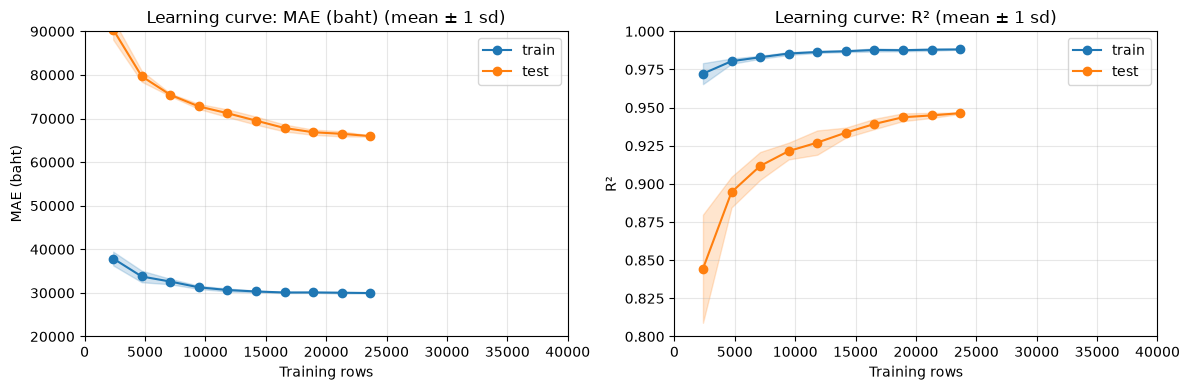

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (learning curve) ให้ขยาย MAE_AXIS / R2_AXIS / ROWS_AXIS ในเซลล์ [03]


In [34]:
# [34] learning curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดง lc_table จากเซลล์ [33] เป็นตาราง แล้ววาดกราฟ 2 ช่องเคียงกัน (MAE และ R²)
#         แต่ละช่องมีเส้นค่าเฉลี่ยของ train และ test พร้อมแถบ ±1 sd
# ทำไม: ดูแนวโน้มว่าเมื่อเพิ่มแถวฝึกแล้วคะแนนเปลี่ยนอย่างไร และช่องว่างระหว่าง train กับ test
#       เปลี่ยนอย่างไร
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อขนาด และกราฟ 2 ช่อง
#   - ถ้า test MAE ยังลดลง (หรือ test R² ยังเพิ่ม) ที่ขนาดมาก ๆ อาจได้ประโยชน์จากข้อมูลเพิ่ม
#   - ถ้า train ดีกว่า test มาก แปลว่าโมเดลจำข้อมูลฝึกได้ดีกว่าข้อมูลใหม่ (อาการ overfit)
#     แต่สำหรับป่า train ดีกว่ามากเป็นเรื่องปกติ สิ่งที่ควรดูคือช่องว่างแคบลงเมื่อข้อมูลมากขึ้นหรือไม่
#     (เซลล์ [40] ตรวจข้อนี้ให้)
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS, R2_AXIS, ROWS_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - เป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่ใช่คำยืนยัน
#   - test ใช้อธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์
#   - แถบ ±1 sd คือความแกว่งจากการเลือกชุดย่อยต่างกัน ไม่ใช่ confidence interval
#     (ช่วงความเชื่อมั่น) และไม่รวมความไม่แน่นอนจากการสุ่ม test ชุดใหม่
#   - ที่ขนาดเต็ม ทุกรอบใช้แถวชุดเดียวกัน (แค่เรียงลำดับต่างกัน) จึงได้ sd = 0
#   - ช่องว่าง (gap) ต้องอ่านคู่กับระดับคะแนน ไม่ใช้วัด overfit เพียงลำพัง
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS, R2_AXIS, ROWS_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [34] learning curve: ตารางและกราฟ ===")

table_formats = {"rows": "{:,.0f}", "repeats": "{:.0f}"}
for column in lc_table.columns:
    if "MAE" in column:
        table_formats[column] = "{:,.0f}"
    elif "R2" in column:
        table_formats[column] = "{:.4f}"

print(f"อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม {LC_REPEATS} รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก")
display(lc_table.style.format(table_formats).hide(axis="index"))

out_of_axis = False
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, ylabel in zip(axes, ["MAE", "R2"], ["MAE (baht)", "R²"]):
    limits = MAE_AXIS if metric == "MAE" else R2_AXIS
    for part in ["train", "test"]:
        mean = lc_table[f"{part} {metric} mean"].to_numpy()
        sd = lc_table[f"{part} {metric} sd"].to_numpy()
        line, = ax.plot(lc_table["rows"], mean, marker="o", label=part)
        ax.fill_between(lc_table["rows"], mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < limits[0] or (mean + sd).max() > limits[1] or lc_table["rows"].max() > ROWS_AXIS[1]:
            out_of_axis = True
    ax.set(xlabel="Training rows", ylabel=ylabel, title=f"Learning curve: {ylabel} (mean ± 1 sd)")
    ax.set_xlim(*ROWS_AXIS)
    ax.set_ylim(*limits)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (learning curve) ให้ขยาย MAE_AXIS / R2_AXIS / ROWS_AXIS ในเซลล์ [03]")

=== [35] ตาราง CV train เทียบ validation ===
อ่านตาราง: หนึ่งแถวต่อ fold, MAE เป็นบาท, gap = validation - train (R² gap = train - validation)


,train MAE,validation MAE,MAE gap,gap % of validation MAE,train R2,validation R2,R2 gap
1,"30,383","73,102","42,719",58.44,0.9868,0.9343,0.0525
2,"29,895","79,514","49,619",62.40,0.9868,0.9082,0.0786
3,"29,907","76,102","46,196",60.70,0.9874,0.9176,0.0698
4,"29,725","76,283","46,558",61.03,0.9886,0.9120,0.0766
5,"30,267","71,654","41,387",57.76,0.9887,0.8967,0.0920
mean,"30,035","75,331","45,296",60.07,0.9877,0.9137,0.0739
sd,248,"2,738","2,933",1.72,0.0008,0.0123,0.0129


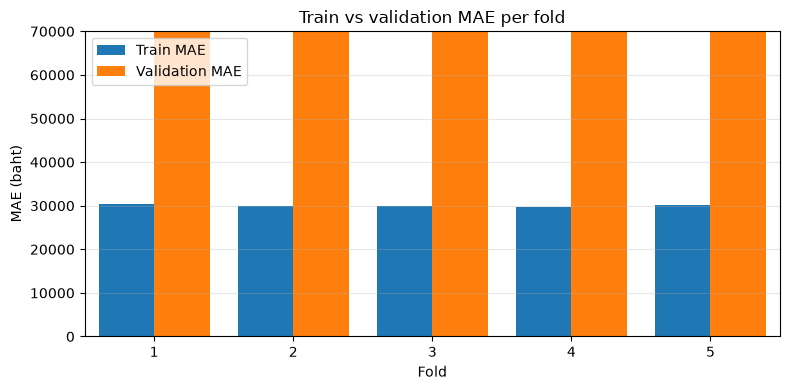

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟแท่ง CV train เทียบ validation) ให้ขยาย MAE_BAR_AXIS / FOLD_AXIS ในเซลล์ [03]


In [35]:
# [35] ตาราง CV train เทียบ validation
# ==================================================
# ทำอะไร: ดึงคะแนนของโมเดลผู้ชนะในแต่ละ fold ของ train จากผล grid search แล้วเทียบคะแนนบนแถวที่ใช้ฝึก
#         (train) กับแถวที่กันไว้ตรวจ (validation) ของ fold นั้น ทั้ง MAE (บาท) และ R²
#         (fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ, MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด)
# ทำไม: ดูขนาดและความสม่ำเสมอของช่องว่างระหว่าง train กับ validation
#       - train ดีกว่า validation มาก อาจเป็นสัญญาณ overfit (จำข้อมูลฝึกมากเกินไป)
#         แต่สำหรับป่า train ดีกว่ามากเสมอ (เหตุผลในเซลล์ [40]) ให้ดูความสม่ำเสมอข้าม fold มากกว่า
#       - ถ้าทั้งสองแย่และใกล้กัน อาจเป็น underfit (โมเดลง่ายเกินไป)
#       เซลล์นี้ไม่ตัดสินให้อัตโนมัติ ให้ดูระดับคะแนนและความกระจายร่วมกัน
#   ทำไมไม่ฝึกใหม่ (ต่างจากโน้ตบุ๊ค DT ที่เรียก cross_validate): GridSearchCV ฝึกชุดพารามิเตอร์ของผู้ชนะ
#   บน fold เดิมด้วย random_state เดิมไปแล้ว และเก็บคะแนนรายตัวไว้ใน split0_..., split1_..., ...
#   (เพราะ return_train_score=True) การฝึกซ้ำจะได้ต้นไม้ชุดเดิมและคะแนนเดิม (ต่างได้แค่เศษทศนิยม
#   หลักท้ายๆ จากลำดับการบวกคำทายของ thread) จึงอ่านจาก cv_results ได้เลย
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold (เลข fold เริ่มที่ 1) คอลัมน์ train MAE, validation MAE,
#              MAE gap (validation - train), gap เป็น % ของ validation MAE, train R²,
#              validation R², R² gap (train - validation) และท้ายตารางมีแถว mean กับ sd
#              (sd แบบ ddof=0 คำนวณจากแถว fold เท่านั้น) กับกราฟแท่งเทียบ train/validation MAE
#              แถว mean ของ validation MAE ต้องเท่ากับ CV MAE ของผู้ชนะในเซลล์ [27]
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_BAR_AXIS, FOLD_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - ใช้เฉพาะ train และ folds ไม่ใช้ val หรือ test และเป็นการตรวจผู้ชนะที่เลือกจาก fold เดิม
#     จึงไม่ใช่ผลประเมินอิสระจากการเลือกพารามิเตอร์
#   - ช่องว่างเป็นอาการที่ต้องอ่านคู่กับระดับ CV และความกระจาย ไม่ใช่มาตรวัด overfit เพียงลำพัง
#   - learning curve (เซลล์ [33]-[34]) เป็นการตรวจอีกแบบ ช่วยดูว่าเพิ่มแถวฝึกแล้วคะแนนและ
#     ช่องว่างเปลี่ยนอย่างไร ให้หลักฐานเชิงชี้แนะเท่านั้น
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_BAR_AXIS, FOLD_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [35] ตาราง CV train เทียบ validation ===")

rows = []
for fold_number in range(n_splits):
    train_mae = -cv_results[f"split{fold_number}_train_MAE"][chosen_index]  # กลับเครื่องหมายเป็นบวก
    validation_mae = -cv_results[f"split{fold_number}_test_MAE"][chosen_index]  # "test" = แถวตรวจ
    train_r2 = cv_results[f"split{fold_number}_train_R2"][chosen_index]
    validation_r2 = cv_results[f"split{fold_number}_test_R2"][chosen_index]
    rows.append({
        "train MAE": train_mae,
        "validation MAE": validation_mae,
        "MAE gap": validation_mae - train_mae,
        "gap % of validation MAE": (validation_mae - train_mae) * 100 / validation_mae,
        "train R2": train_r2,
        "validation R2": validation_r2,
        "R2 gap": train_r2 - validation_r2,
    })

fold_table = pd.DataFrame(rows, index=pd.Index(range(1, n_splits + 1), name="fold"))
summary_rows = pd.DataFrame(
    [fold_table.mean(), fold_table.std(ddof=0)],
    index=["mean", "sd"],
)
cv_check_table = pd.concat([fold_table, summary_rows])

table_formats = {
    "train MAE": "{:,.0f}",
    "validation MAE": "{:,.0f}",
    "MAE gap": "{:,.0f}",
    "gap % of validation MAE": "{:.2f}",
    "train R2": "{:.4f}",
    "validation R2": "{:.4f}",
    "R2 gap": "{:.4f}",
}
print("อ่านตาราง: หนึ่งแถวต่อ fold, MAE เป็นบาท, gap = validation - train (R² gap = train - validation)")
display(cv_check_table.style.format(table_formats))

positions = np.arange(len(fold_table))
bar_width = 0.4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(positions - bar_width / 2, fold_table["train MAE"], bar_width, label="Train MAE")
ax.bar(positions + bar_width / 2, fold_table["validation MAE"], bar_width, label="Validation MAE")
ax.set_xticks(positions, fold_table.index)
ax.set(xlabel="Fold", ylabel="MAE (baht)", title="Train vs validation MAE per fold")
ax.set_xlim(*FOLD_AXIS)
ax.set_ylim(*MAE_BAR_AXIS)
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if (
    fold_table[["train MAE", "validation MAE"]].max().max() > MAE_BAR_AXIS[1]
    or len(fold_table) - 1 + bar_width > FOLD_AXIS[1]
):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟแท่ง CV train เทียบ validation) ให้ขยาย MAE_BAR_AXIS / FOLD_AXIS ในเซลล์ [03]")

In [36]:
# [36] validation curve: คำนวณ
# ==================================================
# ทำอะไร: สร้าง validation curve ของทุกพารามิเตอร์ที่ปรับ (max_features, min_samples_leaf)
#         คือเปลี่ยนพารามิเตอร์ทีละตัวตามทุกค่าใน PARAM_GRID โดยคงพารามิเตอร์อีกตัวไว้ตามผู้ชนะ
#         แล้วเก็บ MAE บนส่วนฝึกและส่วนตรวจสอบ (validation) ของ fold ลง vc_results
#         (validation curve = กราฟคะแนนเมื่อเปลี่ยนพารามิเตอร์หนึ่งตัว,
#          fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ,
#          MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          sd = ส่วนเบี่ยงเบนมาตรฐานข้าม fold แบบ ddof=0)
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวทำให้โมเดลซับซ้อนขึ้น/ง่ายลงแล้ว MAE ฝึกกับ MAE ตรวจสอบ
#       ห่างกันอย่างไร เพื่ออ่านความซับซ้อนร่วมกับช่องว่างของคะแนน
#   ทำไมไม่ฝึกใหม่ (ต่างจากโน้ตบุ๊ค DT ที่เรียก validation_curve): ทุกจุดบนเส้นคือชุดพารามิเตอร์ที่อยู่ใน
#   grid อยู่แล้ว (ค่าหนึ่งตัวจาก PARAM_GRID + อีกตัวเท่าผู้ชนะ) และ GridSearchCV ฝึกชุดนั้นบน fold เดิม
#   ด้วย random_state เดิมไปแล้ว การเรียก validation_curve จะฝึกซ้ำได้ต้นไม้ชุดเดิมและคะแนนเดิม
#   (ต่างได้แค่เศษทศนิยมหลักท้ายๆ จากลำดับการบวกคำทายของ thread)
#   จึงอ่านค่าเฉลี่ยและ sd จาก cv_results มาใช้ ประหยัดการฝึกได้หลายสิบครั้ง
# ผลที่ควรเห็น: ข้อความหนึ่งบรรทัดต่อพารามิเตอร์ จากนั้น vc_results พร้อมให้เซลล์ [37]
#              แสดงตารางและกราฟ (ไม่มีผลลัพธ์อื่นในเซลล์นี้)
# ข้อควรระวัง:
#   - ใช้ผลของ train กับ folds เดิมเท่านั้น ไม่เปลี่ยน search
#   - ค่าที่แสดงคือทุกค่าใน PARAM_GRID ตามลำดับเดิม
# ==================================================
print("=== [36] validation curve: คำนวณ ===")

vc_results = {}
for name in PARAM_GRID:
    values = list(PARAM_GRID[name])
    indices = []
    for value in values:
        target = dict(search.best_params_)  # พารามิเตอร์ผู้ชนะ แล้วเปลี่ยนแค่ตัวที่กำลังดู
        target["model__" + name] = value
        indices.append(cv_results["params"].index(target))
    vc_results[name] = {
        "values": values,
        "train_mean": train_mae_all[indices],
        "train_sd": cv_results["std_train_MAE"][indices],
        "cv_mean": cv_mae_all[indices],
        "cv_sd": cv_results["std_test_MAE"][indices],
    }
    print(f"{name} เสร็จ ({len(values)} ค่า)")

=== [36] validation curve: คำนวณ ===
max_features เสร็จ (7 ค่า)
min_samples_leaf เสร็จ (6 ค่า)


=== [37] validation curve: ตารางและกราฟ ===
อ่านตาราง max_features: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
0.2,"29,911","74,263","2,680","44,352"
0.3,"29,882","74,326","2,657","44,443"
0.4,"29,904","74,481","2,698","44,578"
0.5,"29,876","74,599","2,664","44,723"
0.6,"29,957","74,803","2,646","44,846"
0.8,"30,035","75,331","2,738","45,296"
1.0,"30,266","75,987","2,788","45,721"


อ่านตาราง min_samples_leaf: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
1,"30,035","75,331","2,738","45,296"
2,"46,980","76,817","2,987","29,837"
3,"56,615","80,019","3,318","23,404"
4,"63,460","83,120","3,482","19,660"
6,"73,001","88,553","3,651","15,552"
8,"80,336","93,121","3,558","12,785"


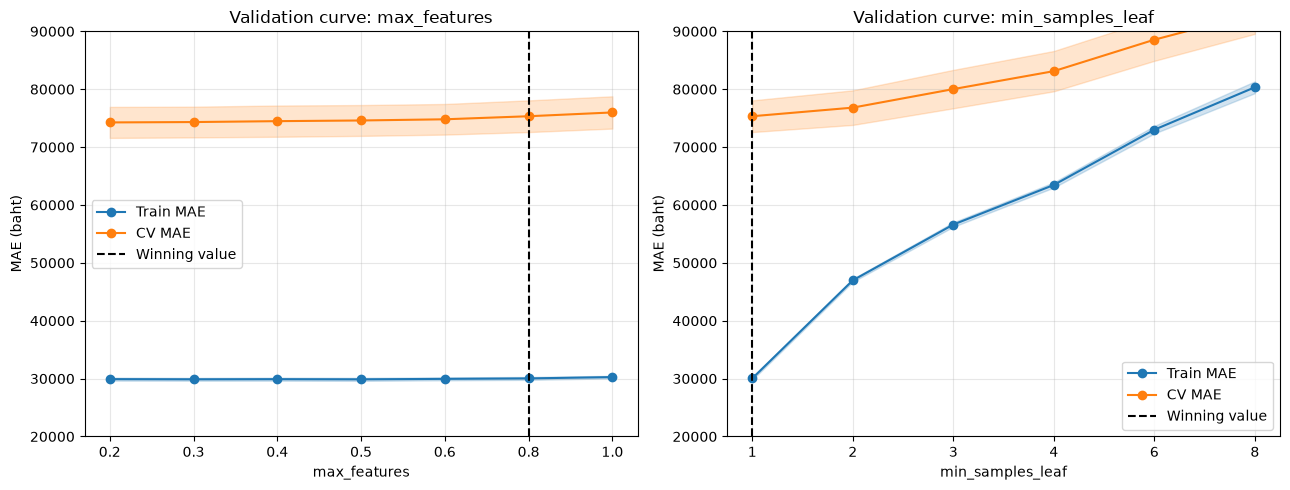

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]


In [37]:
# [37] validation curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดงตารางของแต่ละพารามิเตอร์จาก vc_results (เซลล์ [36]) แล้ววาดกราฟ 2 ช่องเคียงกัน
#         เส้น train และ CV MAE เฉลี่ย พร้อมแถบ ±1 sd และเส้นประแนวตั้งที่ค่าของผู้ชนะ
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวพาโมเดลไปทาง overfit หรือ underfit
#       (overfit = จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี, underfit = ง่ายเกินจนจับแบบแผนไม่ได้)
# วิธีอ่าน:
#   - min_samples_leaf: ยิ่งเล็ก ต้นไม้ยิ่งซับซ้อน (ใบเล็ก จำรายละเอียดได้มาก) train MAE จะต่ำลงมาก
#     ฝั่งค่าใหญ่ใบหยาบเกินไป ทั้ง train และ CV MAE สูงขึ้น (underfit)
#   - max_features: ยิ่งมาก แต่ละต้นยิ่งแม่นแต่ต้นไม้คล้ายกันมากขึ้น การเฉลี่ยจึงช่วยลดความผิดพลาด
#     ได้น้อยลง ยิ่งน้อย ต้นไม้ต่างกันมากแต่แต่ละต้นอ่อนลง CV MAE จึงมักเป็นรูปตัว U
#     (บนกราฟ ตำแหน่ง x เรียงตามลำดับค่าใน PARAM_GRID ไม่ใช่ระยะห่างจริง)
#   - overfit: train MAE ต่ำมากแต่ CV MAE สูงกว่ามาก (ช่องว่างกว้าง) มักเกิดทางด้านซับซ้อน
#     (สำหรับป่า train MAE ต่ำกว่ามากเป็นปกติ ให้ดูว่า CV MAE แย่ลงหรือไม่เป็นหลัก)
#   - underfit: ทั้ง train และ CV MAE สูงและใกล้กัน มักเกิดทางด้านง่าย
#   - ผู้ชนะ (เส้นประ) ไม่จำเป็นต้องอยู่ที่จุดต่ำสุดของ CV MAE เพราะกฎ 1-SE
#     (เลือกป่าที่ใบรวมน้อยที่สุดที่ CV MAE ไม่แย่กว่าค่าต่ำสุดเกิน 1 SE) ชอบรุ่นที่ง่ายกว่า
# ผลที่ควรเห็น: ตาราง 2 ตาราง (คอลัมน์ value, train MAE mean, CV MAE mean, CV MAE sd, gap
#              โดย gap = CV MAE - train MAE) และรูปเดียวที่มี 2 กราฟ
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: ตารางและกราฟนี้ใช้ train กับ folds เดิม จึงไม่ใช่ผลประเมินอิสระ
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [37] validation curve: ตารางและกราฟ ===")

parameter_names = list(PARAM_GRID)

for name in parameter_names:
    result = vc_results[name]
    table = pd.DataFrame(
        {
            "value": [str(value) for value in result["values"]],
            "train MAE mean": result["train_mean"],
            "CV MAE mean": result["cv_mean"],
            "CV MAE sd": result["cv_sd"],
            "gap": result["cv_mean"] - result["train_mean"],
        }
    )
    print(f"อ่านตาราง {name}: MAE เป็นบาท, gap = CV MAE - train MAE")
    display(
        table.style
        .format(
            {
                "train MAE mean": "{:,.0f}",
                "CV MAE mean": "{:,.0f}",
                "CV MAE sd": "{:,.0f}",
                "gap": "{:,.0f}",
            }
        )
        .hide(axis="index")
    )

out_of_axis = False
fig, axes = plt.subplots(1, len(parameter_names), figsize=(13, 5))
for ax, name in zip(axes, parameter_names):
    result = vc_results[name]
    values = result["values"]
    positions = np.arange(len(values))  # ใช้ตำแหน่งแทนค่าจริง ระยะห่างบนแกน x จึงเท่ากันทุกค่า

    for mean, sd, label in [
        (result["train_mean"], result["train_sd"], "Train MAE"),
        (result["cv_mean"], result["cv_sd"], "CV MAE"),
    ]:
        line, = ax.plot(positions, mean, marker="o", label=label)
        ax.fill_between(positions, mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < MAE_AXIS[0] or (mean + sd).max() > MAE_AXIS[1]:
            out_of_axis = True

    ax.axvline(values.index(best_params[name]), color="black", linestyle="--", label="Winning value")
    ax.set_xticks(positions, [str(value) for value in values])
    ax.set(xlabel=name, ylabel="MAE (baht)", title=f"Validation curve: {name}")
    ax.set_ylim(*MAE_AXIS)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]")

In [38]:
# [38] กราฟ OOB: คำนวณ
# ==================================================
# ทำอะไร: ฝึกป่าด้วยพารามิเตอร์ของผู้ชนะบน train ทั้งชุด แล้วค่อยๆ เพิ่มจำนวนต้นไม้ตาม OOB_TREE_COUNTS
#         (50, 100, ... 1,000 ต้น) ทุกจุดวัด OOB MAE เก็บลง oob_table
#         OOB MAE = MAE เมื่อทายแต่ละแถวของ train ด้วยเฉพาะต้นไม้ที่ไม่ได้หยิบแถวนั้นไปฝึก
#         (แต่ละต้นไม่ได้หยิบแถวราว 37% จาก bootstrap แถวเหล่านั้นเป็น "ข้อมูลใหม่" ของต้นนั้น)
# ทำไม: เป็นหลักฐานว่า N_TREES (เซลล์ [03]) อยู่บนช่วงที่กราฟแบนแล้ว คือเพิ่มต้นไม้อีกก็แทบไม่ดีขึ้น
#       ใช้ train อย่างเดียว ไม่แตะ validation / test
#   - warm_start=True ทำให้ fit ครั้งถัดไป "เพิ่ม" ต้นไม้ต่อจากของเดิม ไม่ฝึกใหม่ทั้งป่า
#     และ sklearn กำหนดเลขสุ่มของแต่ละต้นจาก random_state ตามลำดับ ป่า N_TREES ต้นแรกที่นี่จึงเหมือน
#     ป่าของโมเดลผู้ชนะ (search.best_estimator_) ทุกต้น OOB MAE ที่ N_TREES ต้นจึงเป็นค่า OOB
#     ของโมเดลสุดท้ายพอดี เซลล์ [40] ใช้ค่านี้ตรวจ overfit
#   - oob_score=True สั่งให้ป่าคำนวณคำทาย OOB (oob_prediction_) ทุกครั้งที่ fit
#   - แปลงข้อมูลด้วย FoldOneHot ครั้งเดียวบน train ทั้งชุด (ไม่ต้องใช้ Pipeline เพราะไม่มี fold
#     ให้กันข้อมูลรั่ว OOB ของแต่ละแถวมาจากต้นที่ไม่เคยเห็นแถวนั้นอยู่แล้ว ส่วน encoder จำแค่รายชื่อระดับ
#     ไม่ได้ดูราคา)
# ผลที่ควรเห็น: หนึ่งบรรทัดต่อจำนวนต้นไม้ บอก OOB MAE (ราว 1-2 นาทีทั้งเซลล์ ประมาณจาก pilot)
#       เส้นควรลดลงเร็วช่วงแรกแล้วแบนลง เซลล์ [39] แสดงตาราง กราฟ และตรวจให้
# ข้อควรระวัง:
#   - OOB ที่ T ต้น ใช้ต้นไม้ราว 37% ของ T ทายแต่ละแถว จึงแย่กว่าป่าเต็ม T ต้นจริงเล็กน้อย
#     ถ้ากราฟ OOB แบนแล้วที่ N_TREES ป่าเต็มจริงก็แบนแล้วเช่นกัน (การตรวจนี้จึงเข้มกว่าจริงเล็กน้อย)
#   - ป่า 1,000 ต้นใช้หน่วยความจำมาก (หลายร้อย MB) เซลล์นี้จึงลบทิ้งเมื่อได้ตัวเลขครบ
# ==================================================
print("=== [38] กราฟ OOB: คำนวณ ===")

encoded_train = FoldOneHot(NUM_COLS, CAT_COLS).fit_transform(train[features])
forest = make_model().set_params(**best_params, warm_start=True, oob_score=True)

rows = []
for tree_count in OOB_TREE_COUNTS:
    forest.set_params(n_estimators=tree_count)
    forest.fit(encoded_train, train_prices)  # เพิ่มต้นไม้ต่อจากของเดิม (warm_start)
    oob_errors = np.abs(train_prices - forest.oob_prediction_)
    if tree_count == N_TREES:
        oob_errors_at_n_trees = oob_errors  # เก็บไว้ให้เซลล์ [40] ใช้
    rows.append({"trees": tree_count, "oob_mae": oob_errors.mean()})
    print(f"{tree_count:>5,} ต้น: OOB MAE {oob_errors.mean():,.0f} บาท")

oob_table = pd.DataFrame(rows)
del forest  # คืนหน่วยความจำของป่าใหญ่

=== [38] กราฟ OOB: คำนวณ ===


   50 ต้น: OOB MAE 74,490 บาท


  100 ต้น: OOB MAE 73,703 บาท


  150 ต้น: OOB MAE 73,383 บาท


  200 ต้น: OOB MAE 73,260 บาท


  300 ต้น: OOB MAE 73,029 บาท


  400 ต้น: OOB MAE 72,963 บาท


  600 ต้น: OOB MAE 72,855 บาท


  800 ต้น: OOB MAE 72,804 บาท


1,000 ต้น: OOB MAE 72,794 บาท


=== [39] กราฟ OOB: ตาราง กราฟ และตรวจว่าแบนแล้ว ===
อ่านตาราง: OOB MAE (บาท) ที่แต่ละจำนวนต้นไม้ และสูงกว่าค่าที่จุดสุดท้ายกี่เปอร์เซ็นต์


trees,oob_mae,above last %
50,"74,490",2.33
100,"73,703",1.25
150,"73,383",0.81
200,"73,260",0.64
300,"73,029",0.32
400,"72,963",0.23
600,"72,855",0.08
800,"72,804",0.01
"1,000","72,794",0.00


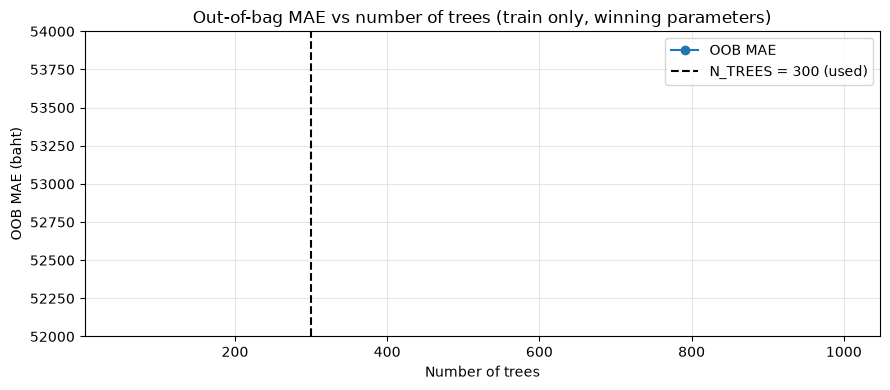

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟ OOB) ให้ขยาย MAE_OOB_AXIS ในเซลล์ [03]
จำนวนต้นที่ใช้ (N_TREES)    : 300 ต้น, OOB MAE 73,029 บาท
จำนวนต้นมากสุดบนกราฟ      : 1,000 ต้น, OOB MAE 72,794 บาท
ลดลงได้อีกเมื่อเพิ่มต้นไม้   : 235 บาท (0.32%)
เกณฑ์ (1 SE ของ CV MAE)    : 1,198 บาท
PASS: 300 ต้นอยู่บนช่วงที่กราฟแบนแล้ว (เพิ่มต้นไม้อีกได้ผลน้อยกว่า 1 SE)


In [39]:
# [39] กราฟ OOB: ตาราง กราฟ และตรวจว่าแบนแล้ว
# ==================================================
# ทำอะไร: แสดง oob_table จากเซลล์ [38] เป็นตาราง วาดกราฟ OOB MAE เทียบจำนวนต้นไม้ พร้อมเส้นประที่
#         N_TREES แล้วตรวจว่าการเพิ่มต้นไม้จาก N_TREES ไปถึงจุดสุดท้ายของกราฟ ช่วยลด OOB MAE ได้
#         น้อยกว่าเกณฑ์หรือไม่ (PASS = แบนแล้ว)
# ทำไม: n_estimators ไม่ได้ปรับใน grid (เหตุผลในเซลล์ [03]) จึงต้องมีหลักฐานว่าค่าที่ตั้งไว้ "พอแล้ว"
#   เกณฑ์ = 1 SE ของ CV MAE ที่กฎ 1-SE ใช้ (เกณฑ์ 1-SE ลบ CV MAE ต่ำสุด จากเซลล์ [27])
#   เหตุผล: กฎ 1-SE ถือว่าผลที่ต่างกันไม่เกิน 1 SE คือ "ดีพอๆ กัน" ถ้าเพิ่มต้นไม้อีกราว 3 เท่าแล้ว
#   MAE ลดลงน้อยกว่าระยะนั้น การเพิ่มต้นไม้ก็ไม่คุ้มกับเวลาและหน่วยความจำที่เพิ่มตามจำนวนต้นตรงๆ
# ผลที่ควรเห็น: ตาราง (จำนวนต้นไม้, OOB MAE, สูงกว่าจุดสุดท้ายกี่ %), กราฟที่ลดลงเร็วช่วงแรกแล้วแบน
#       บรรทัดสรุปตัวเลข และบรรทัด PASS หรือ WARN
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_OOB_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: WARN แปลว่าควรเพิ่ม N_TREES ในเซลล์ [03] แล้วรันใหม่ (ไม่ได้แปลว่าโมเดล overfit
#       เพราะต้นไม้ที่มากขึ้นไม่ทำให้ป่า overfit)
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_OOB_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [39] กราฟ OOB: ตาราง กราฟ และตรวจว่าแบนแล้ว ===")

last_trees = int(oob_table["trees"].iloc[-1])
last_mae = oob_table["oob_mae"].iloc[-1]
n_trees_mae = oob_table.loc[oob_table["trees"] == N_TREES, "oob_mae"].iloc[0]
oob_table["above last %"] = (oob_table["oob_mae"] - last_mae) * 100 / last_mae

print("อ่านตาราง: OOB MAE (บาท) ที่แต่ละจำนวนต้นไม้ และสูงกว่าค่าที่จุดสุดท้ายกี่เปอร์เซ็นต์")
display(
    oob_table.style
    .format({"trees": "{:,.0f}", "oob_mae": "{:,.0f}", "above last %": "{:.2f}"})
    .hide(axis="index")
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(oob_table["trees"], oob_table["oob_mae"], marker="o", label="OOB MAE")
ax.axvline(N_TREES, color="black", linestyle="--", label=f"N_TREES = {N_TREES} (used)")
ax.set(
    xlabel="Number of trees",
    ylabel="OOB MAE (baht)",
    title="Out-of-bag MAE vs number of trees (train only, winning parameters)",
)
ax.set_ylim(*MAE_OOB_AXIS)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if oob_table["oob_mae"].min() < MAE_OOB_AXIS[0] or oob_table["oob_mae"].max() > MAE_OOB_AXIS[1]:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟ OOB) ให้ขยาย MAE_OOB_AXIS ในเซลล์ [03]")

gain = n_trees_mae - last_mae
standard_error = threshold - cv_mae_all[min_index]  # 1 SE ที่กฎ 1-SE ใช้ (เซลล์ [27])
print(f"จำนวนต้นที่ใช้ (N_TREES)    : {N_TREES:,} ต้น, OOB MAE {n_trees_mae:,.0f} บาท")
print(f"จำนวนต้นมากสุดบนกราฟ      : {last_trees:,} ต้น, OOB MAE {last_mae:,.0f} บาท")
print(f"ลดลงได้อีกเมื่อเพิ่มต้นไม้   : {gain:,.0f} บาท ({gain * 100 / last_mae:.2f}%)")
print(f"เกณฑ์ (1 SE ของ CV MAE)    : {standard_error:,.0f} บาท")
if gain <= standard_error:
    print(f"PASS: {N_TREES} ต้นอยู่บนช่วงที่กราฟแบนแล้ว (เพิ่มต้นไม้อีกได้ผลน้อยกว่า 1 SE)")
else:
    print("WARN: เพิ่มต้นไม้แล้วยังดีขึ้นเกิน 1 SE ควรเพิ่ม N_TREES ในเซลล์ [03] แล้วรันใหม่")

In [40]:
# [40] สรุปการตรวจ overfit
# ==================================================
# ทำอะไร: รวมหลักฐานเรื่อง overfit ของโมเดลผู้ชนะไว้ที่เดียว แล้วพิมพ์ PASS หรือ WARN ทีละข้อพร้อมเกณฑ์
#   1) เทียบ MAE ที่ประเมินจากฝั่ง train (CV จากเซลล์ [27] และ OOB จากเซลล์ [38]) กับ MAE บนข้อมูลที่
#      ไม่เคยแตะเลย (validation และ test จากเซลล์ [30]) และเทียบ validation กับ test
#   2) learning curve (เซลล์ [33]): เมื่อแถวฝึกมากขึ้น test MAE ต้องลดลง และช่องว่าง train-test ต้องแคบลง
#   3) INFO: train MAE เทียบ CV MAE (พิมพ์ให้ดูเฉยๆ ไม่นับเป็น WARN เหตุผลอยู่ด้านล่าง)
# ทำไม:
#   - overfit คือโมเดลจำข้อมูลฝึกจนทายข้อมูลใหม่แย่ลง ถ้าเกิดขึ้น (หรือถ้าการเลือกพารามิเตอร์ไปเข้าข้าง
#     ความบังเอิญของ fold) MAE บน validation / test จะสูงกว่าค่าที่ประเมินจากฝั่ง train อย่างชัดเจน
#     CV และ OOB ต่างก็วัดบนแถวที่โมเดลตัวนั้นไม่ได้ฝึก จึงควรตรงกับ validation / test ถ้าไม่ overfit
#   - เกณฑ์ "ต่างกันได้ไม่เกิน 2 SE": MAE ที่วัดจากรถ n คันมีความคลาดเคลื่อนจากการสุ่มว่ารถคันไหนตกอยู่
#     ในชุดนั้น เรียกว่า SE (standard error) = sd ของ |ทายผิด| / sqrt(n) ส่วน SE ของ CV ใช้
#     std ของ MAE ราย fold / sqrt(จำนวน fold) แบบเดียวกับกฎ 1-SE ผลต่างของค่าประมาณสองค่ามี
#     SE = sqrt(SE1² + SE2²) ถ้าต่างกันเกิน 2 เท่าของค่านี้ (ราว 95% ของความต่างที่เกิดจากการสุ่มล้วนๆ
#     จะไม่เกินระยะนี้ ตามการประมาณแบบการแจกแจงปกติ) จึงไม่น่าใช่แค่ความบังเอิญ ให้ WARN
#     เกณฑ์คิดจากข้อมูลจริงทุกครั้ง ไม่ได้ตั้งเลขตายตัว
#   - ทิศของความต่าง: validation / test แย่กว่าเกินเกณฑ์ = สัญญาณ overfit
#     (ค่าที่ประเมินจากฝั่ง train มองโลกในแง่ดีเกินไป) ส่วน validation / test ดีกว่าเกินเกณฑ์
#     ไม่ใช่ overfit แต่ควรหาสาเหตุ เช่น แถวที่ค่าเหมือนกันข้ามชุด (ต่างกันแค่สี ดูเซลล์ [13])
#     ทำให้ชุดนั้นง่ายขึ้นเล็กน้อย
#   - ความต่างเล็กๆ ที่คาดได้ล่วงหน้า: โมเดลสุดท้ายฝึกบน train ทั้งชุด (CV ฝึกบน 4/5)
#     จึงมักดีกว่า CV นิดหน่อย OOB ใช้ต้นไม้ราว 37% ต่อแถวจึงแย่กว่าป่าเต็มนิดหน่อย
#     และ CV MAE ของผู้ชนะที่ถูกเลือกจาก 42 ชุดอาจดีเกินจริงเล็กน้อย (กฎ 1-SE ลดผลนี้ลง เพราะไม่ได้เลือกชุดที่ต่ำสุดตรงๆ)
#   - learning curve: โมเดลที่ไม่ overfit จะทายข้อมูลใหม่ดีขึ้นเมื่อมีข้อมูลฝึกมากขึ้น และช่องว่าง
#     train-test แคบลง ถ้าช่องว่างกว้างขึ้นหรือ test MAE ไม่ลดลง ถือว่าผิดปกติ ให้ WARN
#   - ความจริงเฉพาะของป่าสุ่ม: train MAE ต่ำกว่า CV MAE มากเสมอ เพราะต้นไม้แต่ละต้นโตจนเกือบจำแถวใน
#     bootstrap ของตัวเองได้ และแต่ละแถวของ train อยู่ใน bootstrap ของต้นไม้ราว 63% ของป่า
#     คำทายบน train จึงเหมือนได้ดูคำตอบไปแล้วบางส่วน ช่องว่างนี้ลำพังไม่ใช่ overfit
#     (ถ้าป่า overfit จริง CV / OOB / validation / test จะแย่ลงด้วย ซึ่งข้อ 1 ตรวจอยู่แล้ว)
# ผลที่ควรเห็น: ตารางย่อ MAE ± SE ของ CV, OOB, validation, test แล้วบรรทัด PASS/WARN 6 บรรทัด
#       บรรทัด INFO 1 บรรทัด และบรรทัดสรุปสุดท้าย
# ข้อควรระวัง: PASS ทุกข้อแปลว่า "ไม่พบหลักฐาน overfit" ตามเกณฑ์เหล่านี้ ไม่ใช่การพิสูจน์ว่าไม่มีเลย
#       และ test ใช้ตรวจอย่างเดียว ห้ามย้อนกลับไปปรับโมเดลตามผลนี้
# ==================================================
print("=== [40] สรุปการตรวจ overfit ===")

estimates = {
    "CV": (cv_mae_all[chosen_index], cv_results["std_test_MAE"][chosen_index] / np.sqrt(n_splits)),
    "OOB": (
        oob_errors_at_n_trees.mean(),
        oob_errors_at_n_trees.std(ddof=1) / np.sqrt(len(oob_errors_at_n_trees)),
    ),
}
for name, part in [("validation", val), ("test", test)]:
    errors = np.abs(part["price"].to_numpy() - model.predict(part[features]))
    estimates[name] = (errors.mean(), errors.std(ddof=1) / np.sqrt(len(errors)))

print("MAE ของโมเดลผู้ชนะจากแต่ละแหล่ง (± 1 SE)")
for name, (mae, standard_error) in estimates.items():
    print(f"  {name:<10}: {mae:,.0f} ± {standard_error:,.0f} บาท")

warn_count = 0
comparisons = [
    ("validation", "CV"),
    ("test", "CV"),
    ("validation", "OOB"),
    ("test", "OOB"),
    ("test", "validation"),
]
for held_out, reference in comparisons:
    held_out_mae, held_out_se = estimates[held_out]
    reference_mae, reference_se = estimates[reference]
    difference = held_out_mae - reference_mae
    band = 2 * np.sqrt(held_out_se**2 + reference_se**2)
    if abs(difference) <= band:
        status = "PASS"
    else:
        status = "WARN"
        warn_count = warn_count + 1
    label = f"{held_out} เทียบ {reference}"
    print(
        f"{status} {label:<24}: ต่างกัน {difference:+,.0f} บาท "
        f"({difference * 100 / reference_mae:+.2f}%) เกณฑ์ ±{band:,.0f} บาท (2 SE)"
    )

first = lc_table.iloc[0]
last = lc_table.iloc[-1]
first_gap = first["test MAE mean"] - first["train MAE mean"]
last_gap = last["test MAE mean"] - last["train MAE mean"]
if last["test MAE mean"] < first["test MAE mean"] and last_gap < first_gap:
    status = "PASS"
else:
    status = "WARN"
    warn_count = warn_count + 1
print(
    f"{status} learning curve ({int(first['rows']):,} -> {int(last['rows']):,} แถว): "
    f"test MAE {first['test MAE mean']:,.0f} -> {last['test MAE mean']:,.0f} บาท, "
    f"gap {first_gap:,.0f} -> {last_gap:,.0f} บาท (ต้องลดลงทั้งคู่)"
)

train_ratio = results["train"]["MAE"] / estimates["CV"][0]
print(
    f"INFO train MAE {results['train']['MAE']:,.0f} บาท = {train_ratio:.4f} เท่าของ CV MAE "
    "(ต่ำกว่ามากเป็นปกติของป่าสุ่ม ไม่นับเป็น WARN)"
)

if warn_count == 0:
    print("สรุป: PASS ทุกข้อ ไม่พบหลักฐานว่าโมเดล overfit ตามเกณฑ์ของเซลล์นี้")
else:
    print(f"สรุป: มี WARN {warn_count} ข้อ อ่านคำอธิบายทิศของความต่างที่หัวเซลล์ก่อนนำโมเดลไปใช้")

=== [40] สรุปการตรวจ overfit ===


MAE ของโมเดลผู้ชนะจากแต่ละแหล่ง (± 1 SE)
  CV        : 75,331 ± 1,225 บาท
  OOB       : 73,029 ± 1,072 บาท
  validation: 71,935 ± 3,254 บาท
  test      : 65,864 ± 2,212 บาท
PASS validation เทียบ CV     : ต่างกัน -3,396 บาท (-4.51%) เกณฑ์ ±6,954 บาท (2 SE)
WARN test เทียบ CV           : ต่างกัน -9,467 บาท (-12.57%) เกณฑ์ ±5,057 บาท (2 SE)
PASS validation เทียบ OOB    : ต่างกัน -1,094 บาท (-1.50%) เกณฑ์ ±6,853 บาท (2 SE)
WARN test เทียบ OOB          : ต่างกัน -7,165 บาท (-9.81%) เกณฑ์ ±4,916 บาท (2 SE)
PASS test เทียบ validation   : ต่างกัน -6,071 บาท (-8.44%) เกณฑ์ ±7,870 บาท (2 SE)
PASS learning curve (2,365 -> 23,657 แถว): test MAE 90,412 -> 65,971 บาท, gap 52,527 -> 36,005 บาท (ต้องลดลงทั้งคู่)
INFO train MAE 29,939 บาท = 0.3974 เท่าของ CV MAE (ต่ำกว่ามากเป็นปกติของป่าสุ่ม ไม่นับเป็น WARN)
สรุป: มี WARN 2 ข้อ อ่านคำอธิบายทิศของความต่างที่หัวเซลล์ก่อนนำโมเดลไปใช้


=== [41] ความสำคัญแบบ permutation บน test ===


Permutation importance: increase in test MAE (baht)
variable        mean       std  share (%)
  engine 178663.4754 4573.0986    29.4657
 car_age 176320.6212 4441.1522    29.0793
   brand 105340.0420 2189.0965    17.3730
car_type  63312.4913 2923.0630    10.4417
   model  34878.9401  683.4423     5.7523
 mileage  27662.6779 1802.8447     4.5622
    fuel  13525.9700  626.6354     2.2307
    gear   6638.8686  314.6281     1.0949


,variable,mean,std,share (%)
0,engine,178663.475386,4573.098558,29.465740
1,car_age,176320.621236,4441.152166,29.079349
2,brand,105340.042029,2189.096504,17.373009
3,car_type,63312.491289,2923.063010,10.441694
4,model,34878.940087,683.442340,5.752344
5,mileage,27662.677941,1802.844657,4.562215
6,fuel,13525.970017,626.635351,2.230745
7,gear,6638.868598,314.628148,1.094903


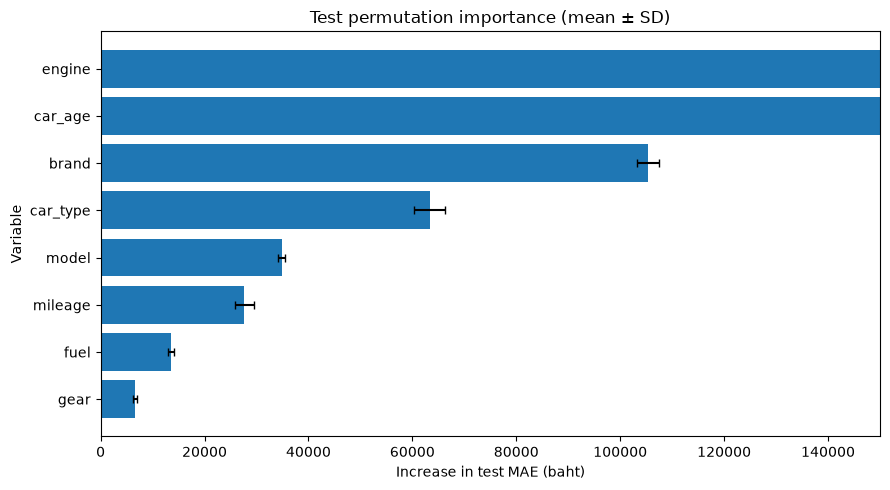

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (permutation importance) ให้ขยาย PERM_AXIS ในเซลล์ [03]


In [41]:
# [41] ความสำคัญแบบ permutation บน test
# ==================================================
# ทำอะไร: สลับตัวแปรต้นฉบับทีละคอลัมน์ก่อน encoding สิบรอบแล้ววัด MAE ที่เพิ่มเป็นบาท
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ค่าติดลบเกิดได้; share ใช้ผลรวมมีเครื่องหมาย ไม่ตัดค่าลบทิ้ง; ถ้าผลรวมศูนย์ให้ share เป็นศูนย์
# ==================================================
print("=== [41] ความสำคัญแบบ permutation บน test ===")

importance_estimator = search.best_estimator_
X_test = test[features]
y_test = test["price"]
assert len(features) == 8 and list(X_test.columns) == features
permutation_result = permutation_importance(
    importance_estimator, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=SEED,
)
permutation_table = pd.DataFrame({"variable": features, "mean": permutation_result.importances_mean,
                                  "std": permutation_result.importances_std})
# ใช้ผลรวมแบบมีเครื่องหมาย ค่าลบหมายถึงสลับแล้วดีขึ้น; ถ้าผลรวมเป็นศูนย์ให้ share เป็นศูนย์
total_increase = permutation_table["mean"].sum()
permutation_table["share (%)"] = (100 * permutation_table["mean"] / total_increase
                                   if total_increase != 0 else 0.0)
permutation_table = permutation_table.sort_values("mean", ascending=False, kind="stable").reset_index(drop=True)
print("Permutation importance: increase in test MAE (baht)")
print(permutation_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(permutation_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(permutation_table["variable"], permutation_table["mean"], xerr=permutation_table["std"], capsize=3)
ax.invert_yaxis()
ax.set(xlabel="Increase in test MAE (baht)", ylabel="Variable", title="Test permutation importance (mean ± SD)")
ax.set_xlim(*PERM_AXIS)
plt.tight_layout()
plt.show()
if ((permutation_table["mean"] - permutation_table["std"]).min() < PERM_AXIS[0]
        or (permutation_table["mean"] + permutation_table["std"]).max() > PERM_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (permutation importance) ให้ขยาย PERM_AXIS ในเซลล์ [03]")


=== [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===


Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)
variable  model_based
   brand     0.312120
 car_age     0.187137
  engine     0.180100
   model     0.122573
 mileage     0.094989
car_type     0.065203
    fuel     0.035175
    gear     0.002704


,variable,model_based
3,brand,0.312120
2,car_age,0.187137
0,engine,0.180100
4,model,0.122573
1,mileage,0.094989
5,car_type,0.065203
6,fuel,0.035175
7,gear,0.002704


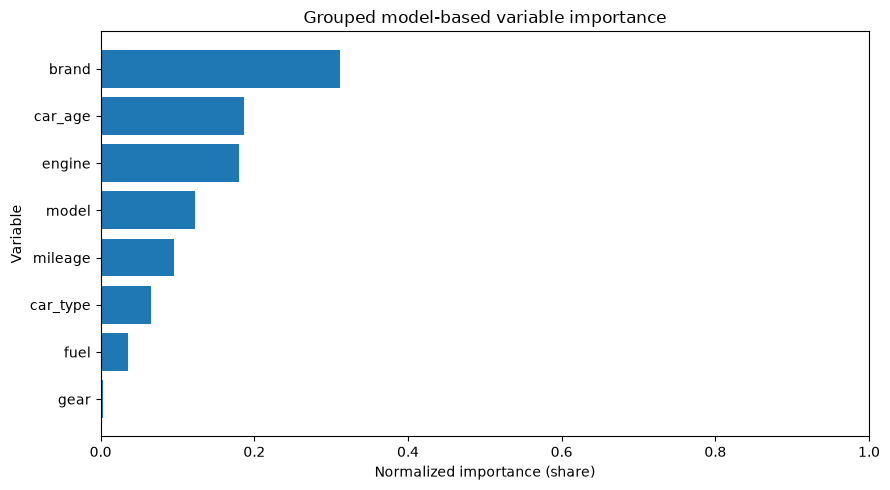

In [42]:
# [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร
# ==================================================
# ทำอะไร: รวม impurity หรือ gain ของ dummy กลับเป็นแปดตัวแปรและ normalize ให้รวมเป็นหนึ่ง
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ใช้ผู้ชนะที่ fit บน train แล้ว; gain ขอผ่าน booster อย่างชัดเจน; ระดับมากอาจได้เปรียบ
# ==================================================
print("=== [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===")

fitted_model = importance_estimator.named_steps["model"]
if isinstance(fitted_model, TransformedTargetRegressor):
    fitted_model = fitted_model.regressor_
encoded_names = importance_estimator.named_steps["encode"].get_feature_names_out()
if MODEL_NAME == "XGB":
    # ขอ gain อย่างชัดเจนและจับคู่ชื่อตามลำดับจริงของ encoder (รองรับทั้งชื่อจริงและ f0, f1)
    booster = fitted_model.get_booster()
    gains = booster.get_score(importance_type="gain")
    booster_names = booster.feature_names
    if booster_names is None:
        booster_names = [f"f{i}" for i in range(len(encoded_names))]
    else:
        assert booster_names == list(encoded_names), "Booster feature order differs from encoder output"
    assert len(booster_names) == len(encoded_names)
    assert set(gains).issubset(booster_names), "Unknown booster feature name"
    weights = np.asarray([gains.get(name, 0.0) for name in booster_names], dtype=float)
else:
    weights = np.asarray(fitted_model.feature_importances_, dtype=float)
assert len(weights) == len(encoded_names)
grouped_importance = {name: 0.0 for name in features}
for encoded_name, weight in zip(encoded_names, weights):
    original_name = str(encoded_name).split("=", 1)[0]
    assert original_name in grouped_importance, f"Unknown encoded variable: {encoded_name}"
    grouped_importance[original_name] += float(weight)
total_weight = sum(grouped_importance.values())
assert total_weight > 0, "โมเดลไม่มีความสำคัญที่เป็นบวกให้ normalize"
grouped_importance = {name: weight / total_weight for name, weight in grouped_importance.items()}
assert np.isclose(sum(grouped_importance.values()), 1.0)
model_importance_table = pd.DataFrame({"variable": features,
    "model_based": [grouped_importance[name] for name in features]}).sort_values("model_based", ascending=False, kind="stable")
print("Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)")
print(model_importance_table.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
display(model_importance_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(model_importance_table["variable"], model_importance_table["model_based"])
ax.invert_yaxis()
ax.set(xlabel="Normalized importance (share)", ylabel="Variable", title="Grouped model-based variable importance")
ax.set_xlim(*SHARE_AXIS)
plt.tight_layout()
plt.show()
if (model_importance_table["model_based"].min() < SHARE_AXIS[0]
        or model_importance_table["model_based"].max() > SHARE_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (model importance) ให้ขยาย SHARE_AXIS ในเซลล์ [03]")


In [43]:
# [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON
# ==================================================
# ทำอะไร: แสดงความสำคัญและอันดับทั้งสองวิธีเคียงกันแล้วพิมพ์ JSON หนึ่งบรรทัด
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: เมื่อผลสองวิธีขัดกันควรเชื่อ permutation บนข้อมูลที่ไม่เคยเห็นมากกว่า
# ==================================================
print("=== [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===")

# impurity/gain เอนเอียงไปหาตัวแปรที่มีหลายระดับ เช่น model ซึ่งมี dummy หลายร้อยตัว และคำนวณจากแถวฝึก
# permutation วัดว่า error เพิ่มบนแถวที่ไม่เคยเห็นเท่าใด เมื่อสองวิธีขัดกันควรเชื่อ permutation มากกว่า
importance_comparison = permutation_table.merge(model_importance_table, on="variable", validate="one_to_one")
importance_comparison["permutation rank"] = importance_comparison["mean"].rank(method="min", ascending=False).astype(int)
importance_comparison["model rank"] = importance_comparison["model_based"].rank(method="min", ascending=False).astype(int)
importance_comparison = importance_comparison[["variable", "mean", "std", "share (%)", "permutation rank", "model_based", "model rank"]]
print(importance_comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(importance_comparison)
print("IMPORTANCE_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "permutation": {row["variable"]: {"mean": float(row["mean"]), "std": float(row["std"])}
                    for _, row in permutation_table.iterrows()},
    "model_based": grouped_importance,
}, allow_nan=False))


=== [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===
variable        mean       std  share (%)  permutation rank  model_based  model rank
  engine 178663.4754 4573.0986    29.4657                 1       0.1801           3
 car_age 176320.6212 4441.1522    29.0793                 2       0.1871           2
   brand 105340.0420 2189.0965    17.3730                 3       0.3121           1
car_type  63312.4913 2923.0630    10.4417                 4       0.0652           6
   model  34878.9401  683.4423     5.7523                 5       0.1226           4
 mileage  27662.6779 1802.8447     4.5622                 6       0.0950           5
    fuel  13525.9700  626.6354     2.2307                 7       0.0352           7
    gear   6638.8686  314.6281     1.0949                 8       0.0027           8


,variable,mean,std,share (%),permutation rank,model_based,model rank
0,engine,178663.475386,4573.098558,29.465740,1,0.180100,3
1,car_age,176320.621236,4441.152166,29.079349,2,0.187137,2
2,brand,105340.042029,2189.096504,17.373009,3,0.312120,1
3,car_type,63312.491289,2923.063010,10.441694,4,0.065203,6
4,model,34878.940087,683.442340,5.752344,5,0.122573,4
5,mileage,27662.677941,1802.844657,4.562215,6,0.094989,5
6,fuel,13525.970017,626.635351,2.230745,7,0.035175,7
7,gear,6638.868598,314.628148,1.094903,8,0.002704,8


IMPORTANCE_JSON={"run_id": "RF_new_cardb", "permutation": {"engine": {"mean": 178663.4753857322, "std": 4573.098557899297}, "car_age": {"mean": 176320.62123570679, "std": 4441.152165583016}, "brand": {"mean": 105340.04202859229, "std": 2189.0965044761438}, "car_type": {"mean": 63312.49128898487, "std": 2923.063009660446}, "model": {"mean": 34878.94008699556, "std": 683.4423401183702}, "mileage": {"mean": 27662.677940805082, "std": 1802.8446568417053}, "fuel": {"mean": 13525.970017383224, "std": 626.6353510701268}, "gear": {"mean": 6638.868597724993, "std": 314.6281481513421}}, "model_based": {"engine": 0.180100097435365, "mileage": 0.0949893513669555, "car_age": 0.18713650786937572, "brand": 0.3121197725453346, "model": 0.12257274575143973, "car_type": 0.06520282679253736, "fuel": 0.03517457102251712, "gear": 0.002704127216475073}}
